# Risk-Aware Offline RL Market Making — Discrete CQL on BTCUSDT

**Assembled Colab notebook** from the supplied files `A_data.py`, `B_env.py`, `C_policies_dataset.py`, `D_cql_eval.py`, and `E_results.py`.

## Continuation and execution notes
This notebook assembles the five supplied implementation fragments in execution order. Four configuration values used by the policy/evaluation sections were missing from the extracted configuration and have been added with explicit starting defaults: `as_sigma_cap=10.0`, `joiner_cancel_mult=2.0`, `min_quoting_frac=0.05`, and `bootstrap_reps=2000`. The real-data smoke test's market-order assertion was corrected to test the documented success return code (`0`), and its post-only probe order is cancelled if it remains live so it cannot interfere with the market-order test. Order submission now returns an explicit success flag, and the environment propagates failed submissions into the effective-action log instead of falsely reporting that a quote was placed. The limitations note's passive round-trip fee/spread ratio was corrected from 40x to approximately 200x for the configured example.

The notebook defaults to `RUN_MODE='pilot'` for a small end-to-end integration check. After the pilot completes successfully, change it to `RUN_MODE='full'` in Section 1 and rerun from the top to process the full 8/2/2 date split. No live market-data download, full backtest, or CQL training has been executed as part of this assembly.

# Risk-Aware Offline RL Market Making — Discrete CQL on BTCUSDT (Tardis.dev + hftbacktest)

**Simulation only. No live exchange account, no live orders.**

This notebook implements the full pipeline of the project brief:
Tardis L2 + trades → hftbacktest-format files → real hftbacktest replay (1-second agent decisions, every historical event replayed) →
7 rule-based behaviour policies → offline dataset → **d3rlpy DiscreteCQL** (33 actions) → comparison with a **fixed-spread benchmark** on held-out days.

### Read this first
* Run cells **top to bottom**. Every long step is **resumable** (files on Drive are checked before being re-created).
* `RUN_MODE = 'pilot'` (default) runs a small end-to-end slice (1 train day, 2 hours, few CQL steps). Switch to `'full'` only after the pilot passes.
* Nothing in this notebook has been executed by its author on real Tardis data; every `assert` / test cell is there so that **you** get a pass/fail verdict on the first run. Paste any error back and it will be fixed.
* **Fee warning:** with the public base-tier fees (maker 2 bps) and a 1-tick BTCUSDT spread (~0.01 bps), fees are ~200x the spread. Expect every quoting strategy to lose money; this is a property of the fee assumption, not a bug. Fees are one line in the config.

### Confirmed configuration (Section 1 cell)
Binance USDT-M perpetual BTCUSDT (`binance-futures`), 12 dates = 1st of each month 2025-11-01 … 2026-10-01 (the key-free Tardis sample days), 8/2/2 chronological split, base-tier fees.

In [1]:
# ============================ 1. CONFIGURATION ============================
import os, sys, json, time, math, gc, gzip, hashlib, shutil, random, datetime as dt
from pathlib import Path

RUN_MODE = 'full'          # 'pilot' (small end-to-end slice)  |  'full' (all 8 train days x 24 hours x 7 policies)

CFG = dict(
    # ---- market source: ONE exchange / ONE market type for all dates (never mixed) ----
    exchange='binance-futures', symbol='BTCUSDT', market_type='USDT-M perpetual',
    dates=['2025-11-01', '2025-12-01', '2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01',
           '2026-05-01', '2026-06-01', '2026-07-01', '2026-08-01', '2026-09-01', '2026-10-01'],
    n_train=8, n_val=2, n_test=2,
    # ---- contract specification (verified against the data in Section 4) ----
    tick_size=0.1, lot_size=0.001,
    # ---- fees: public base-tier schedule (fractions of notional). Verify current Binance schedule. ----
    maker_fee=0.0002, taker_fee=0.0005,
    # ---- simulated latency (ns resolution inside hftbacktest). ASSUMPTION, not measured. ----
    entry_latency_ms=20.0, resp_latency_ms=20.0,
    # ---- episode geometry ----
    episode_s=3600, warmup_s=120, post_s=10, tail_extra_s=10, decision_dt_s=1,
    # ---- trading limits ----
    sizes_btc=(0.002, 0.005), max_inv_btc=0.03, backoff_ticks=2, far_ticks=10,
    # ---- reward ----
    markout_tau_s=5, requote_cost_ticks=0.5, lam_ex=1.0, rho_inv=0.5, rho_as=0.5,
    # ---- behaviour policies ----
    fixed_hs=(1, 3, 5), fixed_refresh=(1, 5, 15),
    as_gamma_low=0.5, as_gamma_high=5.0, as_kappa=1.5, as_tau=1.0,
    joiner_threshold_btc=3.0, noisy_p=0.3, noisy_base_hs=3, noisy_base_refresh=5, seed=12345,
    # ---- referenced by policy/evaluation sections (added during notebook assembly) ----
    as_sigma_cap=10.0, joiner_cancel_mult=2.0,
    min_quoting_frac=0.05, bootstrap_reps=2000,
    # ---- CQL ----
    cql=dict(batch_size=256, gamma=0.99, lr=1e-4, alpha=1.0, target_update_interval=2000,
             hidden=(256, 256, 128), pilot_steps=3000, full_steps=200_000, steps_per_epoch=10_000,
             ckpt_fracs=(0.5, 0.75, 1.0)),
    # ---- evaluation ----
    eval_hours=tuple(range(24)),
    # ---- storage ----
    archive_raw_to_drive=False,      # Drive free tier is 15 GB; raw .csv.gz files are re-downloadable. SHA-256 manifest is kept.
    delete_scratch_after_convert=True,
    download_all_upfront=False,
)
if RUN_MODE == 'pilot':
    RUN = dict(train_days=1, hours=(0, 1), cql_steps=CFG['cql']['pilot_steps'], eval_days_val=1, eval_days_test=1, eval_hours=(0, 1))
else:
    RUN = dict(train_days=CFG['n_train'], hours=tuple(range(24)), cql_steps=CFG['cql']['full_steps'],
               eval_days_val=CFG['n_val'], eval_days_test=CFG['n_test'], eval_hours=CFG['eval_hours'])

TICK, LOT = CFG['tick_size'], CFG['lot_size']
SEC = 1_000_000_000
DT_NS = CFG['decision_dt_s'] * SEC
WARM, POST, TAIL_EXTRA = CFG['warmup_s'], CFG['post_s'], CFG['tail_extra_s']
EP_S = CFG['episode_s']
SIZES = tuple(CFG['sizes_btc']); MAX_INV = CFG['max_inv_btc']
BACKOFF, FAR = CFG['backoff_ticks'], CFG['far_ticks']
TAU = int(CFG['markout_tau_s'] / CFG['decision_dt_s'])
MAKER, TAKER = CFG['maker_fee'], CFG['taker_fee']
ENTRY_NS, RESP_NS = int(CFG['entry_latency_ms'] * 1e6), int(CFG['resp_latency_ms'] * 1e6)
DAYS = CFG['dates']
assert len(DAYS) == CFG['n_train'] + CFG['n_val'] + CFG['n_test'] == 12
SPLIT = {d: ('train' if i < CFG['n_train'] else 'val' if i < CFG['n_train'] + CFG['n_val'] else 'test') for i, d in enumerate(DAYS)}
TRAIN_DAYS = [d for d in DAYS if SPLIT[d] == 'train']
VAL_DAYS = [d for d in DAYS if SPLIT[d] == 'val']
TEST_DAYS = [d for d in DAYS if SPLIT[d] == 'test']
print('RUN_MODE =', RUN_MODE, RUN)
print('train', TRAIN_DAYS, '\nval', VAL_DAYS, '\ntest', TEST_DAYS)

RUN_MODE = full {'train_days': 8, 'hours': (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23), 'cql_steps': 200000, 'eval_days_val': 2, 'eval_days_test': 2, 'eval_hours': (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23)}
train ['2025-11-01', '2025-12-01', '2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01', '2026-05-01', '2026-06-01'] 
val ['2026-07-01', '2026-08-01'] 
test ['2026-09-01', '2026-10-01']


## 2. Google Drive, folders, dependencies and version record
Pins: `hftbacktest==2.4.4`, `d3rlpy==2.8.1`, `numpy>=2.0,<2.3` (hftbacktest 2.4.4 metadata requires numpy 2.x below 2.3, numba ~=0.61; d3rlpy 2.8.1 needs torch>=2.5 and gymnasium==1.0.0).
If pip changes NumPy, Colab asks for a **runtime restart** — restart, then run from the top again (installs are then no-ops).

In [2]:
# ============================ 2. STORAGE: COLAB OR LOCAL LINUX ============================
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/RL_Market_Making'
    SCRATCH = Path('/content/rl_mm_scratch')
else:
    # Fedora/Linux local execution. Override RL_MM_HOME in your shell if you
    # want project data on a different mounted SSD/partition.
    LOCAL_BASE = Path(os.environ.get('RL_MM_HOME', str(Path.home() / 'RL_Market_Making_Local'))).expanduser()
    DRIVE_ROOT = str(LOCAL_BASE)
    SCRATCH = LOCAL_BASE / '_scratch'

ROOT = Path(DRIVE_ROOT).expanduser().resolve()
ROOT.mkdir(parents=True, exist_ok=True)
P = {k: ROOT / v for k, v in dict(raw='data/raw', conv='data/converted', ds='data/offline_dataset', models='models',
                                   metrics='results/metrics', figs='results/figures', logs='results/backtest_logs',
                                   cfg='configuration').items()}
for p_ in P.values():
    p_.mkdir(parents=True, exist_ok=True)
RAW_DIR, CSV_DIR = SCRATCH / 'raw', SCRATCH / 'csv_pieces'  # names must NOT contain the word 'trades'
for p_ in (RAW_DIR, CSV_DIR):
    p_.mkdir(parents=True, exist_ok=True)
print('Execution mode:', 'Google Colab' if IN_COLAB else 'Local Linux')
print('Project root:', ROOT)
print('Scratch directory:', SCRATCH)
print('Free space on project filesystem: %.1f GB' % (shutil.disk_usage(str(ROOT)).free / 1e9))


Execution mode: Local Linux
Project root: /home/vidyadharasrikar/RL_Market_Making_Local
Scratch directory: /home/vidyadharasrikar/RL_Market_Making_Local/_scratch
Free space on project filesystem: 275.9 GB


In [3]:
import importlib.metadata as md
import numpy as np, pandas as pd
VERS = {}
for pkg in ['hftbacktest', 'd3rlpy', 'torch', 'numpy', 'numba', 'pandas', 'polars', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'tqdm']:
    try:
        VERS[pkg] = md.version(pkg)
    except Exception as e:  # noqa
        VERS[pkg] = f'NOT INSTALLED ({e})'
VERS['python'] = sys.version.split()[0]
print(json.dumps(VERS, indent=1))
assert tuple(int(x) for x in np.__version__.split('.')[:2]) < (2, 3), 'NumPy >= 2.3 loaded: restart the runtime (Runtime > Restart session) and re-run from the top.'
assert VERS['hftbacktest'] == '2.4.4' and VERS['d3rlpy'] == '2.8.1', 'unexpected versions (restart runtime after pip install?)'
import torch
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu:0'
VERS['device'] = DEVICE
json.dump({'versions': VERS, 'cfg': {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, 'run_mode': RUN_MODE},
          open(P['cfg'] / 'environment_and_config.json', 'w'), indent=1, default=str)
print('device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('PyTorch CUDA runtime:', torch.version.cuda)
else:
    print('CUDA GPU not detected; CQL will run on CPU. The hftbacktest replay and preprocessing are CPU-based.')
assert sys.version_info >= (3, 11), 'Use Python 3.11 or 3.12 for the pinned hftbacktest version.'

{
 "hftbacktest": "2.4.4",
 "d3rlpy": "2.8.1",
 "torch": "2.9.1+cu130",
 "numpy": "2.2.6",
 "numba": "0.68.0",
 "pandas": "3.0.6",
 "polars": "2.0.0",
 "scipy": "1.18.0",
 "scikit-learn": "1.9.0",
 "matplotlib": "3.11.1",
 "seaborn": "0.13.2",
 "tqdm": "4.70.1",
 "python": "3.13.14"
}
device: cuda:0
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch CUDA runtime: 13.0


In [4]:
import sys
import os
import hftbacktest

print("Python:", sys.version)
print("Executable:", sys.executable)
print("Real executable:", os.path.realpath(sys.executable))
print("hftbacktest:", hftbacktest.__file__)

Python: 3.13.14 (main, Nov 10 2011, 15:00:00) [GCC 15.2.0]
Executable: /usr/bin/python
Real executable: /usr/bin/python3.13
hftbacktest: /var/data/python/lib/python3.13/site-packages/hftbacktest/__init__.py


## 3. Tardis data availability, download and extraction
URL pattern (Tardis CSV datasets): `https://datasets.tardis.dev/v1/{exchange}/{data_type}/{yyyy}/{mm}/{dd}/{symbol}.csv.gz`
with `data_type` = `incremental_book_L2` (snapshots + incremental L2) and `trades`.
Tardis allows key-free download only for the **first day of each month**; an API key (optional, Colab secret `TARDIS_API_KEY`) is only needed for other dates.
Raw files are **never modified**. By default they live on local Colab scratch (Drive free tier is 15 GB); a SHA-256 manifest is written to Drive instead.

In [ ]:
import requests
from tqdm.auto import tqdm

API_KEY = os.environ.get('TARDIS_API_KEY')
if not API_KEY and IN_COLAB:
    try:
        from google.colab import userdata
        API_KEY = userdata.get('TARDIS_API_KEY')
    except Exception:
        API_KEY = None
DTYPES = {'book': 'incremental_book_L2', 'trades': 'trades'}

def tardis_url(date, dtype):
    y, m, d = date.split('-')
    return f"https://datasets.tardis.dev/v1/{CFG['exchange']}/{dtype}/{y}/{m}/{d}/{CFG['symbol']}.csv.gz"

def tardis_headers():
    return {'Authorization': f'Bearer {API_KEY}'} if API_KEY else {}

def raw_path(date, dtype):
    return RAW_DIR / f"{CFG['exchange']}_{dtype}_{date}_{CFG['symbol']}.csv.gz"

def check_availability(date):
    out = {}
    for kind, dtype in DTYPES.items():
        try:
            r = requests.get(tardis_url(date, dtype), headers=tardis_headers(), stream=True, timeout=60, allow_redirects=True)
            out[kind] = (r.status_code, int(r.headers.get('Content-Length', 0)))
            r.close()
        except Exception as e:  # noqa
            out[kind] = (f'ERR {type(e).__name__}', 0)
    return out

def download_file(url, dest, retries=6):
    dest = Path(dest)
    if dest.exists():
        return dest
    tmp = Path(str(dest) + '.part')
    for attempt in range(retries):
        try:
            pos = tmp.stat().st_size if tmp.exists() else 0
            hdr = dict(tardis_headers())
            if pos:
                hdr['Range'] = f'bytes={pos}-'
            with requests.get(url, headers=hdr, stream=True, timeout=120) as r:
                if r.status_code == 416:       # already complete
                    break
                r.raise_for_status()
                mode = 'ab' if (pos and r.status_code == 206) else 'wb'
                total = int(r.headers.get('Content-Length', 0)) + (pos if mode == 'ab' else 0)
                with open(tmp, mode) as f, tqdm(total=total, initial=(pos if mode == 'ab' else 0), unit='B', unit_scale=True, desc=dest.name[:60]) as bar:
                    for chunk in r.iter_content(8 * 1024 * 1024):
                        f.write(chunk); bar.update(len(chunk))
            break
        except Exception as e:  # noqa
            print(f'download attempt {attempt + 1}/{retries} failed: {type(e).__name__}: {e}')
            time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError(f'could not download {url}')
    os.replace(tmp, dest)
    return dest

def sha256_file(path, block=64 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(block), b''):
            h.update(b)
    return h.hexdigest()

avail = {d: check_availability(d) for d in DAYS}
rows_ = []
for d, a in avail.items():
    rows_.append(dict(date=d, split=SPLIT[d], book_status=a['book'][0], book_GB=round(a['book'][1] / 1e9, 3),
                      trades_status=a['trades'][0], trades_GB=round(a['trades'][1] / 1e9, 3)))
AV = pd.DataFrame(rows_)
print(AV.to_string(index=False))
AV.to_csv(P['metrics'] / 'tardis_availability.csv', index=False)
bad = AV[(AV.book_status != 200) | (AV.trades_status != 200)]
assert bad.empty, ('Some dates are not downloadable (status != 200). Key-free access is limited to the 1st day of each month; '
                   'set the Colab secret TARDIS_API_KEY for other dates, or change CFG["dates"] (same exchange/market type!).')
tot_gb = (AV.book_GB.sum() + AV.trades_GB.sum())
free_local = shutil.disk_usage(str(SCRATCH)).free / 1e9
print(f'raw total {tot_gb:.1f} GB | local free {free_local:.1f} GB | processing is one day at a time (raw deleted after conversion), so peak need ~ largest day x 2')

      date split  book_status  book_GB  trades_status  trades_GB
2025-11-01 train          200    0.405            200      0.013
2025-12-01 train          200    0.884            200      0.060
2026-01-01 train          200    0.348            200      0.010
2026-02-01 train          200    0.866            200      0.058
2026-03-01 train          200    0.737            200      0.051
2026-04-01 train          200    0.675            200      0.034
2026-05-01 train          200    0.558            200      0.026
2026-06-01 train          200    0.894            200      0.035
2026-07-01   val          200    0.923            200      0.042
2026-08-01   val          200    0.423            200      0.009
2026-09-01  test          200    0.748            200      0.028
2026-10-01  test          200    0.796            200      0.024
raw total 8.6 GB | local free 276.6 GB | processing is one day at a time (raw deleted after conversion), so peak need ~ largest day x 2


## 4. Data inspection / validation
Streams each raw file in chunks (never the whole file in RAM) and checks: schema, row counts, invalid / non-positive prices, negative amounts, side values,
non-monotonic exchange/local timestamps, consecutive duplicate rows, trade-id duplicates, initial snapshot, gaps, tick/lot alignment, feed latency (incl. negative latency).
Tardis incremental L2 carries **no sequence ids**, so sequence gaps can only be proxied by time gaps (reported).

In [5]:
BOOK_COLS = ['exchange', 'symbol', 'timestamp', 'local_timestamp', 'is_snapshot', 'side', 'price', 'amount']
TRADE_COLS = ['exchange', 'symbol', 'timestamp', 'local_timestamp', 'id', 'side', 'price', 'amount']

def day_start_us(date):
    return int(dt.datetime.strptime(date, '%Y-%m-%d').replace(tzinfo=dt.timezone.utc).timestamp()) * 1_000_000

def read_typed(path, kind, chunksize):
    cols = BOOK_COLS if kind == 'book' else TRADE_COLS
    dtypes = dict(exchange='category', symbol='category', timestamp='int64', local_timestamp='int64', side='category', price='float64', amount='float64')
    dtypes['is_snapshot' if kind == 'book' else 'id'] = bool if kind == 'book' else str
    return (c[cols] for c in pd.read_csv(path, usecols=cols, dtype=dtypes, chunksize=chunksize))

def inspect_raw(date, force=False):
    rep_path = P['metrics'] / f'raw_inspection_{date}.json'
    if rep_path.exists() and not force:
        return json.load(open(rep_path))
    rep = dict(date=date)
    for kind, dtype in DTYPES.items():
        s = dict(rows=0, bad_price=0, bad_amount=0, bad_side=0, ts_nonmono=0, lts_nonmono=0, off_tick=0, off_lot=0,
                 dup_consecutive=0, snapshot_rows=0, snapshot_blocks=0, max_gap_s=0.0, first_ts=None, last_ts=None,
                 min_lat_us=None, max_lat_us=None, first_row_snapshot=None, id_dups=None)
        prev_ts = prev_lts = None; prev_snap = False; ids = []
        for ch in tqdm(read_typed(raw_path(date, dtype), kind, 2_000_000), desc=f'inspect {kind} {date}'):
            ts = ch['timestamp'].to_numpy(); lts = ch['local_timestamp'].to_numpy()
            px = ch['price'].to_numpy(); am = ch['amount'].to_numpy()
            s['rows'] += len(ch)
            s['bad_price'] += int((~np.isfinite(px) | (px <= 0)).sum())
            s['bad_amount'] += int((~np.isfinite(am) | (am < 0) | ((am == 0) if kind == 'trades' else False)).sum())
            s['bad_side'] += int((~ch['side'].astype(str).isin(['buy', 'sell', 'bid', 'ask', 'unknown'])).sum())
            s['off_tick'] += int((np.abs(px / TICK - np.round(px / TICK)) > 1e-6).sum())
            s['off_lot'] += int((np.abs(am / LOT - np.round(am / LOT)) > 1e-6).sum())
            lat = lts - ts
            s['min_lat_us'] = int(lat.min()) if s['min_lat_us'] is None else int(min(s['min_lat_us'], lat.min()))
            s['max_lat_us'] = int(lat.max()) if s['max_lat_us'] is None else int(max(s['max_lat_us'], lat.max()))
            dts = np.diff(ts, prepend=ts[0] if prev_ts is None else prev_ts); dl = np.diff(lts, prepend=lts[0] if prev_lts is None else prev_lts)
            s['ts_nonmono'] += int((dts < 0).sum()); s['lts_nonmono'] += int((dl < 0).sum())
            s['max_gap_s'] = float(max(s['max_gap_s'], dts.max() / 1e6))
            same = (dts == 0) & (dl == 0) & (np.diff(px, prepend=px[0]) == 0) & (np.diff(am, prepend=am[0]) == 0)
            s['dup_consecutive'] += int(same.sum()) if kind == 'book' else 0
            if kind == 'book':
                sn = ch['is_snapshot'].to_numpy()
                s['snapshot_rows'] += int(sn.sum())
                s['snapshot_blocks'] += int((sn & ~np.concatenate([[prev_snap], sn[:-1]])).sum())
                if s['first_row_snapshot'] is None:
                    s['first_row_snapshot'] = bool(sn[0])
                prev_snap = bool(sn[-1])
            else:
                idn = pd.to_numeric(ch['id'], errors='coerce').dropna().to_numpy(dtype=np.int64)
                ids.append(idn)
            s['first_ts'] = int(ts[0]) if s['first_ts'] is None else s['first_ts']
            s['last_ts'] = int(ts[-1]); prev_ts, prev_lts = int(ts[-1]), int(lts[-1])
        if ids:
            allid = np.concatenate(ids); s['id_dups'] = int(len(allid) - len(np.unique(allid)))
        rep[kind] = s
    rep['lat_shift_us'] = int(max(0, -min(rep['book']['min_lat_us'], rep['trades']['min_lat_us'])))
    rep['ok'] = (rep['book']['bad_price'] == 0 and rep['trades']['bad_price'] == 0 and rep['book']['bad_side'] == 0
                 and rep['trades']['bad_amount'] == 0 and rep['book']['first_row_snapshot'] is True)
    json.dump(rep, open(rep_path, 'w'), indent=1)
    return rep

## 5. Conversion to hftbacktest format
**Why hourly pieces?** `hftbacktest.data.utils.tardis.convert` loads a whole CSV into memory and pre-allocates `buffer_size` rows × 64 B (default 6.4 GB!). A full BTCUSDT day does not fit in Colab RAM,
so each day is split into 24 calendar-hour **pieces** (by exchange timestamp) and converted piece by piece; the book at the start of each piece is chained with
`create_last_snapshot` (documented hftbacktest approach), so each piece replays with a correct initial book.

* Episode *h* of a day replays `piece_h` + `tail_h` (the first `warmup+post+extra` = 140 s of the next piece) and starts `warmup_s` = 120 s after the piece start, so every episode has a **120 s feature warm-up** and room for terminal liquidation. Hour 23 has no tail and a shorter horizon (3,460 decisions). → 23 × 3,600 + 3,460 = 86,260 decisions/day (vs 86,400 theoretical; report-only difference).
* Trades are passed **before** the book to the converter (documented ordering for identical timestamps).
* Feed-latency correction is applied **once per day**: if the day's minimum `local_timestamp − timestamp` is negative, all local timestamps of both files are shifted by that amount before splitting, so every piece shares one consistent clock.
* All events are kept: no sub-sampling.

In [6]:
import polars as pl  # noqa: F401  (converter dependency, imported early to fail fast)
from hftbacktest import (BacktestAsset, HashMapMarketDepthBacktest, GTX, GTC, LIMIT, MARKET, NEW, EXPIRED, FILLED, CANCELED,
                         BUY_EVENT, SELL_EVENT, DEPTH_EVENT, TRADE_EVENT, DEPTH_CLEAR_EVENT, DEPTH_SNAPSHOT_EVENT,
                         EXCH_EVENT, LOCAL_EVENT)
from hftbacktest import order as hb_order
from hftbacktest.types import event_dtype
from hftbacktest.data.utils import tardis
from hftbacktest.data.utils.snapshot import create_last_snapshot
PARTIAL = getattr(hb_order, 'PARTIALLY_FILLED', 5)
REJECTED = getattr(hb_order, 'REJECTED', 6)
print('status codes: NEW', NEW, 'EXPIRED', EXPIRED, 'FILLED', FILLED, 'CANCELED', CANCELED, 'PARTIAL', PARTIAL, 'REJECTED', REJECTED)

HOUR_US = 3_600_000_000
TAIL_US = (WARM + POST + TAIL_EXTRA) * 1_000_000

class GzWriter:
    def __init__(self, path, cols):
        self.cols = cols; self.n = 0
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        self.f = gzip.open(path, 'wt', compresslevel=3, newline='')
        self.f.write(','.join(cols) + '\n')
    def write(self, df):
        df.to_csv(self.f, header=False, index=False, columns=self.cols); self.n += len(df)
    def close(self):
        self.f.close()

def csv_piece(date, h, kind, tail=False):
    name = 'trades' if kind == 'trades' else 'incremental_book_L2'
    return CSV_DIR / date / f"{'tail' if tail else 'p'}{h:02d}_{name}.csv.gz"

def split_day(date, shift_us):
    done = CSV_DIR / date / 'split_done.json'
    if done.exists():
        return json.load(open(done))
    (CSV_DIR / date).mkdir(parents=True, exist_ok=True)
    day0 = day_start_us(date); counts = {}
    for kind, dtype in DTYPES.items():
        cols = BOOK_COLS if kind == 'book' else TRADE_COLS
        W = [GzWriter(csv_piece(date, h, kind), cols) for h in range(24)]
        T = [GzWriter(csv_piece(date, h, kind, tail=True), cols) for h in range(23)]
        for ch in tqdm(read_typed(raw_path(date, dtype), kind, 1_000_000), desc=f'split {kind} {date}'):
            ch = ch.copy()
            ch['local_timestamp'] = ch['local_timestamp'] + shift_us
            if kind == 'book':
                ch['is_snapshot'] = ch['is_snapshot'].map({True: 'true', False: 'false'})
            ts = ch['timestamp'].to_numpy(); p = np.clip((ts - day0) // HOUR_US, 0, 23)
            for h in np.unique(p):
                m = (p == h); sub = ch[m]; W[h].write(sub)
                if h >= 1:
                    rel = ts[m] - (day0 + h * HOUR_US); mt = rel < TAIL_US
                    if mt.any():
                        T[h - 1].write(sub[mt])
        for w in W + T:
            w.close()
        counts[kind] = dict(piece=[w.n for w in W], tail=[w.n for w in T])
    json.dump(counts, open(done, 'w'))
    return counts

def convert_files(trade_csv, book_csv, n_tr, n_bk):
    files = [(str(f), n) for f, n in ((trade_csv, n_tr), (book_csv, n_bk)) if n > 0]   # trades FIRST, then book
    for f, _ in files:                      # the converter chooses the schema from the file name
        assert ('trades' in f) == ('_trades' in os.path.basename(f)), f
    return tardis.convert([f for f, _ in files], output_filename=None, buffer_size=int(n_tr + n_bk) + 200_000,
                          ss_buffer_size=1_000_000, base_latency=0, snapshot_mode='process')

_FLAGS = np.uint64(EXCH_EVENT | LOCAL_EVENT | BUY_EVENT | SELL_EVENT)
def validate_events(data):
    ev = data['ev']; base = ev & ~_FLAGS
    is_ex = (ev & np.uint64(EXCH_EVENT)) != 0; is_lo = (ev & np.uint64(LOCAL_EVENT)) != 0
    px, qty = data['px'], data['qty']
    use = (base == DEPTH_EVENT) | (base == TRADE_EVENT) | (base == DEPTH_SNAPSHOT_EVENT)
    return dict(n=int(len(data)), n_depth=int((base == DEPTH_EVENT).sum()), n_trade=int((base == TRADE_EVENT).sum()),
                n_clear=int((base == DEPTH_CLEAR_EVENT).sum()), n_snapshot=int((base == DEPTH_SNAPSHOT_EVENT).sum()),
                bad_px=int((use & (~np.isfinite(px) | (px <= 0))).sum()), bad_qty=int((use & (~np.isfinite(qty) | (qty < 0))).sum()),
                exch_ts_backwards=int((np.diff(data['exch_ts'][is_ex]) < 0).sum()),
                local_ts_backwards=int((np.diff(data['local_ts'][is_lo]) < 0).sum()),
                first_exch_ts=int(data['exch_ts'][is_ex][0]) if is_ex.any() else None)

def save_npz_atomic(path, arr, key='data'):
    tmp = str(path) + '.tmp.npz'
    np.savez_compressed(tmp, **{key: arr}); os.replace(tmp, path)

def convert_day(date, counts):
    ddir = P['conv'] / date; ddir.mkdir(parents=True, exist_ok=True)
    man_path = ddir / 'manifest.json'
    man = json.load(open(man_path)) if man_path.exists() else dict(date=date, pieces={}, done=False)
    if man.get('done'):
        return man
    for h in range(24):
        piece = ddir / f'piece_h{h:02d}.npz'; snap = ddir / f'snap_h{h:02d}.npz'; tail = ddir / f'tail_h{h:02d}.npz'
        if not piece.exists():
            data = convert_files(csv_piece(date, h, 'trades'), csv_piece(date, h, 'book'), counts['trades']['piece'][h], counts['book']['piece'][h])
            man['pieces'][str(h)] = validate_events(data); save_npz_atomic(piece, data); del data; gc.collect()
        if h < 23 and not tail.exists():
            data = convert_files(csv_piece(date, h, 'trades', True), csv_piece(date, h, 'book', True), counts['trades']['tail'][h], counts['book']['tail'][h])
            man['pieces'][f'tail{h}'] = validate_events(data); save_npz_atomic(tail, data); del data; gc.collect()
        nxt = ddir / f'snap_h{h + 1:02d}.npz'
        if h < 23 and not nxt.exists():
            tmp = str(nxt) + '.tmp.npz'
            create_last_snapshot([str(piece)], TICK, LOT, initial_snapshot=(str(snap) if h > 0 else None), output_snapshot_filename=tmp)
            os.replace(tmp, nxt)
        json.dump(man, open(man_path, 'w'), indent=1)
        print(f'{date} hour {h:02d} converted', man['pieces'].get(str(h), {}).get('n'))
    man['done'] = True; json.dump(man, open(man_path, 'w'), indent=1)
    return man

def ensure_raw(date):
    out = {}
    for kind, dtype in DTYPES.items():
        out[kind] = download_file(tardis_url(date, dtype), raw_path(date, dtype))
    sm = P['metrics'] / f'raw_sha256_{date}.json'
    if not sm.exists():
        json.dump({k: dict(file=v.name, bytes=v.stat().st_size, sha256=sha256_file(v)) for k, v in out.items()}, open(sm, 'w'), indent=1)
    return out

def process_day(date):
    man_path = P['conv'] / date / 'manifest.json'
    if man_path.exists() and json.load(open(man_path)).get('done'):
        print(date, 'already converted'); return
    ensure_raw(date)
    rep = inspect_raw(date)
    print(date, 'inspection ok =', rep['ok'], '| latency shift (us) =', rep['lat_shift_us'])
    if not rep['ok']:
        print(json.dumps(rep, indent=1)); raise RuntimeError(f'raw data validation failed for {date}; see report above')
    counts = split_day(date, rep['lat_shift_us'])
    man = convert_day(date, counts)
    if CFG['archive_raw_to_drive']:
        for v in (raw_path(date, d) for d in DTYPES.values()):
            shutil.copy(v, P['raw'] / v.name)
    if CFG['delete_scratch_after_convert']:
        for v in [raw_path(date, d) for d in DTYPES.values()]:
            v.unlink(missing_ok=True)
        shutil.rmtree(CSV_DIR / date, ignore_errors=True)
    return man

status codes: NEW 1 EXPIRED 2 FILLED 3 CANCELED 4 PARTIAL 5 REJECTED 6


In [7]:
# ---- Driver: convert days one at a time (resumable). Pilot converts only the first training day. ----
DAYS_TO_CONVERT = (TRAIN_DAYS[:RUN['train_days']] + VAL_DAYS[:RUN['eval_days_val']] + TEST_DAYS[:RUN['eval_days_test']]) if RUN_MODE == 'pilot' else DAYS
t_start = time.time()
for i_, d_ in enumerate(DAYS_TO_CONVERT):
    process_day(d_)
    if i_ == 0:   # storage gate after the first day
        sz = sum(f.stat().st_size for f in (P['conv'] / d_).glob('*.npz')) / 1e9
        free_project_disk = shutil.disk_usage(str(ROOT)).free / 1e9
        print(f'first converted day = {sz:.2f} GB; extrapolated {sz * len(DAYS):.1f} GB for {len(DAYS)} days; free space on project filesystem ~ {free_project_disk:.1f} GB')
        if sz * len(DAYS) > free_project_disk * 0.9:
            print('WARNING: converted data may not fit on the target filesystem. Free local disk space, or reduce CFG["dates"] only if the project owner agrees (spec requires 12 days).')
print(f'conversion done in {(time.time() - t_start) / 60:.1f} min')

2025-11-01 already converted
first converted day = 0.58 GB; extrapolated 6.9 GB for 12 days; free space on project filesystem ~ 275.9 GB
2025-12-01 already converted
2026-01-01 already converted
2026-02-01 already converted
2026-03-01 already converted
2026-04-01 already converted
2026-05-01 already converted
2026-06-01 already converted
2026-07-01 already converted
2026-08-01 already converted
2026-09-01 already converted
2026-10-01 already converted
conversion done in 0.0 min


## 6. Chronological train / validation / test manifest
First 8 dates = train, next 2 = validation, final 2 = test. Test days are touched only in Section 17.

In [8]:
rows_ = []
for d in DAYS:
    mp = P['conv'] / d / 'manifest.json'
    m = json.load(open(mp)) if mp.exists() else {}
    n_ev = sum(v['n'] for k, v in m.get('pieces', {}).items() if not k.startswith('tail')) if m else None
    rows_.append(dict(date=d, split=SPLIT[d], converted=bool(m.get('done')), events=n_ev))
MANIFEST = pd.DataFrame(rows_)
print(MANIFEST.to_string(index=False))
MANIFEST.to_csv(P['cfg'] / 'split_manifest.csv', index=False)
assert list(MANIFEST.split) == ['train'] * 8 + ['val'] * 2 + ['test'] * 2 and list(MANIFEST.date) == sorted(MANIFEST.date)

      date split  converted    events
2025-11-01 train       True  75924604
2025-12-01 train       True 184690118
2026-01-01 train       True  64314723
2026-02-01 train       True 175123029
2026-03-01 train       True 150979263
2026-04-01 train       True 132829671
2026-05-01 train       True 108322019
2026-06-01 train       True 172516141
2026-07-01   val       True 181084390
2026-08-01   val       True  75694079
2026-09-01  test       True 141610025
2026-10-01  test       True 152604199


## 7. Feature engineering (38 causal features) and training-only normalisation
All features are computed at decision time *t* from information up to *t* only (book, trades already printed, own fills / matured mark-outs). Sampling is once per second; the simulator itself replays every event.
**Deliberate deviation:** absolute best bid / ask / mid prices are *not* state features (BTC drifts 60k→105k across the 12 days, so a z-scored price level is non-stationary and would be out-of-distribution on test days). Price enters via spread (ticks), micro-price offset (ticks), returns (bps) and `mid_vs_open_bps`.
**Order-flow imbalance (OFI) convention:** Cont–Kukanov–Stoikov formula applied to successive 1-second samples of the top of book (an approximation of event-level OFI).
**Book Exhaustion Rate (BER) proxy:** fraction of the last 30 one-second samples in which the best bid *fell* (bid side exhausted) / best ask *rose* (ask side exhausted). Limitation: 1 s sampling misses intra-second exhaustion and cannot separate cancellations from trades.
**Queue position:** hftbacktest does not expose its internal queue state to Python, so "volume ahead" = displayed quantity at our price level (conservative, matches the risk-averse queue assumption that cancellations ahead of us do not help).

In [9]:
from collections import deque

FEATURE_NAMES = [
    # inventory (4)
    'inv_btc', 'inv_util', 'unreal_pnl', 'time_remaining',
    # market (14)
    'spread_ticks', 'ret_1s', 'ret_5s', 'ret_30s', 'ret_60s', 'rv_30s', 'mid_vs_open_bps',
    'bid_qty_1', 'ask_qty_1', 'bid_depth_5', 'ask_depth_5', 'imb_1', 'imb_5', 'micro_offset',
    # order flow (10)
    'ofi_1s', 'ofi_5s', 'sv_1s', 'sv_5s', 'sv_30s', 'buy_vol_5s', 'sell_vol_5s', 'ber_bid_30s', 'ber_ask_30s', 'markout_avg10',
    # own orders (10)
    'bid_active', 'ask_active', 'bid_dist', 'ask_dist', 'bid_ahead', 'ask_ahead', 'bid_age', 'ask_age', 'fills_60s', 'cancels_60s',
]
D_STATE = len(FEATURE_NAMES)
assert D_STATE == 38 and len(set(FEATURE_NAMES)) == D_STATE
FEATURE_DOC = {
    'inv_btc': 'signed position, BTC', 'inv_util': 'inventory / max inventory', 'unreal_pnl': 'q*(mid-avg entry), USDT',
    'time_remaining': '(L-k)/3600', 'spread_ticks': '(best ask - best bid)/tick', 'ret_1s': 'mid return over 1/5/30/60 s, bps',
    'rv_30s': 'std of 1 s log mid returns over 30 s, bps', 'mid_vs_open_bps': 'mid vs episode-start mid, bps',
    'bid_qty_1': 'best bid qty, BTC', 'bid_depth_5': 'sum qty on 5 ticks from best, BTC', 'imb_1': '(bq-aq)/(bq+aq) top level',
    'imb_5': 'same on 5-tick depth', 'micro_offset': '(micro-price - mid)/tick', 'ofi_1s': 'OFI of last sample, BTC (CKS formula)',
    'ofi_5s': 'sum of last 5 OFI samples', 'sv_1s': 'buy minus sell trade volume (aggressor side), BTC; also 5/30 s',
    'buy_vol_5s': 'aggressor-buy volume last 5 s', 'sell_vol_5s': 'aggressor-sell volume last 5 s',
    'ber_bid_30s': 'share of last 30 s where best bid fell', 'ber_ask_30s': 'share of last 30 s where best ask rose',
    'markout_avg10': 'mean matured 5 s mark-out of last 10 own passive fills, ticks', 'bid_active': 'live bid quote 0/1',
    'bid_dist': 'ticks behind best bid (negative = inside)', 'bid_ahead': 'displayed qty at our level (queue-ahead proxy), BTC',
    'bid_age': 'seconds since placed/replaced', 'fills_60s': 'own passive fills in last 60 s', 'cancels_60s': 'own cancels/replacements in last 60 s',
}
LOG_FEATS = ['unreal_pnl', 'bid_qty_1', 'ask_qty_1', 'bid_depth_5', 'ask_depth_5', 'ofi_1s', 'ofi_5s', 'sv_1s', 'sv_5s', 'sv_30s',
             'buy_vol_5s', 'sell_vol_5s', 'bid_ahead', 'ask_ahead']
LOG_IDX = np.array([FEATURE_NAMES.index(n) for n in LOG_FEATS])

def transform_obs(raw):
    x = np.array(raw, dtype=np.float64, copy=True)
    x[..., LOG_IDX] = np.sign(x[..., LOG_IDX]) * np.log1p(np.abs(x[..., LOG_IDX]))
    return x

class Normalizer:
    """z-score after signed-log transform; fitted on TRAINING observations only; clip to +-5."""
    def __init__(self, mean=None, std=None):
        self.mean, self.std = mean, std
    @staticmethod
    def fit(iterable_of_raw_arrays):
        n, s1, s2 = 0, np.zeros(D_STATE), np.zeros(D_STATE)
        for raw in iterable_of_raw_arrays:
            x = transform_obs(raw); n += len(x); s1 += x.sum(0); s2 += (x ** 2).sum(0)
        mean = s1 / n; var = np.maximum(s2 / n - mean ** 2, 0)
        return Normalizer(mean, np.maximum(np.sqrt(var), 1e-6))
    def apply(self, raw):
        return np.clip((transform_obs(raw) - self.mean) / self.std, -5, 5).astype(np.float32)
    def save(self, path):
        np.savez(path, mean=self.mean, std=self.std, names=np.array(FEATURE_NAMES))
    @staticmethod
    def load(path):
        z = np.load(path); assert list(z['names']) == FEATURE_NAMES; return Normalizer(z['mean'], z['std'])

print(D_STATE, 'features')
print(pd.DataFrame({'feature': FEATURE_NAMES, 'note': [FEATURE_DOC.get(n, '') for n in FEATURE_NAMES]}).to_string(index=False))

38 features
        feature                                                           note
        inv_btc                                           signed position, BTC
       inv_util                                      inventory / max inventory
     unreal_pnl                                        q*(mid-avg entry), USDT
 time_remaining                                                     (L-k)/3600
   spread_ticks                                     (best ask - best bid)/tick
         ret_1s                               mid return over 1/5/30/60 s, bps
         ret_5s                                                               
        ret_30s                                                               
        ret_60s                                                               
         rv_30s                      std of 1 s log mid returns over 30 s, bps
mid_vs_open_bps                                  mid vs episode-start mid, bps
      bid_qty_1                         

## 8. hftbacktest integration smoke test
**Findings that shape the design** (verified by actually running hftbacktest 2.4.4 on a controlled feed in an earlier session; **re-verified for you by the cells below**):
* The backtest object is a Numba `jitclass`, but its methods (`elapse`, `submit_*_order`, `cancel`, `modify`, `orders`, `depth`, `last_trades`) are callable from plain Python, so a Python 1-second decision loop (PyTorch / d3rlpy inference between `elapse` calls) works. Per-call overhead is ~1–55 µs.
* `current_timestamp` is a sentinel until the first `elapse`; after the first `elapse(d)` it equals *first event time + d*.
* Limit orders fill at their limit price; `leaves_qty` decreases with every partial fill, but `exec_qty`/`exec_price` hold only the **last** fill and `state_values().position` was observed to update only on the final fill. ⇒ **all accounting uses our own ledger** built from `leaves_qty` deltas (never from `hbt.position`).
* `modify(qty=…)` does not update `leaves_qty` ⇒ we only `modify` the **price** of an untouched order; size changes / partially filled orders use cancel + new order.
* A market order larger than the top-of-book quantity is recorded only for its last level under `partial_fill_exchange` ⇒ our market orders are capped at the displayed top-level quantity (and repeated for terminal liquidation).
* Numpy arrays handed to `BacktestAsset().data([...])` must stay referenced; we use file paths, and keep references in the toy tests.

In [10]:
FLAGS = EXCH_EVENT | LOCAL_EVENT
T0 = 1_000_000_000_000
_KEEP = []

def toy_feed(extra):
    rows = []
    for i in range(10):
        rows.append((DEPTH_SNAPSHOT_EVENT | BUY_EVENT | FLAGS, T0, T0, round(100.0 - 0.1 * i, 1), 5.0, 0, 0, 0.0))
        rows.append((DEPTH_SNAPSHOT_EVENT | SELL_EVENT | FLAGS, T0, T0, round(100.1 + 0.1 * i, 1), 5.0, 0, 0, 0.0))
    rows += extra
    data = np.array(rows, dtype=event_dtype); _KEEP.append(data)
    return data

def toy_bt(extra, maker=0.0002, taker=0.0005):
    a = (BacktestAsset().data([toy_feed(extra)]).linear_asset(1.0).constant_order_latency(10_000_000, 10_000_000)
         .risk_adverse_queue_model().tick_size(0.1).lot_size(0.001).last_trades_capacity(10000).trading_value_fee_model(maker, taker))
    a = a.partial_fill_exchange()
    return HashMapMarketDepthBacktest([a])

def adv(h, s):
    return h.elapse(int(s * SEC))

def toy_trade(t, qty, side=SELL_EVENT, px=100.0):
    return (TRADE_EVENT | side | FLAGS, T0 + int(t * SEC), T0 + int(t * SEC), px, qty, 0, 0, 0.0)

def _o(h, oid):
    return h.orders(0).get(oid)

def toy_mechanics_tests():
    far = (DEPTH_EVENT | SELL_EVENT | FLAGS, T0 + 30 * SEC, T0 + 30 * SEC, 100.1, 3.0, 0, 0, 0.0)
    # 1) queue + maker fill: join best bid 100.0 behind 5.0 queue; seller-initiated 7.0 trade at 100.0 -> filled at limit price
    h = toy_bt([toy_trade(2.5, 7.0), (DEPTH_EVENT | BUY_EVENT | FLAGS, T0 + int(2.5 * SEC), T0 + int(2.5 * SEC), 100.0, 0.0, 0, 0, 0.0), far])
    adv(h, 1.0); assert h.current_timestamp - T0 == SEC
    assert h.submit_buy_order(0, 1, 100.0, 1.0, GTX, LIMIT, False) == 0
    adv(h, 0.5); assert _o(h, 1).status == NEW
    for _ in range(4):
        adv(h, 0.5)
    o = _o(h, 1); assert o.status == FILLED and abs(o.exec_price - 100.0) < 1e-9 and abs(o.qty - o.leaves_qty - 1.0) < 1e-9
    s = h.state_values(0); assert abs(s.position - 1.0) < 1e-9 and abs(s.fee - 0.02) < 1e-9, (s.position, s.fee)
    print('ok 1: queue-ahead 5.0, trade 7.0 -> maker fill 1.0 @100.0; fee 0.02 (maker 2 bps)')
    # 2) partial fills: queue ahead 5.0; trades 5.4, 0.3, 0.2 (-> 0.9 filled) then 2.0
    h = toy_bt([toy_trade(2.0, 5.4), toy_trade(2.2, 0.3), toy_trade(2.4, 0.2), toy_trade(3.5, 2.0), far])
    adv(h, 1.0); assert h.submit_buy_order(0, 1, 100.0, 1.0, GTX, LIMIT, False) == 0
    adv(h, 0.8); adv(h, 0.8)
    o = _o(h, 1); filled = o.qty - o.leaves_qty
    assert o.status == PARTIAL and abs(filled - 0.9) < 1e-6, (o.status, filled)
    print(f'ok 2: partial fill detected via leaves_qty: filled={filled:.3f}; hbt state position (diagnostic, NOT used) = {h.state_values(0).position}')
    adv(h, 0.8); adv(h, 0.8)
    o = _o(h, 1); assert o.status == FILLED and abs(o.qty - o.leaves_qty - 1.0) < 1e-6
    print('   final: FILLED, cumulative 1.0; hbt state position (diagnostic) =', h.state_values(0).position)
    # 3) market order within top-of-book qty: exact fill at best ask, taker fee
    for q in (1.0, 3.0, 5.0):
        h = toy_bt([far]); adv(h, 1.0)
        assert h.submit_buy_order(0, 3, 0.0, q, GTC, MARKET, False) == 0; adv(h, 0.05)
        o = _o(h, 3); assert o.status == FILLED and abs(o.exec_qty - q) < 1e-9 and abs(o.exec_price - 100.1) < 1e-9
        s = h.state_values(0); assert abs(s.fee - q * 100.1 * 0.0005) < 1e-9 and abs(s.position - q) < 1e-9
    print('ok 3: market buy <= top qty fills fully at best ask, taker fee 5 bps')
    h = toy_bt([far]); adv(h, 1.0); h.submit_buy_order(0, 3, 0.0, 7.0, GTC, MARKET, False); adv(h, 0.05)
    o = _o(h, 3); print(f'   quirk check: market buy 7.0 vs top qty 5.0 -> exec_qty recorded={o.exec_qty} (cap market orders at top qty; verified quirk if < 7.0)')
    # 4) post-only crossing is rejected (EXPIRED)
    h = toy_bt([far]); adv(h, 1.0); h.submit_buy_order(0, 1, 100.1, 1.0, GTX, LIMIT, False); adv(h, 0.1)
    assert _o(h, 1).status == EXPIRED; print('ok 4: crossing GTX order -> EXPIRED')
    # 5) cancel + 6) modify price
    h = toy_bt([far]); adv(h, 1.0); h.submit_buy_order(0, 1, 99.9, 1.0, GTX, LIMIT, False); adv(h, 0.1); assert _o(h, 1).status == NEW
    assert h.modify(0, 1, 100.0, 1.0, False) == 0
    busy = h.modify(0, 1, 99.8, 1.0, False); adv(h, 0.1)
    o = _o(h, 1); assert abs(o.price - 100.0) < 1e-9 and o.status == NEW and abs(o.leaves_qty - 1.0) < 1e-9
    print(f'ok 5: price modify works; second modify while one is in flight returned code {busy} (nonzero = rejected; env falls back to cancel+new)')
    assert h.cancel(0, 1, False) == 0; adv(h, 0.1); assert _o(h, 1).status == CANCELED
    h.clear_inactive_orders(0); assert _o(h, 1) is None
    print('ok 6: cancel -> CANCELED, clear_inactive_orders removes it')

toy_mechanics_tests()

ok 1: queue-ahead 5.0, trade 7.0 -> maker fill 1.0 @100.0; fee 0.02 (maker 2 bps)
ok 2: partial fill detected via leaves_qty: filled=0.900; hbt state position (diagnostic, NOT used) = 0.0
   final: FILLED, cumulative 1.0; hbt state position (diagnostic) = 0.09999999999999998
ok 3: market buy <= top qty fills fully at best ask, taker fee 5 bps
   quirk check: market buy 7.0 vs top qty 5.0 -> exec_qty recorded=2.0 (cap market orders at top qty; verified quirk if < 7.0)
ok 4: crossing GTX order -> EXPIRED
ok 5: price modify works; second modify while one is in flight returned code 11 (nonzero = rejected; env falls back to cancel+new)
ok 6: cancel -> CANCELED, clear_inactive_orders removes it


In [11]:
def build_backtest(files, snap=None):
    a = (BacktestAsset().data([str(f) for f in files]).linear_asset(1.0).constant_order_latency(ENTRY_NS, RESP_NS)
         .risk_adverse_queue_model().no_partial_fill_exchange().tick_size(TICK).lot_size(LOT)
         .last_trades_capacity(20000).trading_value_fee_model(MAKER, TAKER))
    if snap is not None:
        a = a.initial_snapshot(str(snap))
    return HashMapMarketDepthBacktest([a])

def episode_files(day, hour):
    ddir = P['conv'] / day
    files = [ddir / f'piece_h{hour:02d}.npz'] + ([ddir / f'tail_h{hour:02d}.npz'] if hour < 23 else [])
    snap = ddir / f'snap_h{hour:02d}.npz' if hour > 0 else None
    return files, snap

def real_data_smoke(day=None, hour=0):
    """Real converted data: advance to 1 s boundaries, observe, act from Python, verify status / fills / cash against our own arithmetic."""
    day = day or TRAIN_DAYS[0]
    files, snap = episode_files(day, hour)
    h = build_backtest(files, snap)
    for _ in range(30):
        assert h.elapse(SEC) == 0
    d = h.depth(0); bb, ba = d.best_bid_tick, d.best_ask_tick
    assert 0 < bb < ba < 10 ** 14, (bb, ba)
    print(f'{day} h{hour}: t={h.current_timestamp} best bid {bb * TICK:.1f} x {d.bid_qty_at_tick(bb)} | best ask {ba * TICK:.1f} x {d.ask_qty_at_tick(ba)} | spread ticks {ba - bb}')
    q = SIZES[0]
    assert h.submit_buy_order(0, 1, (bb - 20) * TICK, q, GTX, LIMIT, False) == 0; h.elapse(SEC)
    o = h.orders(0).get(1); assert o.status == NEW and abs(o.leaves_qty - q) < 1e-12, o.status
    assert h.cancel(0, 1, False) == 0; h.elapse(SEC); assert h.orders(0).get(1).status == CANCELED
    h.clear_inactive_orders(0)
    d = h.depth(0); ba = d.best_ask_tick
    assert h.submit_buy_order(0, 2, ba * TICK, q, GTX, LIMIT, False) == 0; h.elapse(SEC)
    o2 = h.orders(0).get(2); st2 = o2.status
    print('post-only buy at best ask -> status', st2, '(EXPIRED expected unless the ask moved away within latency)')
    if st2 in (NEW, PARTIAL):
        assert h.cancel(0, 2, False) == 0
        h.elapse(SEC)
    mid_ask_before = h.depth(0).best_ask_tick
    assert h.submit_buy_order(0, 3, 0.0, q, GTC, MARKET, False) == 0; h.elapse(SEC)
    o = h.orders(0).get(3); assert o.status == FILLED and abs(o.exec_qty - q) < 1e-9
    s = h.state_values(0)
    print(f'market buy {q}: exec px {o.exec_price:.1f} (best ask before {mid_ask_before * TICK:.1f}); hbt fee {s.fee:.6f} vs ledger {q * o.exec_price * TAKER:.6f}; hbt position {s.position}')
    assert abs(s.fee - q * o.exec_price * TAKER) < 1e-9 and abs(s.position - q) < 1e-9
    print('real-data smoke test PASSED')
    h.close()

if (episode_files(TRAIN_DAYS[0], 0)[0][0]).exists():
    real_data_smoke()
else:
    print('converted data not found yet: run Section 5 first')

2025-11-01 h0: t=1761955230015000000 best bid 109584.9 x 3.988 | best ask 109585.0 x 7.088 | spread ticks 1
post-only buy at best ask -> status 2 (EXPIRED expected unless the ask moved away within latency)
market buy 0.002: exec px 109585.0 (best ask before 109585.0); hbt fee 0.109585 vs ledger 0.109585; hbt position 0.002
real-data smoke test PASSED


## 9. Simulator wrapper, portfolio ledger and environment
**Ledger** (pure Python, independent of hftbacktest's own position/balance):
`cash` is debited/credited with fill notional and **fees**; `Equity = cash + q·mid`.
**Reward components per decision step** (all USDT, logged separately in the dataset so reward weights can be calibrated on training data without regenerating anything):
`dE` = ΔEquity (already net of fees and of fill-price slippage), `q2` = q², `as` = Σ v·max(0, −M_τ) over matured **passive** fills,
`fee`, `slip` = signed shortfall of the fill price vs the mid at the start of the step (≈ half-spread for market orders, negative = price improvement for passive fills), `rq` = requote shaping cost (**not** cash).
**No double counting:** `r = dE − (λ_ex−1)(fee+slip) − λ_ex·rq − λ_inv·q² − λ_as·AS`. With `λ_ex = 1` fees and slippage enter the reward **exactly once** (through equity); this is the same as using gross PnL `dE+fee+slip` and subtracting `λ_ex(fee+slip+rq)`.
The adverse-selection term uses **passive fills only**: for market orders the mark-out is just the crossed spread, which is already the slippage cost.
**Mark-out timing:** a fill detected when processing grid time *j* is evaluated against the mid at grid time *j+5* (5–6 s after the fill); the penalty is charged in the transition ending at *j+5* (delayed reward; the future mid is never an observation). Fills whose horizon would pass the episode end use the mid at the final grid time (truncated horizon).
**Episode end:** quotes cancelled, inventory closed by market order(s) (capped at top-of-book qty, repeated up to 6×), liquidation costs and the final ΔPnL are merged into the **last** transition (`done=True`) exactly once.
**Invalid actions:** inventory-violating sides are dropped; quotes that would cross are clamped to the nearest non-crossing price; Flatten with no inventory = Stand-aside; Hold with no live quote = no-op. The *chosen* action id is logged, plus the *effective* id and a flag.
**Requote cost** applies only when a live order is actually replaced (price modify or cancel+new), `requote_cost_ticks × tick × qty` per replacement; holding an unchanged quote costs nothing, a pure cancel costs nothing.

In [12]:
COMP_NAMES = ['dE', 'q2', 'as', 'fee', 'slip', 'rq', 'n_maker', 'vol_maker', 'vol_taker']

class Ledger:
    def __init__(self):
        self.cash = 0.0; self.q = 0.0; self.avg = 0.0
        self.fees = 0.0; self.slip = 0.0; self.rq = 0.0
        self.vol_maker = 0.0; self.vol_taker = 0.0; self.n_maker = 0; self.n_taker = 0
    def apply_fill(self, side, qty, price, ref_mid, maker):
        fee = qty * price * (MAKER if maker else TAKER)
        self.cash -= side * qty * price + fee
        q0 = self.q; q1 = round(q0 + side * qty, 9)
        if abs(q0) < 1e-12 or (q0 > 0) == (side > 0):
            self.avg = (abs(q0) * self.avg + qty * price) / abs(q1) if abs(q1) > 1e-12 else 0.0
        elif abs(q1) < 1e-12:
            self.avg = 0.0
        elif (q1 > 0) != (q0 > 0):
            self.avg = price
        self.q = q1
        slip = side * qty * (price - ref_mid)
        self.fees += fee; self.slip += slip
        if maker:
            self.vol_maker += qty; self.n_maker += 1
        else:
            self.vol_taker += qty; self.n_taker += 1
        return fee, slip
    def equity(self, mid):
        return self.cash + self.q * mid
    def unreal(self, mid):
        return self.q * (mid - self.avg) if abs(self.q) > 1e-12 else 0.0

def requote_cost_usd(size):
    return CFG['requote_cost_ticks'] * TICK * size

def reward_from_comps(c, lam):
    c = np.asarray(c, dtype=np.float64)
    return (c[..., 0] - (lam['ex'] - 1.0) * (c[..., 3] + c[..., 4]) - lam['ex'] * c[..., 5]
            - lam['inv'] * c[..., 1] - lam['as'] * c[..., 2])

_NAN = float('nan')

class MMEnv:
    """Python environment around the real hftbacktest HashMapMarketDepthBacktest (1 s decisions, all events replayed)."""
    def __init__(self):
        self.hbt = None; self.lam = None

    # ------------------------------------------------------------------ lifecycle
    def _close_hbt(self):
        if self.hbt is not None:
            try:
                self.hbt.close()
            except Exception:
                pass
            self.hbt = None

    def reset(self, day, hour, seed=0):
        self._close_hbt(); gc.collect()
        files, snap = episode_files(day, hour)
        self.hbt = build_backtest(files, snap)
        self.day, self.hour = day, hour
        self.L = EP_S if hour < 23 else EP_S - WARM - POST - TAIL_EXTRA
        self.led = Ledger(); self.rng = np.random.default_rng(seed)
        self.k = 0; self.oid = 0
        self.live = {'bid': None, 'ask': None}; self.tracked = {}; self.order_log = {}; self.fills = []; self.pending = []; self.markouts = []
        self.quoted_qty = 0.0; self.rq_step = 0.0; self.n_replace = 0
        self.n_bad_book = 0; self.n_crossed = 0; self.n_postonly_rej = 0; self.n_mkt_fail = 0; self.n_mkt_anom = 0; self.n_submit_fail = 0
        self.data_end = False; self.valid = True; self.flat_ok = None; self.book_ok = False
        self.mid = _NAN; self.mid_tick = _NAN; self.top = (0, 0); self.prev_top = None
        self.snap = dict(bq1=0.0, aq1=0.0, bd5=0.0, ad5=0.0, imb1=0.0, imb5=0.0, micro=0.0)
        self.mid_hist = deque(maxlen=62); self.mt_hist = deque(maxlen=62); self.ofi_hist = deque(maxlen=30); self.tr_hist = deque(maxlen=30)
        self.bexh = deque(maxlen=30); self.aexh = deque(maxlen=30); self.mo_hist = deque(maxlen=10)
        self.fill_steps = deque(maxlen=500); self.cancel_hist = deque(maxlen=500)
        self.t_first = None
        for i in range(WARM):
            rc = self.hbt.elapse(DT_NS)
            if i == 0:
                self.t_first = self.hbt.current_timestamp - DT_NS
            if rc != 0:
                self.data_end = True; break
            self._sample()
        delta = self.t_first - (day_start_us(day) * 1000 + hour * 3600 * SEC)
        if (hour > 0 and not (0 <= delta <= TAIL_EXTRA * SEC)) or not self.book_ok or self.data_end:
            self.valid = False
        self.mid_open = self.mid
        self.E_cur = 0.0; self.t0 = self.hbt.current_timestamp
        self.tr_mid = [self.mid]; self.tr_ts = [self.t0]; self.tr_eq = [0.0]; self.tr_inv = [0.0]
        self.tr_bid = [_NAN]; self.tr_ask = [_NAN]; self.tr_top = [self.top]
        self.eq_final = None; self.last_term = None
        return self.observe()

    # ------------------------------------------------------------------ market sampling
    def _sample(self):
        h = self.hbt; d = h.depth(0)
        bb, ba = d.best_bid_tick, d.best_ask_tick
        lt = h.last_trades(0)
        if len(lt):
            ev = lt['ev']; qq = lt['qty']
            b = float(qq[(ev & BUY_EVENT) != 0].sum()); s = float(qq[(ev & SELL_EVENT) != 0].sum())
            h.clear_last_trades(0)
        else:
            b = s = 0.0
        self.tr_hist.append((b, s))
        if not (0 < bb < ba < 10 ** 14):
            self.n_bad_book += 1
            if 0 < bb and ba < 10 ** 14 and bb >= ba:
                self.n_crossed += 1
            self.book_ok = False
            self.mid_hist.append(self.mid); self.mt_hist.append(self.mid_tick); self.ofi_hist.append(0.0); self.bexh.append(0); self.aexh.append(0)
            return
        self.book_ok = True
        bq1 = d.bid_qty_at_tick(bb); aq1 = d.ask_qty_at_tick(ba)
        bd5 = sum(d.bid_qty_at_tick(bb - i) for i in range(5)); ad5 = sum(d.ask_qty_at_tick(ba + i) for i in range(5))
        if self.prev_top is not None:
            pbb, pba, pbq, paq = self.prev_top
            ofi = ((bq1 if bb >= pbb else 0.0) - (pbq if bb <= pbb else 0.0)
                   - (aq1 if ba <= pba else 0.0) + (paq if ba >= pba else 0.0))
            self.bexh.append(1 if bb < pbb else 0); self.aexh.append(1 if ba > pba else 0)
        else:
            ofi = 0.0; self.bexh.append(0); self.aexh.append(0)
        self.ofi_hist.append(ofi); self.prev_top = (bb, ba, bq1, aq1)
        self.top = (bb, ba); self.mid_tick = 0.5 * (bb + ba); self.mid = self.mid_tick * TICK
        tot1 = bq1 + aq1; tot5 = bd5 + ad5
        micro = ((ba * bq1 + bb * aq1) / tot1 - self.mid_tick) if tot1 > 0 else 0.0
        self.snap = dict(bq1=bq1, aq1=aq1, bd5=bd5, ad5=ad5, imb1=(bq1 - aq1) / tot1 if tot1 > 0 else 0.0,
                         imb5=(bd5 - ad5) / tot5 if tot5 > 0 else 0.0, micro=micro)
        self.mid_hist.append(self.mid); self.mt_hist.append(self.mid_tick)
        if self.live['bid'] is not None:
            self.live['bid']['ahead'] = d.bid_qty_at_tick(self.live['bid']['tick'])
        if self.live['ask'] is not None:
            self.live['ask']['ahead'] = d.ask_qty_at_tick(self.live['ask']['tick'])

    @property
    def sigma_ticks(self):
        a = np.array([x for x in list(self.mt_hist)[-31:] if x == x])
        return 1.0 if len(a) < 5 else max(0.5, float(np.std(np.diff(a))))

    def observe(self):
        mh = self.mid_hist; m = self.mid
        def ret(n):
            return (m / mh[-1 - n] - 1.0) * 1e4 if len(mh) > n and mh[-1 - n] == mh[-1 - n] else 0.0
        arr = np.array([x for x in list(mh)[-31:] if x == x])
        rv = float(np.std(np.diff(np.log(arr))) * 1e4) if len(arr) > 3 else 0.0
        trl = list(self.tr_hist); ofl = list(self.ofi_hist)
        def sv(n):
            return sum(b - s for b, s in trl[-n:])
        def live(side):
            t = self.live[side]
            if t is None:
                return 0.0, 0.0, 0.0, 0.0
            bb, ba = self.top
            dist = (bb - t['tick']) if side == 'bid' else (t['tick'] - ba)
            return 1.0, float(dist), float(t['ahead']), float(self.k - t['placed_k'])
        ba_, bd_, bah, bag = live('bid'); aa_, ad_, aah, aag = live('ask')
        sn = self.snap
        v = [self.led.q, self.led.q / MAX_INV, self.led.unreal(m), (self.L - self.k) / EP_S,
             self.top[1] - self.top[0], ret(1), ret(5), ret(30), ret(60), rv, (m / self.mid_open - 1.0) * 1e4,
             sn['bq1'], sn['aq1'], sn['bd5'], sn['ad5'], sn['imb1'], sn['imb5'], sn['micro'],
             ofl[-1] if ofl else 0.0, sum(ofl[-5:]), sv(1), sv(5), sv(30), sum(b for b, _ in trl[-5:]), sum(s for _, s in trl[-5:]),
             float(np.mean(self.bexh)) if self.bexh else 0.0, float(np.mean(self.aexh)) if self.aexh else 0.0,
             float(np.mean(self.mo_hist)) if self.mo_hist else 0.0,
             ba_, aa_, bd_, ad_, bah, aah, bag, aag,
             float(sum(1 for x in self.fill_steps if self.k - x < 60)), float(sum(1 for x in self.cancel_hist if self.k - x < 60))]
        out = np.asarray(v, dtype=np.float32)
        assert out.shape == (D_STATE,)
        return out

    # ------------------------------------------------------------------ orders
    def _bid_allowed(self, size):
        return self.led.q + size <= MAX_INV + 1e-9
    def _ask_allowed(self, size):
        return self.led.q - size >= -MAX_INV - 1e-9

    def _cancel(self, side):
        t = self.live[side]
        if t is None:
            return
        self.hbt.cancel(0, t['oid'], False); self.cancel_hist.append(self.k); self.live[side] = None

    def _submit(self, side, tick, size):
        self.oid += 1; oid = self.oid; px = round(tick * TICK, 8)
        fn = self.hbt.submit_buy_order if side == 'bid' else self.hbt.submit_sell_order
        if fn(0, oid, px, size, GTX, LIMIT, False) != 0:
            self.n_submit_fail += 1; return False
        t = dict(oid=oid, side=1 if side == 'bid' else -1, kind='limit', qty=size, leaves=size, tick=tick, placed_k=self.k, ahead=0.0)
        self.tracked[oid] = t; self.live[side] = t; self.quoted_qty += size
        self.order_log[oid] = dict(k=self.k, side=t['side'], tick=tick, qty=size, filled=0.0, final=None)
        return True

    def _count_replace(self, size):
        c = requote_cost_usd(size); self.rq_step += c; self.led.rq += c; self.n_replace += 1

    def _manage_side(self, side, tick, size):
        live = self.live[side]
        allowed = self._bid_allowed(size) if side == 'bid' else self._ask_allowed(size)
        want = (tick is not None) and size > 0 and allowed and self.book_ok
        if not want:
            if live is not None:
                self._cancel(side)
            return False
        if live is not None:
            if live['tick'] == tick and abs(live['qty'] - size) < 1e-12:
                return True                                           # unchanged quote: no cost, queue priority kept
            untouched = abs(live['leaves'] - live['qty']) < 1e-12
            if untouched and abs(live['qty'] - size) < 1e-12:
                if self.hbt.modify(0, live['oid'], round(tick * TICK, 8), size, False) == 0:
                    live['tick'] = tick; live['placed_k'] = self.k; self.cancel_hist.append(self.k)
                    self.quoted_qty += live['leaves']; self._count_replace(size)
                    return True
            self._cancel(side); self._count_replace(size)
        return self._submit(side, tick, size)

    def _flatten(self):
        for s in ('bid', 'ask'):
            self._cancel(s)
        q = self.led.q
        if abs(q) < LOT / 2 or not self.book_ok:
            return False
        d = self.hbt.depth(0); bb, ba = self.top
        top_q = d.bid_qty_at_tick(bb) if q > 0 else d.ask_qty_at_tick(ba)
        qty = math.floor(min(abs(q), top_q) / LOT + 1e-9) * LOT
        if qty < LOT - 1e-12:
            return False
        qty = round(qty, 9); self.oid += 1; oid = self.oid
        fn = self.hbt.submit_sell_order if q > 0 else self.hbt.submit_buy_order
        if fn(0, oid, 0.0, qty, GTC, MARKET, False) != 0:
            self.n_submit_fail += 1; return False
        self.tracked[oid] = dict(oid=oid, side=-1 if q > 0 else 1, kind='market', qty=qty, leaves=qty, tick=0, placed_k=self.k, done=False)
        return True

    def _record_fill(self, t, qty, px, maker, ref_mid, ts):
        self.led.apply_fill(t['side'], qty, px, ref_mid, maker)
        self.fills.append(dict(k=self.k, side=t['side'], qty=qty, px=px, maker=maker, ref=ref_mid, ts=ts, oid=t['oid']))
        if maker:
            self.pending.append([self.k + TAU, t['side'], qty, px]); self.fill_steps.append(self.k)
            self.order_log[t['oid']]['filled'] += qty

    def _process_orders(self, ref_mid):
        if not self.tracked:
            return
        orders = self.hbt.orders(0); finished = []
        for oid, t in self.tracked.items():
            o = orders.get(oid)
            if o is None:
                finished.append(oid); continue
            st = o.status; terminal = st in (FILLED, CANCELED, EXPIRED, REJECTED) and o.req == 0
            if t['kind'] == 'limit':
                lv = o.leaves_qty; delta = t['leaves'] - lv
                if delta > 1e-12:
                    px = o.exec_price if o.exec_price > 0 else t['tick'] * TICK
                    self._record_fill(t, delta, px, True, ref_mid, o.exch_timestamp); t['leaves'] = lv
                if terminal and st == EXPIRED:
                    self.n_postonly_rej += 1
            else:
                if st == FILLED and not t['done']:
                    if abs(o.exec_qty - t['qty']) > 1e-9:
                        self.n_mkt_anom += 1
                    self._record_fill(t, o.exec_qty, o.exec_price, False, ref_mid, o.exch_timestamp); t['done'] = True
                elif terminal and st != FILLED:
                    self.n_mkt_fail += 1
            if terminal:
                finished.append(oid)
        for oid in finished:
            t = self.tracked.pop(oid)
            for s in ('bid', 'ask'):
                if self.live[s] is t:
                    self.live[s] = None
            if oid in self.order_log:
                self.order_log[oid]['final'] = 'filled' if abs(t.get('leaves', 1.0)) < 1e-12 and t['kind'] == 'limit' else 'done'
        if finished:
            self.hbt.clear_inactive_orders(0)

    def _mature(self, n, flush=False):
        as_term = 0.0; keep = []
        for it in self.pending:
            if it[0] <= n or flush:
                M = it[1] * (self.mid - it[3]); as_term += it[2] * max(0.0, -M)
                self.mo_hist.append(M / TICK); self.markouts.append((M, it[2]))
            else:
                keep.append(it)
        self.pending = keep
        return as_term

    # ------------------------------------------------------------------ actions
    def _choice_tick(self, side, choice):
        if not self.book_ok:
            return None
        bb, ba = self.top
        return choice_tick(side, choice, bb, ba)

    def _eff_choice(self, side, tick):
        if tick is None:
            return 0
        bb, ba = self.top
        off = (bb - tick) if side == 'bid' else (tick - ba)
        return 3 if off < 0 else 2 if off == 0 else 1

    def _apply_action(self, a):
        a = int(a); flag = 0
        if a < N_QUOTE:
            bc, ac, si = decode_quote(a); size = SIZES[si]
            bt = self._choice_tick('bid', bc); at = self._choice_tick('ask', ac)
            okb = self._manage_side('bid', bt, size); oka = self._manage_side('ask', at, size)
            ebc = self._eff_choice('bid', bt) if okb else 0; eac = self._eff_choice('ask', at) if oka else 0
            eff = A_STAND if (ebc == 0 and eac == 0) else encode_quote(ebc, eac, si)
            flag = int(eff != a)
        elif a == A_STAND:
            for s in ('bid', 'ask'):
                self._cancel(s)
            eff = a
        elif a == A_HOLD:
            eff = a; flag = 0 if (self.live['bid'] or self.live['ask']) else 2
        elif a == A_FLATTEN:
            ok = self._flatten(); eff = a if ok else A_STAND; flag = 0 if ok else 3
        else:
            raise ValueError(a)
        return eff, flag

    def valid_mask(self):
        m = np.ones(N_ACTIONS, dtype=bool); q = self.led.q
        for a in range(N_QUOTE):
            bc, ac, si = decode_quote(a); size = SIZES[si]
            if (bc != 0 and not self._bid_allowed(size)) or (ac != 0 and not self._ask_allowed(size)):
                m[a] = False
        m[A_HOLD] = bool(self.live['bid'] or self.live['ask']); m[A_FLATTEN] = abs(q) >= LOT / 2
        return m

    # ------------------------------------------------------------------ stepping
    def _advance(self):
        mid0 = self.mid; E0 = self.E_cur; led = self.led
        f0, s0, vm0, vt0, nm0 = led.fees, led.slip, led.vol_maker, led.vol_taker, led.n_maker
        if self.hbt.elapse(DT_NS) != 0:
            self.data_end = True
        self.k += 1
        self._sample(); self._process_orders(mid0)
        as_term = self._mature(self.k)
        E1 = led.equity(self.mid)
        comps = np.array([E1 - E0, led.q ** 2, as_term, led.fees - f0, led.slip - s0, self.rq_step,
                          led.n_maker - nm0, led.vol_maker - vm0, led.vol_taker - vt0], dtype=np.float64)
        self.E_cur = E1; self.rq_step = 0.0
        self.tr_mid.append(self.mid); self.tr_ts.append(self.hbt.current_timestamp); self.tr_eq.append(E1); self.tr_inv.append(led.q)
        self.tr_bid.append(self.live['bid']['tick'] * TICK if self.live['bid'] else _NAN)
        self.tr_ask.append(self.live['ask']['tick'] * TICK if self.live['ask'] else _NAN); self.tr_top.append(self.top)
        return comps

    def _finish(self, eff, flag):
        comps = self._advance()
        done = self.k >= self.L or self.data_end
        obs = self.observe()
        if done:
            if self.data_end and self.k < self.L:
                self.valid = False
            comps = comps + self.close_episode()
        return obs, comps, done, dict(eff=eff, flag=flag)

    def step_action(self, a):
        eff, flag = self._apply_action(a)
        return self._finish(eff, flag)

    def step_quotes(self, bid_tick, ask_tick, size):
        """Exact quotes (used only by the fixed-spread benchmark; same order handling, limits, costs as the 33 actions)."""
        self._manage_side('bid', bid_tick, size); self._manage_side('ask', ask_tick, size)
        return self._finish(-1, 0)

    def calculate_reward(self, comps):
        return float('nan') if self.lam is None else float(reward_from_comps(comps, self.lam))

    def get_inventory(self):
        return self.led.q

    def get_equity(self):
        return self.led.equity(self.mid)

    def close_episode(self):
        """Truncated mark-outs, cancel quotes, liquidate inventory by market order(s); returns terminal reward components (merged into the last step)."""
        led = self.led
        as_term = self._mature(self.k, flush=True)
        EL = self.E_cur; f0, s0, vm0, vt0, nm0 = led.fees, led.slip, led.vol_maker, led.vol_taker, led.n_maker
        for s in ('bid', 'ask'):
            self._cancel(s)
        for _ in range(6):
            mid0 = self.mid
            if abs(led.q) >= LOT / 2:
                self._flatten()
            if self.hbt.elapse(DT_NS) != 0:
                self.data_end = True
            self._sample(); self._process_orders(mid0)
            if (abs(led.q) < LOT / 2 and not self.tracked) or self.data_end:
                break
        as_term += self._mature(self.k, flush=True)
        self.flat_ok = abs(led.q) < LOT / 2
        Ef = led.equity(self.mid); self.eq_final = Ef
        try:
            s = self.hbt.state_values(0); self.diag_hbt = (float(s.position), float(s.balance), float(s.fee))
        except Exception:
            self.diag_hbt = None
        self.last_term = np.array([Ef - EL, 0.0, as_term, led.fees - f0, led.slip - s0, 0.0, led.n_maker - nm0,
                                   led.vol_maker - vm0, led.vol_taker - vt0], dtype=np.float64)
        self.E_cur = Ef
        return self.last_term

    def summary(self):
        led = self.led; inv = np.abs(np.array(self.tr_inv[1:])); quoting = np.array([(not np.isnan(b)) or (not np.isnan(a)) for b, a in zip(self.tr_bid[1:], self.tr_ask[1:])])
        ol = self.order_log.values()
        return dict(day=self.day, hour=self.hour, L=self.L, valid=bool(self.valid and not self.data_end and self.flat_ok), data_end=self.data_end, flat_ok=self.flat_ok,
                    net_pnl=float(self.eq_final), fees=led.fees, slippage=led.slip, requote_cost=led.rq, n_replace=self.n_replace,
                    vol_maker=led.vol_maker, vol_taker=led.vol_taker, n_maker_fills=led.n_maker, n_taker_fills=led.n_taker,
                    quoted_qty=self.quoted_qty, mean_abs_inv=float(inv.mean()) if len(inv) else 0.0, max_abs_inv=float(inv.max()) if len(inv) else 0.0,
                    quoting_frac=float(quoting.mean()) if len(quoting) else 0.0, n_orders=len(self.order_log),
                    n_orders_filled=sum(1 for o in ol if o['filled'] > 0), n_bad_book=self.n_bad_book, n_crossed=self.n_crossed,
                    n_postonly_rej=self.n_postonly_rej, n_mkt_fail=self.n_mkt_fail, n_mkt_anom=self.n_mkt_anom, n_submit_fail=self.n_submit_fail,
                    hbt_diag=getattr(self, 'diag_hbt', None))

## 10. Exact state / action mapping (33 actions)
Per side: **0 None · 1 Back off 2 ticks behind best · 2 Join best · 3 Improve by 1 tick**. 4×4 = 16 combinations minus (None, None) = 15; × 2 sizes (`0.002`, `0.005` BTC) = **30 quote actions** (ids 0–29: `id = combo_index*2 + size_index`, combos enumerated bid-major).
**30 = Stand aside** (cancel both), **31 = Hold** (keep live quotes, no replacement), **32 = Flatten** (cancel quotes + market order for the open inventory).
Quote prices: bid `= best_bid − 2 / best_bid / min(best_bid+1, best_ask−1)`, ask mirrored; all post-only (GTX) and clamped so they never cross; on a 1-tick spread *Improve* is clamped to *Join* (the effective id is logged).

**The mapping conflict flagged in the brief:** behaviour policies request half-spreads of 1/3/5 ticks or continuous Avellaneda–Stoikov distances, but the action set only offers {improve, join, back-off-2}. Rule used (deterministic, in `desired_to_choice`): the desired tick is mapped to the *nearest* representable offset (ties → the more aggressive one); desired quotes more than `far_ticks` behind best → *None*.
Consequence: 3-tick and 5-tick fixed spreads both map to *back-off-2*. To keep them **distinct** the fixed-spread behaviour policies also differ in **quote persistence** (re-quote every 1 / 5 / 15 s, *Hold* in between). The distinctness is measured in Section 13. If you want 3 vs 5 ticks to differ in price too, the smallest change that keeps 33 actions is `CFG['backoff_ticks']` (e.g. 4) — needs your approval, so the default stays at the specified 2.

In [13]:
COMBOS = [(b, a) for b in range(4) for a in range(4) if not (b == 0 and a == 0)]
COMBO_IDX = {c: i for i, c in enumerate(COMBOS)}
N_QUOTE, A_STAND, A_HOLD, A_FLATTEN, N_ACTIONS = 30, 30, 31, 32, 33
CHOICES = ['none', 'backoff', 'join', 'improve']
assert len(COMBOS) == 15 and N_QUOTE == 15 * len(SIZES) and N_ACTIONS == N_QUOTE + 3

def decode_quote(a):
    combo, s = divmod(int(a), len(SIZES)); b, k = COMBOS[combo]; return b, k, s
def encode_quote(b, a, s):
    return COMBO_IDX[(b, a)] * len(SIZES) + s
def action_name(a):
    if a < N_QUOTE:
        b, k, s = decode_quote(a); return f'bid:{CHOICES[b]}/ask:{CHOICES[k]}/size{s}'
    return {A_STAND: 'stand_aside', A_HOLD: 'hold', A_FLATTEN: 'flatten'}[a]

def choice_tick(side, choice, bb, ba):
    """
    Quote tick for a per-side choice.

    Ensures:
    - Quotes never cross the opposite best price.
    - Both sides cannot become locked when spread is 2 ticks.
    - Improvement falls back to joining when insufficient spread exists.
    """

    if choice == 0:
        return None

    spread = ba - bb

    # Improvement needs at least 3 ticks of spread
    # Otherwise, fall back to joining the best price.
    if choice == 3 and spread <= 2:
        choice = 2

    if side == 'bid':
        return {
            1: bb - BACKOFF,
            2: bb,
            3: min(bb + 1, ba - 1)
        }[choice]

    return {
        1: ba + BACKOFF,
        2: ba,
        3: max(ba - 1, bb + 1)
    }[choice]

def desired_to_choice(side, desired_tick, bb, ba):
    """Map a desired quote tick to the nearest representable choice (ties -> more aggressive); far behind best -> None."""
    behind = (bb - desired_tick) if side == 'bid' else (desired_tick - ba)
    if behind > FAR:
        return 0
    cands = {3: -1, 2: 0, 1: BACKOFF}
    return min(cands, key=lambda c: (abs(behind - cands[c]), cands[c]))

def size_index_rule(q):
    """Large size when inventory is near neutral, small otherwise (shared by every behaviour policy and the benchmark)."""
    return 1 if abs(q) <= 0.2 * MAX_INV else 0

ACTION_TABLE = pd.DataFrame({'id': range(N_ACTIONS), 'name': [action_name(a) for a in range(N_ACTIONS)]})
print(ACTION_TABLE.to_string(index=False))

def test_action_map():
    assert len({action_name(a) for a in range(N_ACTIONS)}) == 33
    for a in range(N_QUOTE):
        b, k, s = decode_quote(a); assert encode_quote(b, k, s) == a and not (b == 0 and k == 0) and s in range(len(SIZES))
    for bb in (1000, 123456):
        for spread in (1, 2, 3, 7):
            ba = bb + spread
            for a in range(N_QUOTE):
                b, k, s = decode_quote(a); bt = choice_tick('bid', b, bb, ba); at = choice_tick('ask', k, bb, ba)
                for t_ in (bt, at):
                    assert t_ is None or isinstance(t_, (int, np.integer))
                if bt is not None:
                    assert bt <= ba - 1                       # post-only bid never crosses
                if at is not None:
                    assert at >= bb + 1
                if bt is not None and at is not None:
                    assert bt < at
    print('action map OK: 33 unique ids, encode/decode round trip, tick-valid, non-crossing for spreads 1,2,3,7')
test_action_map()

 id                          name
  0    bid:none/ask:backoff/size0
  1    bid:none/ask:backoff/size1
  2       bid:none/ask:join/size0
  3       bid:none/ask:join/size1
  4    bid:none/ask:improve/size0
  5    bid:none/ask:improve/size1
  6    bid:backoff/ask:none/size0
  7    bid:backoff/ask:none/size1
  8 bid:backoff/ask:backoff/size0
  9 bid:backoff/ask:backoff/size1
 10    bid:backoff/ask:join/size0
 11    bid:backoff/ask:join/size1
 12 bid:backoff/ask:improve/size0
 13 bid:backoff/ask:improve/size1
 14       bid:join/ask:none/size0
 15       bid:join/ask:none/size1
 16    bid:join/ask:backoff/size0
 17    bid:join/ask:backoff/size1
 18       bid:join/ask:join/size0
 19       bid:join/ask:join/size1
 20    bid:join/ask:improve/size0
 21    bid:join/ask:improve/size1
 22    bid:improve/ask:none/size0
 23    bid:improve/ask:none/size1
 24 bid:improve/ask:backoff/size0
 25 bid:improve/ask:backoff/size1
 26    bid:improve/ask:join/size0
 27    bid:improve/ask:join/size1
 28 bid:improv

## 11. Three-risk reward and hand-calculated tests
`r_t = ΔPnL_t − λ_inv q_t² − λ_as Σ_f v_f max(0, −M_{f,τ}) − λ_ex C_exec_t` with the accounting described in Section 9
(`ΔPnL` here is gross-of-execution-cost: `dE + fee + slip`, so that `λ_ex = 1` charges costs exactly once).

In [14]:
def approx(a, b, tol=1e-9):
    assert abs(a - b) < tol, (a, b)

def test_ledger_and_reward():
    # BUY, passive (maker 2 bps): 1.0 @ 100.0, mid at fill 100.05
    L = Ledger(); fee, slip = L.apply_fill(+1, 1.0, 100.0, 100.05, True)
    approx(fee, 0.02); approx(slip, -0.05); approx(L.cash, -100.02); approx(L.q, 1.0)
    approx(L.equity(100.05), 0.03); approx(L.equity(100.5), 0.48)              # 0.03 = +0.05 spread capture - 0.02 fee
    approx(L.equity(100.5) - L.equity(100.05), 0.45)
    # SELL, taker (5 bps): 2.0 @ 99.9, mid 100.0
    L = Ledger(); fee, slip = L.apply_fill(-1, 2.0, 99.9, 100.0, False)
    approx(fee, 0.0999); approx(slip, 0.2); approx(L.cash, 199.7001); approx(L.q, -2.0); approx(L.equity(100.0), -0.2999)   # -(slip+fee)
    # fee-only identity: equity right after a fill at the mid used as reference = -(fee+slip) when mid does not move
    approx(L.equity(100.0), -(fee + slip))
    # inventory term
    approx(0.02 ** 2, 4e-4); approx(1000.0 * 0.02 ** 2, 0.4)
    # mark-out (buy @100.0, mid +5 s = 99.8): M = -0.2 -> AS = v * 0.2 ; positive mark-out -> 0 ; sell @100.0, mid +5 s = 100.3: M=-0.3
    def asx(side, v, p, mid5):
        M = side * (mid5 - p); return v * max(0.0, -M), M
    approx(asx(+1, 1.0, 100.0, 99.8)[0], 0.2); approx(asx(+1, 1.0, 100.0, 100.4)[0], 0.0); approx(asx(-1, 2.0, 100.0, 100.3)[0], 0.6)
    approx(asx(-1, 2.0, 100.0, 100.3)[1], -0.3)
    # requote: replaced order costs 0.5 tick * 0.1 * qty; holding costs nothing
    approx(requote_cost_usd(0.005), 0.5 * 0.1 * 0.005)
    # liquidation: long 1.0 bought maker @100.0 (mid 100.0), liquidated taker @99.9 (mid 100.0)
    L = Ledger(); L.apply_fill(+1, 1.0, 100.0, 100.0, True); fee2, slip2 = L.apply_fill(-1, 1.0, 99.9, 100.0, False)
    approx(L.q, 0.0); approx(fee2, 0.04995); approx(slip2, 0.1); approx(L.cash, -0.16995); approx(L.equity(100.0), -0.16995)
    approx(L.fees, 0.06995); approx(L.slip, 0.1); approx(L.equity(123.4), -0.16995)         # flat -> equity independent of mid
    # average entry / flip
    L = Ledger(); L.apply_fill(+1, 2.0, 100.0, 100.0, True); L.apply_fill(+1, 2.0, 101.0, 100.5, True); approx(L.avg, 100.5)
    L.apply_fill(-1, 1.0, 102.0, 101.5, True); approx(L.avg, 100.5); approx(L.q, 3.0); L.apply_fill(-1, 4.0, 102.0, 101.5, True); approx(L.q, -1.0); approx(L.avg, 102.0)
    # reward composition, no cost double counting
    lam = dict(inv=1000.0, **{'as': 2.0}, ex=1.0)
    c = np.array([0.48, 4e-4, 0.2, 0.02, -0.05, 0.0025, 1, 1.0, 0.0])      # dE, q2, as, fee, slip, rq, ...
    r1 = reward_from_comps(c, lam); approx(r1, 0.48 - 1000 * 4e-4 - 2.0 * 0.2 - 0.0025)       # lam_ex=1: dE - rq - inv - as  (fee/slip only once, inside dE)
    gross = c[0] + c[3] + c[4]
    approx(r1, gross - 1000 * 4e-4 - 2.0 * 0.2 - 1.0 * (c[3] + c[4] + c[5]))                    # identical to gross - lam_ex*C_exec
    lam2 = dict(lam, ex=2.0); r2 = reward_from_comps(c, lam2)
    approx(r2, gross - 1000 * 4e-4 - 2.0 * 0.2 - 2.0 * (c[3] + c[4] + c[5]))
    approx(r2, r1 - (c[3] + c[4]) - c[5])
    print('ledger / mark-out / requote / liquidation / reward-identity tests PASSED')
test_ledger_and_reward()

ledger / mark-out / requote / liquidation / reward-identity tests PASSED


In [15]:
def test_env_integration(day=None, hour=0, n_steps=45):
    """Real data: ledger invariants, determinism and no-lookahead (observations are independent of future actions)."""
    day = day or TRAIN_DAYS[0]
    if not episode_files(day, hour)[0][0].exists():
        print('converted data not found: skip'); return
    env = MMEnv()
    def run(actions):
        obs = [env.reset(day, hour, seed=1)]; assert env.valid, 'episode invalid (book/data problem)'
        comps = []
        for a in actions:
            o, c, done, info = env.step_action(a); obs.append(o); comps.append(c); assert not done
        return np.array(obs), np.array(comps)
    seq1 = [0, 3, 15, 31, 31, 30, 6, 31, 12, 31] * (n_steps // 10 + 1); seq1 = seq1[:n_steps]
    seq2 = seq1[:20] + [29, 4, 31, 28, 30] * ((n_steps - 20) // 5 + 1); seq2 = seq2[:n_steps]
    o1, c1 = run(seq1)
    q_final = env.led.q; E_series = np.array(env.tr_eq)
    approx(float(c1[:, 0].sum()), E_series[-1] - E_series[0], 1e-7)                                  # sum of dE = equity change
    approx(env.led.cash + env.led.q * env.mid, E_series[-1], 1e-7)
    assert abs(q_final) <= MAX_INV + 1e-9 and np.isfinite(o1).all() and o1.shape == (n_steps + 1, D_STATE)
    o2, _ = run(seq2)
    assert np.array_equal(o1[:21], o2[:21]), 'observation differs although the action prefix is identical -> non-determinism or lookahead'
    print(f'prefix-invariance OK (obs[0..20] identical); first diverging obs index = {int(np.argmax((o1 != o2).any(1)))}')
    term = env.close_episode(); assert env.flat_ok and abs(env.led.q) < LOT / 2
    approx(env.eq_final, env.led.cash, 1e-9)
    print(f'terminal liquidation OK: flat, equity == cash == {env.eq_final:.4f}; fees {env.led.fees:.4f} slip {env.led.slip:.4f}; hbt state (diagnostic) {env.diag_hbt}')
    print('maker fills in the test window:', env.led.n_maker, '| sample obs:', dict(zip(FEATURE_NAMES[:6], np.round(o1[-1][:6], 4))))
    env._close_hbt()
test_env_integration()

prefix-invariance OK (obs[0..20] identical); first diverging obs index = 21
terminal liquidation OK: flat, equity == cash == -1.1734; fees 0.9195 slip -0.0004; hbt state (diagnostic) (0.0, -0.2538999999999305, 0.9195307400000001)
maker fills in the test window: 3 | sample obs: {'inv_btc': np.float32(0.012), 'inv_util': np.float32(0.4), 'unreal_pnl': np.float32(-0.2533), 'time_remaining': np.float32(0.9875), 'spread_ticks': np.float32(1.0), 'ret_1s': np.float32(0.0)}


## 12. Seven behaviour policies
These are **predefined rule-based policies** (not RL models). All seven emit one of the **33 action ids** through the same `_emit` helper, so they share the simulator, the order-size rule
(`size_index_rule`), the inventory limits (a side whose fill could breach `±max_inv` is dropped), the action mapping and the accounting.
`_emit` returns **Hold (31)** when the desired quotes equal the live quotes (no replacement, no requote cost, queue priority kept) and **Stand aside (30)** when nothing should be quoted.

| id | policy | rule |
|---|---|---|
| 0 | `fixed_1t` | desired quotes `floor(mid-1)` / `ceil(mid+1)` ticks, re-evaluated every 1 s |
| 1 | `fixed_3t` | desired quotes `floor(mid-3)` / `ceil(mid+3)` ticks, re-evaluated every 5 s (Hold in between) |
| 2 | `fixed_5t` | desired quotes `floor(mid-5)` / `ceil(mid+5)` ticks, re-evaluated every 15 s (Hold in between) |
| 3 | `as_low` | Avellaneda-Stoikov, low risk aversion `as_gamma_low` |
| 4 | `as_high` | Avellaneda-Stoikov, high risk aversion `as_gamma_high` |
| 5 | `queue_joiner` | join the best price only while the displayed quantity at the best level is `<= threshold`; cancel when the quantity at our level exceeds `threshold x joiner_cancel_mult` |
| 6 | `noisy_fixed` | `fixed_3t / refresh 5 s` base policy; with probability `noisy_p = 0.3` replaced by a uniformly random **valid** action (`valid_mask`) |

**Desired-quote → action mapping (the conflict flagged in the brief).** Desired quotes are converted to the per-side choice {None, back-off-2, join, improve} by `desired_to_choice` (nearest representable offset, ties → more aggressive, more than `far_ticks` behind best → None). 3-tick and 5-tick fixed spreads therefore both map to *back-off-2*; they stay distinct because of **quote persistence** (1 / 5 / 15 s refresh). 1-tick fixed and low-risk-aversion A-S both map to *join* in a calm 1-tick book and differ through inventory skew and re-evaluation. The measured distinctness (Jensen-Shannon distance between effective-action distributions) is printed in Section 13; if two policies turn out to be too similar the smallest change that keeps 33 actions is `CFG['backoff_ticks']` (needs your approval).

**Avellaneda-Stoikov implementation** (stationary form, all in tick units): `σ` = std of 1 s mid changes over the last 30 s in ticks (capped at `as_sigma_cap`), `q_u = q / 0.002 BTC` (inventory in units of the small order size), `τ = as_tau` seconds.
`var = γ σ² τ`; reservation price `r = mid − q_u · var`; total spread `δ = var + (2/γ) ln(1 + γ/κ)`; desired quotes `floor(r − δ/2)` and `ceil(r + δ/2)`, mapped as above. `γ`, `κ`, `τ`, the σ cap are in `CFG`.
**Queue-aware joiner threshold** is `CFG['joiner_threshold_btc']`; if `None` it is set automatically to the median best-level quantity in the first 300 s of training day 1 (training data only) and stored in `configuration/joiner_threshold.json`.
**Noisy quoter:** its per-episode RNG seed is `episode_seed(pid, day, hour)`; the seed and the per-step `is_random` flag are stored with every episode file.

In [16]:
import traceback
from collections import defaultdict
from scipy.spatial.distance import jensenshannon

def _json_default(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


class BehaviourPolicy:
    pid = -1
    name = 'base'

    def reset(self, seed):
        self.seed = int(seed)
        self.rng = np.random.default_rng(int(seed))

    def describe(self):
        return dict(pid=self.pid, name=self.name)

    def act(self, env):
        """returns (action_id, is_random)"""
        raise NotImplementedError

    def _emit(self, env, bc, ac):
        """per-side choices (0 none, 1 back-off, 2 join, 3 improve) -> one of the 33 action ids (Hold if nothing changes, Stand aside if nothing to quote)."""
        q = env.led.q
        si = size_index_rule(q)
        size = SIZES[si]
        if bc and not env._bid_allowed(size):
            bc = 0
        if ac and not env._ask_allowed(size):
            ac = 0
        if bc == 0 and ac == 0:
            return A_STAND
        bb, ba = env.top
        tb = choice_tick('bid', bc, bb, ba) if bc else None
        ta = choice_tick('ask', ac, bb, ba) if ac else None
        lb, la = env.live['bid'], env.live['ask']

        def same(live, t):
            if t is None:
                return live is None
            return live is not None and live['tick'] == t and abs(live['qty'] - size) < 1e-12

        if same(lb, tb) and same(la, ta) and (lb is not None or la is not None):
            return A_HOLD
        return encode_quote(bc, ac, si)


class FixedSpreadPolicy(BehaviourPolicy):
    def __init__(self, pid, hs, refresh, name):
        self.pid, self.hs, self.refresh, self.name = pid, int(hs), int(refresh), name
        self.reset(0)

    def describe(self):
        return dict(pid=self.pid, name=self.name, kind='fixed_spread', half_spread_ticks=self.hs, refresh_s=self.refresh)

    def act(self, env):
        if not env.book_ok:
            return A_STAND, False
        have = env.live['bid'] is not None or env.live['ask'] is not None
        if have and env.k % self.refresh != 0:
            return A_HOLD, False
        bb, ba = env.top
        mt = env.mid_tick
        bc = desired_to_choice('bid', math.floor(mt - self.hs), bb, ba)
        ac = desired_to_choice('ask', math.ceil(mt + self.hs), bb, ba)
        return self._emit(env, bc, ac), False


class ASPolicy(BehaviourPolicy):
    def __init__(self, pid, gamma, name):
        self.pid, self.gamma, self.name = pid, float(gamma), name
        self.reset(0)

    def describe(self):
        return dict(pid=self.pid, name=self.name, kind='avellaneda_stoikov', gamma=self.gamma, kappa=CFG['as_kappa'], tau_s=CFG['as_tau'],
                    sigma_cap_ticks=CFG['as_sigma_cap'], inventory_unit_btc=SIZES[0])

    def quotes(self, env):
        sig = min(float(env.sigma_ticks), CFG['as_sigma_cap'])
        qu = env.led.q / SIZES[0]
        gam, tau, kap = self.gamma, CFG['as_tau'], CFG['as_kappa']
        var = gam * sig * sig * tau
        r = env.mid_tick - qu * var
        delta = var + (2.0 / gam) * math.log1p(gam / kap)
        return r, delta

    def act(self, env):
        if not env.book_ok:
            return A_STAND, False
        bb, ba = env.top
        r, delta = self.quotes(env)
        bc = desired_to_choice('bid', math.floor(r - delta / 2.0), bb, ba)
        ac = desired_to_choice('ask', math.ceil(r + delta / 2.0), bb, ba)
        return self._emit(env, bc, ac), False


class QueueJoiner(BehaviourPolicy):
    def __init__(self, pid, name):
        self.pid, self.name = pid, name
        self.reset(0)

    def describe(self):
        return dict(pid=self.pid, name=self.name, kind='queue_aware_joiner', threshold_btc=JOINER_THR, cancel_mult=CFG['joiner_cancel_mult'])

    def act(self, env):
        if not env.book_ok:
            return A_STAND, False
        thr, mult = JOINER_THR, CFG['joiner_cancel_mult']
        bb, ba = env.top
        sn = env.snap
        choices = []
        for side, best_tick, best_q in (('bid', bb, sn['bq1']), ('ask', ba, sn['aq1'])):
            live = env.live[side]
            if live is not None and live['tick'] == best_tick:
                c = 2 if live['ahead'] <= thr * mult else 0      # sitting at the best price: keep unless the quantity at our level blew up
            else:
                c = 2 if best_q <= thr else 0                    # not at best: (re)join only if the queue at best is short enough
            choices.append(c)
        return self._emit(env, choices[0], choices[1]), False


class NoisyQuoter(BehaviourPolicy):
    def __init__(self, pid, p, base, name):
        self.pid, self.p, self.base, self.name = pid, float(p), base, name
        self.reset(0)

    def reset(self, seed):
        super().reset(seed)
        self.base.reset(seed)

    def describe(self):
        return dict(pid=self.pid, name=self.name, kind='noisy_fixed_spread', p_random=self.p, base=self.base.describe(),
                    rule='each step: u~U(0,1) from a per-episode numpy PCG64 stream seeded with episode_seed; if u<p -> uniformly random action among valid_mask(); else base policy')

    def act(self, env):
        a, _ = self.base.act(env)
        if self.rng.random() < self.p:
            valid = np.flatnonzero(env.valid_mask())
            return int(self.rng.choice(valid)), True
        return a, False


def make_policies():
    fh, fr = CFG['fixed_hs'], CFG['fixed_refresh']
    base = FixedSpreadPolicy(-1, CFG['noisy_base_hs'], CFG['noisy_base_refresh'], 'noisy_base')
    return [FixedSpreadPolicy(0, fh[0], fr[0], f'fixed_{fh[0]}t'), FixedSpreadPolicy(1, fh[1], fr[1], f'fixed_{fh[1]}t'),
            FixedSpreadPolicy(2, fh[2], fr[2], f'fixed_{fh[2]}t'),
            ASPolicy(3, CFG['as_gamma_low'], 'as_low'), ASPolicy(4, CFG['as_gamma_high'], 'as_high'),
            QueueJoiner(5, 'queue_joiner'), NoisyQuoter(6, CFG['noisy_p'], base, 'noisy_fixed')]

In [17]:
# ---- queue-joiner threshold (auto from TRAINING data if not configured) ----
def measure_top_qty(day, hour, n=300):
    env = MMEnv(); env.reset(day, hour, seed=0)
    assert env.valid, 'episode invalid while measuring top-of-book quantity'
    out = []
    for _ in range(n):
        env.step_action(A_STAND)
        out.append(0.5 * (env.snap['bq1'] + env.snap['aq1']))
    env._close_hbt()
    return np.array(out)

_jt_path = P['cfg'] / 'joiner_threshold.json'
if CFG['joiner_threshold_btc'] is not None:
    JOINER_THR = float(CFG['joiner_threshold_btc'])
elif _jt_path.exists():
    JOINER_THR = float(json.load(open(_jt_path))['threshold_btc'])
elif episode_files(TRAIN_DAYS[0], 0)[0][0].exists():
    _qs = measure_top_qty(TRAIN_DAYS[0], 0)
    JOINER_THR = float(round(float(np.median(_qs)), 2))
    json.dump(dict(threshold_btc=JOINER_THR, n=int(len(_qs)), q10=float(np.percentile(_qs, 10)), q90=float(np.percentile(_qs, 90)),
                   rule='median of 0.5*(best bid qty + best ask qty) over the first 300 s after warm-up of train day 1 hour 0'), open(_jt_path, 'w'), indent=1)
else:
    raise RuntimeError('converted training data not found: run Section 5 first')
assert JOINER_THR > 0
print('queue-joiner threshold (BTC):', JOINER_THR)

POLICIES = make_policies()
print(pd.DataFrame([p.describe() for p in POLICIES]).to_string(index=False))

queue-joiner threshold (BTC): 3.0
 pid         name               kind  half_spread_ticks  refresh_s  gamma  kappa  tau_s  sigma_cap_ticks  inventory_unit_btc  threshold_btc  cancel_mult  p_random                                                                                              base                                                                                                                                                       rule
   0     fixed_1t       fixed_spread                1.0        1.0    NaN    NaN    NaN              NaN                 NaN            NaN          NaN       NaN                                                                                               NaN                                                                                                                                                        NaN
   1     fixed_3t       fixed_spread                3.0        5.0    NaN    NaN    NaN              NaN                 NaN          

In [18]:
# ---- unit tests of the behaviour policies on a hand-built fake environment (no simulator involved) ----
class _FakeLed:
    def __init__(self, q):
        self.q = q

class FakeEnv:
    def __init__(self, bb=1000, ba=1001, q=0.0, live=None, k=0, bq=1.0, aq=1.0, sigma=2.0):
        self.book_ok = True; self.top = (bb, ba); self.mid_tick = 0.5 * (bb + ba); self.led = _FakeLed(q)
        self.live = live or {'bid': None, 'ask': None}; self.k = k; self.snap = dict(bq1=bq, aq1=aq); self.sigma_ticks = sigma
    def _bid_allowed(self, s):
        return self.led.q + s <= MAX_INV + 1e-9
    def _ask_allowed(self, s):
        return self.led.q - s >= -MAX_INV - 1e-9
    def valid_mask(self):
        m = np.ones(N_ACTIONS, dtype=bool)
        for a in range(N_QUOTE):
            bc, ac, si = decode_quote(a); size = SIZES[si]
            if (bc != 0 and not self._bid_allowed(size)) or (ac != 0 and not self._ask_allowed(size)):
                m[a] = False
        m[A_HOLD] = bool(self.live['bid'] or self.live['ask']); m[A_FLATTEN] = abs(self.led.q) >= LOT / 2
        return m

def test_policies():
    fx = {p.name: p for p in make_policies()}
    e = FakeEnv()
    a, r = fx['fixed_1t'].act(e); assert (a, r) == (encode_quote(2, 2, 1), False), a                # 1-tick book: desired 1 tick behind -> tie -> join
    a3, _ = fx['fixed_3t'].act(e); a5, _ = fx['fixed_5t'].act(e)
    assert a3 == encode_quote(1, 1, 1) and a5 == a3                                                # documented collision of 3 and 5 ticks at back-off = 2
    # persistence: between refreshes, existing quotes are held
    lv = {'bid': dict(tick=998, qty=SIZES[1], ahead=1.0, placed_k=0), 'ask': dict(tick=1003, qty=SIZES[1], ahead=1.0, placed_k=0)}
    assert fx['fixed_3t'].act(FakeEnv(k=1, live=lv))[0] == A_HOLD
    assert fx['fixed_3t'].act(FakeEnv(k=5, live=lv))[0] == A_HOLD                                    # refresh step but identical desired quotes -> Hold, no replacement
    # inventory limits: long at the limit -> no bid, short at the limit -> no ask
    a, _ = fx['fixed_1t'].act(FakeEnv(q=MAX_INV)); bc, ac, _s = decode_quote(a); assert bc == 0 and ac != 0
    a, _ = fx['fixed_1t'].act(FakeEnv(q=-MAX_INV)); bc, ac, _s = decode_quote(a); assert ac == 0 and bc != 0
    # Avellaneda-Stoikov: long -> the ask side is at least as aggressive as the bid side; short -> mirrored
    a, _ = fx['as_high'].act(FakeEnv(q=0.02, sigma=10.0)); assert a < N_QUOTE; bc, ac, _s = decode_quote(a); assert ac >= bc, (bc, ac)
    a, _ = fx['as_high'].act(FakeEnv(q=-0.02, sigma=10.0)); assert a < N_QUOTE; bc, ac, _s = decode_quote(a); assert bc >= ac, (bc, ac)
    a, _ = fx['as_low'].act(FakeEnv()); assert 0 <= a < N_ACTIONS
    # queue joiner
    a, _ = fx['queue_joiner'].act(FakeEnv(bq=0.1 * JOINER_THR, aq=0.1 * JOINER_THR)); assert a == encode_quote(2, 2, 1), a
    a, _ = fx['queue_joiner'].act(FakeEnv(bq=10 * JOINER_THR, aq=10 * JOINER_THR)); assert a == A_STAND, a
    lv2 = {'bid': dict(tick=1000, qty=SIZES[1], ahead=100 * JOINER_THR, placed_k=0), 'ask': None}
    a, _ = fx['queue_joiner'].act(FakeEnv(bq=0.1 * JOINER_THR, aq=0.1 * JOINER_THR, live=lv2)); assert decode_quote(a) == (0, 2, 1), a   # long queue ahead -> cancel bid, still join ask
    # noisy quoter: p=1 -> always random and valid; deterministic given the seed
    nq = NoisyQuoter(9, 1.0, FixedSpreadPolicy(-1, 3, 5, 'b'), 'noisy_p1'); env_ = FakeEnv(q=0.01)
    def seq():
        nq.reset(77); out = []
        for _ in range(50):
            a, rnd = nq.act(env_); assert rnd and env_.valid_mask()[a]; out.append(a)
        return out
    s1, s2 = seq(), seq(); assert s1 == s2 and len(set(s1)) > 5
    nq0 = NoisyQuoter(9, 0.0, FixedSpreadPolicy(-1, 3, 5, 'b'), 'noisy_p0'); nq0.reset(1); assert nq0.act(FakeEnv())[1] is False
    print('behaviour-policy unit tests PASSED (valid ids, persistence, inventory limits, A-S skew direction, joiner rule, noisy determinism)')
test_policies()

behaviour-policy unit tests PASSED (valid ids, persistence, inventory limits, A-S skew direction, joiner rule, noisy determinism)


## 13. Offline dataset generation, validation and checkpointing
One episode file per `(policy, day, hour)`: `Drive/data/offline_dataset/<policy>/<day>_h<HH>.npz` containing
`obs` **(L+1, 38)** raw float32 (so `state = obs[:-1]`, `next_state = obs[1:]`), `act` (chosen action id), `eff` (effective action after the legality rules), `flag` (0 ok, 1 adjusted quote, 2 hold-without-quote, 3 flatten-without-inventory),
`rnd` (noisy policy's random-action flag), `comps` **(L, 9)** float32 reward components (`COMP_NAMES`), `ts` (hftbacktest time at decision, ns) and `meta` (JSON: date, hour, episode id, policy id, seed, env summary).
`done` is implicit: the last step of every episode (the terminal liquidation costs are merged into that step).
**Why components instead of a finished reward column?** The reward weights `λ_inv`, `λ_as` and the reward scale are calibrated on this very training data (13d). Storing the components makes the calibration possible without regenerating anything; the final `reward` is materialised in Section 14 with the frozen weights (`reward_from_comps(comps, LAM) / REWARD_SCALE`).
**No subsampling:** every decision of every valid episode is kept. Invalid episodes (book never valid, data ends early, cannot be flattened) are skipped and listed (`*.skip.json`); delete a `.skip.json` file to retry that episode.
Resume: existing episode files are never regenerated. Set `GEN_TIME_BUDGET_MIN` to stop gracefully before a Colab session limit.

In [19]:
# ============================================================
# INVENTORY RESERVATION PATCH
# Account for outstanding and cancellation-pending orders.
# ============================================================

def _reserved_qty(self, side, exclude_oid=None):
    sign = 1 if side == "bid" else -1
    reserved = 0.0

    for oid, order in self.tracked.items():
        if oid == exclude_oid:
            continue

        if order.get("side") == sign:
            leaves = float(order.get("leaves", 0.0))
            reserved += max(0.0, leaves)

    return reserved


def _side_allowed(self, side, size, exclude_oid=None):
    q = float(self.led.q)
    reserved = self._reserved_qty(side, exclude_oid)
    size = float(size)

    if side == "bid":
        return q + reserved + size <= MAX_INV + 1e-9

    return q - reserved - size >= -MAX_INV - 1e-9


def _bid_allowed(self, size, exclude_oid=None):
    return self._side_allowed("bid", size, exclude_oid)


def _ask_allowed(self, size, exclude_oid=None):
    return self._side_allowed("ask", size, exclude_oid)


def _manage_side(self, side, tick, size):
    live = self.live[side]

    if tick is None or size <= 0 or not self.book_ok:
        if live is not None:
            self._cancel(side)
        return False

    # Existing quote is unchanged: retain it if its total exposure is safe.
    if (
        live is not None
        and live["tick"] == tick
        and abs(live["qty"] - size) < 1e-12
    ):
        if self._side_allowed(side, 0):
            return True

        self._cancel(side)
        return False

    if live is not None:
        untouched = abs(live["leaves"] - live["qty"]) < 1e-12
        same_size = abs(live["qty"] - size) < 1e-12

        # An untouched order can be modified in place.
        if untouched and same_size:
            allowed = self._side_allowed(
                side, size, exclude_oid=live["oid"]
            )

            if allowed:
                if self.hbt.modify(
                    0, live["oid"], round(tick * TICK, 8), size, False
                ) == 0:
                    live["tick"] = tick
                    live["placed_k"] = self.k
                    self.cancel_hist.append(self.k)
                    self.quoted_qty += live["leaves"]
                    self._count_replace(size)
                    return True

            # Never submit a replacement while this order may still be live.
            self._cancel(side)
            return False

        # Partially filled or different-size order:
        # request cancellation and wait before replacing it.
        self._cancel(side)
        self._count_replace(size)
        return False

    # No live order. Include cancellation-pending orders in the reservation.
    if not self._side_allowed(side, size):
        return False

    return self._submit(side, tick, size)


def _candidate_side_allowed(self, side, choice, size):
    if choice == 0:
        return True

    tick = self._choice_tick(side, choice)

    if tick is None:
        return True

    live = self.live[side]

    if live is None:
        return self._side_allowed(side, size)

    same_tick = live["tick"] == tick
    same_size = abs(live["qty"] - size) < 1e-12

    if same_tick and same_size:
        return self._side_allowed(side, 0)

    untouched = abs(live["leaves"] - live["qty"]) < 1e-12

    if untouched and same_size:
        return self._side_allowed(
            side, size, exclude_oid=live["oid"]
        )

    # The current order will be cancelled, with replacement deferred.
    return True


def _valid_mask(self):
    mask = np.ones(N_ACTIONS, dtype=bool)

    for a in range(N_QUOTE):
        bc, ac, si = decode_quote(a)
        size = SIZES[si]

        if bc and not self._candidate_side_allowed("bid", bc, size):
            mask[a] = False

        if ac and not self._candidate_side_allowed("ask", ac, size):
            mask[a] = False

    mask[A_HOLD] = bool(self.live["bid"] or self.live["ask"])
    mask[A_FLATTEN] = abs(self.led.q) >= LOT / 2

    return mask


def _policy_emit(self, env, bc, ac):
    # Leave final inventory enforcement to MMEnv._manage_side().
    si = size_index_rule(env.led.q)

    if bc == 0 and ac == 0:
        return A_STAND

    bb, ba = env.top

    tb = choice_tick("bid", bc, bb, ba) if bc else None
    ta = choice_tick("ask", ac, bb, ba) if ac else None

    lb, la = env.live["bid"], env.live["ask"]

    def same(live, tick):
        if tick is None:
            return live is None

        return (
            live is not None
            and live["tick"] == tick
            and abs(live["qty"] - SIZES[si]) < 1e-12
        )

    if same(lb, tb) and same(la, ta) and (lb is not None or la is not None):
        return A_HOLD

    return encode_quote(bc, ac, si)


# Install patched methods.
MMEnv._reserved_qty = _reserved_qty
MMEnv._side_allowed = _side_allowed
MMEnv._bid_allowed = _bid_allowed
MMEnv._ask_allowed = _ask_allowed
MMEnv._manage_side = _manage_side
MMEnv._candidate_side_allowed = _candidate_side_allowed
MMEnv.valid_mask = _valid_mask
BehaviourPolicy._emit = _policy_emit

print("Inventory reservation patch installed.")

Inventory reservation patch installed.


In [20]:
from tqdm.auto import tqdm
MODEL_DIR = P['models'] / RUN_MODE; MET_DIR = P['metrics'] / RUN_MODE; FIG_DIR = P['figs'] / RUN_MODE; LOG_DIR = P['logs'] / RUN_MODE
for _p in (MODEL_DIR, MET_DIR, FIG_DIR, LOG_DIR):
    _p.mkdir(parents=True, exist_ok=True)
GEN_TIME_BUDGET_MIN = None          # e.g. 600 -> stop generating after 10 hours and re-run later to resume
GEN_DAYS = TRAIN_DAYS[:RUN['train_days']]
GEN_HOURS = tuple(RUN['hours'])

def ds_file(pol, day, hour):
    return P['ds'] / pol.name / f'{day}_h{hour:02d}.npz'

def skip_file(pol, day, hour):
    return P['ds'] / pol.name / f'{day}_h{hour:02d}.skip.json'

def episode_seed(pid, day, hour):
    return int(CFG['seed'] + 100_000 * pid + 1000 * DAYS.index(day) + hour)

def iter_episodes():
    for pol in POLICIES:
        for d in GEN_DAYS:
            for h in GEN_HOURS:
                f = ds_file(pol, d, h)
                if f.exists():
                    yield pol, d, h, f


def run_policy_episode(env, pol, day, hour, log_every=60):
    seed = episode_seed(pol.pid, day, hour)

    print(f"\nStarting {pol.name}: {day}, hour {hour:02d}", flush=True)

    obs0 = env.reset(day, hour, seed=seed)

    print(
        f"Reset finished | valid={env.valid} | "
        f"steps={env.L} | RAM="
        f"{psutil.Process(os.getpid()).memory_info().rss / 1e9:.2f} GB",
        flush=True
    )

    if not env.valid:
        return None, dict(
            reason='reset_invalid (book not valid / data gap at episode start)',
            seed=seed
        )

    pol.reset(seed)

    L = env.L

    O = np.zeros((L + 1, D_STATE), np.float32)
    A = np.zeros(L, np.int16)
    E = np.zeros(L, np.int16)
    FL = np.zeros(L, np.int8)

    C = np.zeros((L, len(COMP_NAMES)), np.float64)
    TS = np.zeros(L, np.int64)
    RND = np.zeros(L, np.bool_)

    O[0] = obs0

    k = 0
    done = False

    while not done:
        a, rnd = pol.act(env)

        ts = env.hbt.current_timestamp

        obs, comps, done, info = env.step_action(a)

        if k < L:
            O[k + 1] = obs
            A[k] = a
            E[k] = info['eff']
            FL[k] = info['flag']
            C[k] = comps
            TS[k] = ts
            RND[k] = rnd

        k += 1

        if log_every and k % log_every == 0:
            ram = psutil.Process(os.getpid()).memory_info().rss / 1e9

            print(
                f"{pol.name}: {k}/{L} steps | "
                f"RAM: {ram:.2f} GB",
                flush=True
            )

    S = env.summary()

    if k != L or not S['valid']:
        return None, dict(
            reason=f'episode invalid after run: steps={k}/{L}, '
                   f'summary_valid={S["valid"]}, '
                   f'data_end={S["data_end"]}, '
                   f'flat_ok={S["flat_ok"]}',
            seed=seed
        )

    meta = dict(
        date=day,
        hour=hour,
        episode_id=f'{day}_h{hour:02d}',
        policy=pol.name,
        policy_id=pol.pid,
        seed=seed,
        L=L,
        policy_desc=pol.describe(),
        summary=S
    )

    return dict(
        obs=O,
        act=A,
        eff=E,
        flag=FL,
        comps=C.astype(np.float32),
        ts=TS,
        rnd=RND,
        meta=np.array(json.dumps(meta, default=_json_default))
    ), None


def save_episode_file(path, d):
    tmp = str(path) + '.tmp.npz'
    np.savez_compressed(tmp, **d)
    os.replace(tmp, path)

def generate_dataset(time_budget_min=None):
    env = MMEnv(); t0 = time.time(); n_new = n_skip = fails = 0
    jobs = [(d, h, pol) for d in GEN_DAYS for h in GEN_HOURS for pol in POLICIES]
    for d, h, pol in tqdm(jobs, desc='behaviour episodes'):
        f = ds_file(pol, d, h)
        if f.exists() or skip_file(pol, d, h).exists():
            continue
        if time_budget_min and (time.time() - t0) / 60 > time_budget_min:
            print('time budget reached - re-run this cell to resume'); break
        assert episode_files(d, h)[0][0].exists(), f'converted data missing for {d} hour {h}: run Section 5 first'
        f.parent.mkdir(parents=True, exist_ok=True)
        te = time.time()
        try:
            out, info = run_policy_episode(env, pol, d, h)
        except Exception:
            fails += 1; traceback.print_exc()
            if fails >= 3:
                raise
            continue
        fails = 0
        if out is None:
            json.dump(info, open(skip_file(pol, d, h), 'w')); n_skip += 1
            print(f'SKIPPED {pol.name} {d} h{h:02d}: {info["reason"]}')
            continue
        save_episode_file(f, out); n_new += 1
        print(f'{pol.name:13s} {d} h{h:02d}: {out["act"].shape[0]} steps in {time.time() - te:.1f}s | net {json.loads(str(out["meta"]))["summary"]["net_pnl"]:+.3f} USDT')
    env._close_hbt()
    print(f'generation finished: new={n_new} skipped={n_skip} elapsed={(time.time() - t0) / 60:.1f} min')

In [21]:
import psutil
generate_dataset(GEN_TIME_BUDGET_MIN)
_expected = len(POLICIES) * len(GEN_DAYS) * len(GEN_HOURS)
_have = sum(1 for _ in iter_episodes())
_skipped = [str(p_.name) for pol in POLICIES for p_ in (P['ds'] / pol.name).glob('*.skip.json')] if (P['ds']).exists() else []
print(f'episode files: {_have}/{_expected} | skip markers: {len(_skipped)}')
assert _have > 0, 'no episodes generated'

behaviour episodes:   0%|          | 0/1344 [00:00<?, ?it/s]

generation finished: new=0 skipped=0 elapsed=0.0 min
episode files: 1344/1344 | skip markers: 0


### 13b. Dataset validation (shape, dtype, finiteness, alignment, action coverage, policy distinctness)
Checks every episode file: `obs` shape/dtype, finite values, action range, strictly increasing timestamps, **next-state alignment** (the `time_remaining` feature must decrease by exactly `1/3600` per step and be 0 at the end; initial inventory 0; `|inventory| ≤ limit`),
`Σ dE == net PnL` of the episode summary (accounting identity across the whole file), and builds the per-policy action histograms used for the coverage and distinctness tables.

In [22]:
TR_IDX = FEATURE_NAMES.index('time_remaining'); INV_IDX = FEATURE_NAMES.index('inv_btc')
CI = {n: i for i, n in enumerate(COMP_NAMES)}

def validate_dataset():
    st = {p.name: defaultdict(float) for p in POLICIES}
    chosen = {p.name: np.zeros(N_ACTIONS) for p in POLICIES}; eff = {p.name: np.zeros(N_ACTIONS) for p in POLICIES}
    cal = dict(abs_dE=0.0, q2=0.0, as_=0.0, n=0)
    n_files = 0
    for pol, d, h, f in tqdm(list(iter_episodes()), desc='validate'):
        z = np.load(f)
        O, A, E, FL, C, TS, RND = z['obs'], z['act'], z['eff'], z['flag'], z['comps'], z['ts'], z['rnd']
        meta = json.loads(str(z['meta'])); L = len(A)
        assert O.shape == (L + 1, D_STATE) and O.dtype == np.float32, (f, O.shape, O.dtype)
        assert C.shape == (L, len(COMP_NAMES)) and C.dtype == np.float32, (f, C.shape)
        assert np.isfinite(O).all() and np.isfinite(C).all(), f'non-finite values in {f}'
        assert A.min() >= 0 and A.max() < N_ACTIONS and E.min() >= 0 and E.max() < N_ACTIONS, f
        assert (np.diff(TS) > 0).all(), f'timestamps not increasing in {f}'
        tr = O[:, TR_IDX]
        assert np.allclose(np.diff(tr), -1.0 / EP_S, atol=1e-6) and abs(tr[-1]) < 1e-6, f'next-state alignment broken in {f}'
        assert O[0, INV_IDX] == 0.0 and np.abs(O[:, INV_IDX]).max() <= MAX_INV + 1e-6, f
        assert abs(float(C[:, CI['dE']].astype(np.float64).sum()) - meta['summary']['net_pnl']) < 1e-3 + 1e-5 * abs(meta['summary']['net_pnl']), (f, 'sum dE != net_pnl')
        s = st[pol.name]
        s['episodes'] += 1; s['transitions'] += L; s['quote'] += float((E < N_QUOTE).sum()); s['stand'] += float((E == A_STAND).sum())
        s['hold'] += float((E == A_HOLD).sum()); s['flatten'] += float((E == A_FLATTEN).sum()); s['adjusted'] += float((FL > 0).sum())
        s['fill_steps'] += float((C[:, CI['n_maker']] > 0).sum()); s['abs_inv'] += float(np.abs(O[:-1, INV_IDX]).sum()); s['net'] += meta['summary']['net_pnl']
        s['rnd'] += float(RND.sum())
        chosen[pol.name] += np.bincount(A, minlength=N_ACTIONS); eff[pol.name] += np.bincount(E, minlength=N_ACTIONS)
        C64 = C[:-1].astype(np.float64)                      # calibration statistics exclude the terminal (liquidation) step
        cal['abs_dE'] += float(np.abs(C64[:, CI['dE']]).sum()); cal['q2'] += float(C64[:, CI['q2']].sum()); cal['as_'] += float(C64[:, CI['as']].sum()); cal['n'] += len(C64)
        n_files += 1
    rows = []
    for p in POLICIES:
        s = st[p.name]; n = max(s['transitions'], 1)
        rows.append(dict(policy=p.name, pid=p.pid, episodes=int(s['episodes']), transitions=int(s['transitions']), quote_share=s['quote'] / n, stand_share=s['stand'] / n,
                         hold_share=s['hold'] / n, flatten_share=s['flatten'] / n, adjusted_share=s['adjusted'] / n, fill_step_share=s['fill_steps'] / n,
                         mean_abs_inv=s['abs_inv'] / n, net_pnl_per_episode=s['net'] / max(s['episodes'], 1), random_share=s['rnd'] / n))
    return pd.DataFrame(rows), chosen, eff, cal, n_files

POLICY_DF, ACT_COUNTS, EFF_COUNTS, CAL, _nf = validate_dataset()
print(POLICY_DF.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
TOTAL_TRANSITIONS = int(POLICY_DF.transitions.sum())
print(f'\nVALIDATION PASSED on {_nf} episode files | actual transitions: {TOTAL_TRANSITIONS:,} '
      f'(theoretical full-coverage estimate for 8 days x 7 policies = 4,838,400; this run covers {len(GEN_DAYS)} day(s) x {len(GEN_HOURS)} hour(s) x {len(POLICIES)} policies)')
POLICY_DF.to_csv(MET_DIR / 'dataset_policy_summary.csv', index=False)

# action coverage
cov = pd.DataFrame({'id': range(N_ACTIONS), 'name': [action_name(a) for a in range(N_ACTIONS)]})
for p in POLICIES:
    cov[f'chosen_{p.name}'] = ACT_COUNTS[p.name].astype(int)
cov['chosen_total'] = sum(ACT_COUNTS[p.name] for p in POLICIES).astype(int); cov['effective_total'] = sum(EFF_COUNTS[p.name] for p in POLICIES).astype(int)
cov.to_csv(MET_DIR / 'dataset_action_coverage.csv', index=False)
unseen = cov[cov.chosen_total == 0]
print(f'actions chosen at least once: {int((cov.chosen_total > 0).sum())}/{N_ACTIONS}; effective ids seen: {int((cov.effective_total > 0).sum())}/{N_ACTIONS}')
if len(unseen):
    print('NEVER chosen by any behaviour policy (CQL will treat these as out-of-distribution):', list(unseen.name))

# policy distinctness: Jensen-Shannon distance between effective-action distributions (base 2, 0 = identical, 1 = disjoint)
names = [p.name for p in POLICIES]
DIST = pd.DataFrame(index=names, columns=names, dtype=float)
for a_ in names:
    for b_ in names:
        pa, pb = EFF_COUNTS[a_] / max(EFF_COUNTS[a_].sum(), 1), EFF_COUNTS[b_] / max(EFF_COUNTS[b_].sum(), 1)
        DIST.loc[a_, b_] = float(jensenshannon(pa, pb, base=2)) if pa.sum() > 0 and pb.sum() > 0 else np.nan
print('\nPolicy distinctness (JS distance of effective-action distributions):')
print(DIST.round(3).to_string())
DIST.to_csv(MET_DIR / 'dataset_policy_distinctness.csv')
_off = DIST.values[~np.eye(len(names), dtype=bool)]
if np.nanmin(_off) < 0.05:
    print('WARNING: at least one pair of behaviour policies is nearly identical in effective actions (JS < 0.05); see the mapping note in Section 12.')
low_q = POLICY_DF[POLICY_DF.quote_share < CFG['min_quoting_frac']]
if len(low_q):
    print('WARNING: policies that almost never quote (tune e.g. joiner threshold):', list(low_q.policy))

validate:   0%|          | 0/1344 [00:00<?, ?it/s]

      policy  pid  episodes  transitions  quote_share  stand_share  hold_share  flatten_share  adjusted_share  fill_step_share  mean_abs_inv  net_pnl_per_episode  random_share
    fixed_1t    0       192       690080       0.3455       0.0000      0.6545         0.0000          0.0000           0.3049        0.0192             -60.6100        0.0000
    fixed_3t    1       192       690080       0.1479       0.0000      0.8521         0.0000          0.0000           0.1536        0.0177             -32.0744        0.0000
    fixed_5t    2       192       690080       0.0797       0.0000      0.9203         0.0000          0.0000           0.0973        0.0164             -20.7128        0.0000
      as_low    3       192       690080       0.0576       0.6551      0.2873         0.0000          0.0330           0.0236        0.0018              -9.3311        0.0000
     as_high    4       192       690080       0.0395       0.7165      0.2440         0.0000          0.0252           

### 13c. Reward calibration and training-only normaliser
**Reward weights (initial, from training data only; the validation days are never used here):**
* `λ_ex = 1` (fees and slippage are charged exactly once through equity; see Section 9).
* `λ_inv = ρ_inv · mean|ΔE| / mean(q²)` and `λ_as = ρ_as · mean|ΔE| / mean(AS)` with `ρ_inv = ρ_as = 0.5` (config): on average over the behaviour data each risk penalty is half as large as the typical absolute one-second equity change. Means exclude the terminal (liquidation) step of each episode.
* `REWARD_SCALE` = std of the unscaled reward over non-terminal training steps, so rewards are O(1) for the Q-network. The scale is fixed afterwards.
* A multiplier sweep (`0, 0.25, 0.5, 1, 2, 4` × both penalties) is **reported** per behaviour policy for transparency; it uses training data only and does not alter the rule above.
**Normaliser:** signed-log + z-score + clip ±5, fitted on training observations only (all behaviour-policy episodes), saved next to the model and reused unchanged for validation/test.

In [23]:
LAM = {'inv': CFG['rho_inv'] * CAL['abs_dE'] / max(CAL['q2'], 1e-30), 'as': CFG['rho_as'] * CAL['abs_dE'] / max(CAL['as_'], 1e-30), 'ex': CFG['lam_ex']}
assert CAL['as_'] > 0 and CAL['q2'] > 0, 'no adverse-selection / inventory in the data: cannot calibrate (do the behaviour policies ever fill?)'
MULTS = (0.0, 0.25, 0.5, 1.0, 2.0, 4.0)
sweep = {p.name: dict(ep=0, tot={m: 0.0 for m in MULTS}) for p in POLICIES}
s1 = s2 = 0.0; n_ = 0
for pol, d, h, f in tqdm(list(iter_episodes()), desc='reward sweep'):
    C = np.load(f)['comps'].astype(np.float64)
    for m in MULTS:
        r = reward_from_comps(C, {'inv': m * LAM['inv'], 'as': m * LAM['as'], 'ex': LAM['ex']})
        sweep[pol.name]['tot'][m] += float(r.sum())
        if m == 1.0:
            s1 += float(r[:-1].sum()); s2 += float((r[:-1] ** 2).sum()); n_ += len(r) - 1
    sweep[pol.name]['ep'] += 1
_mean = s1 / n_; REWARD_SCALE = max(math.sqrt(max(s2 / n_ - _mean ** 2, 0.0)), 1e-9)
SW = pd.DataFrame([{'policy': k, **{f'mult_{m}': v['tot'][m] / max(v['ep'], 1) for m in MULTS}} for k, v in sweep.items()])
print('lambda weights:', {k: float(v) for k, v in LAM.items()}, '| reward scale (std of unscaled step reward):', REWARD_SCALE)
print('\nMean UNSCALED episode reward per behaviour policy under penalty multipliers (training data):')
print(SW.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
SW.to_csv(MET_DIR / 'reward_multiplier_sweep.csv', index=False)

def _train_obs_iter():
    for pol, d, h, f in iter_episodes():
        yield np.load(f)['obs'][:-1]
NORM = Normalizer.fit(_train_obs_iter())
NORM.save(MODEL_DIR / 'normalizer.npz')
json.dump(dict(lam=LAM, reward_scale=REWARD_SCALE, rho_inv=CFG['rho_inv'], rho_as=CFG['rho_as'], calibration=CAL, markout_tau_s=CFG['markout_tau_s'],
               requote_cost_ticks=CFG['requote_cost_ticks'], fees=dict(maker=MAKER, taker=TAKER), note='reward = reward_from_comps(comps, lam) / reward_scale; fitted on training episodes only'),
          open(MODEL_DIR / 'reward_config.json', 'w'), indent=1, default=_json_default)
json.dump(FEATURE_NAMES, open(MODEL_DIR / 'feature_order.json', 'w'))
ACTION_TABLE.to_csv(MODEL_DIR / 'action_map.csv', index=False)
json.dump([p.describe() for p in POLICIES], open(MODEL_DIR / 'behaviour_policies.json', 'w'), indent=1, default=_json_default)
print('normaliser mean/std fitted on', TOTAL_TRANSITIONS, 'training observations; saved with reward config, feature order, action map and policy descriptions to', MODEL_DIR)
assert np.isfinite(NORM.mean).all() and (NORM.std > 0).all()

reward sweep:   0%|          | 0/1344 [00:00<?, ?it/s]

lambda weights: {'inv': 58.66323139167488, 'as': 3.6419567669055843, 'ex': 1.0} | reward scale (std of unscaled step reward): 0.12923159932383932

Mean UNSCALED episode reward per behaviour policy under penalty multipliers (training data):
      policy  mult_0.0  mult_0.25  mult_0.5  mult_1.0  mult_2.0  mult_4.0
    fixed_1t  -60.7179  -109.3126 -157.9073 -255.0966 -449.4753 -838.2327
    fixed_3t  -32.1219   -65.6108  -99.0998 -166.0777 -300.0335 -567.9452
    fixed_5t  -20.7341   -46.6988  -72.6635 -124.5929 -228.4516 -436.1692
      as_low   -9.3601   -13.4237  -17.4874  -25.6147  -41.8693  -74.3785
     as_high   -6.3679    -8.6869  -11.0060  -15.6440  -24.9202  -43.4724
queue_joiner  -38.9580   -78.6982 -118.4384 -197.9189 -356.8798 -674.8016
 noisy_fixed  -72.0193  -105.3482 -138.6772 -205.3351 -338.6510 -605.2827
normaliser mean/std fitted on 4830560 training observations; saved with reward config, feature order, action map and policy descriptions to /home/vidyadharasrikar/RL_Ma

## 14. d3rlpy dataset construction and Discrete CQL training
* **API verified against d3rlpy 2.8.1** (introspected in an earlier session): `DiscreteCQLConfig(batch_size, gamma, learning_rate, alpha, n_critics, target_update_interval, encoder_factory, ...)` → `.create(device=...)`; `MDPDataset(observations, actions, rewards, terminals, action_space=ActionSpace.DISCRETE, action_size=33)`; `algo.fit(dataset, n_steps, n_steps_per_epoch, ...)`; `algo.predict`, `algo.predict_value(obs, actions)`, `algo.save(path)`, `d3rlpy.load_learnable(path, device=...)`.
* This is the **discrete** CQL (`DiscreteCQL`), not the continuous SAC-CQL. Network: `VectorEncoderFactory(hidden_units=[256, 256, 128], relu)` + linear head with 33 outputs. `gamma = 0.99`, `alpha = 1.0` are starting values from the brief, not tuned optima.
* Training uses the **fixed logged dataset only** (all behaviour-policy transitions of the training days, no subsampling). Observations are normalised with the training-only normaliser, rewards are `reward_from_comps(comps, LAM) / REWARD_SCALE`, `terminal = 1` on the last step of each episode (finite horizon, `time_remaining` is a state feature, terminal liquidation is in that last reward).
* Training runs in chunks up to the checkpoint steps (`ckpt_fracs` of the total); each checkpoint is saved to Drive and **training resumes from the latest checkpoint** after a disconnect (weights restart from the checkpoint; optimiser moments restart as d3rlpy re-initialises them on load).

In [24]:
import d3rlpy
from d3rlpy.dataset import MDPDataset
from d3rlpy.algos import DiscreteCQLConfig
from d3rlpy.models.encoders import VectorEncoderFactory
from d3rlpy.constants import ActionSpace
print('d3rlpy', d3rlpy.__version__, '| device', DEVICE)

if 'LAM' not in globals():          # new session / skipped Section 13
    _rc = json.load(open(MODEL_DIR / 'reward_config.json')); LAM = _rc['lam']; REWARD_SCALE = _rc['reward_scale']
if 'NORM' not in globals():
    NORM = Normalizer.load(MODEL_DIR / 'normalizer.npz')

def build_mdp_arrays():
    obs_l, act_l, rew_l, term_l, pol_l, ep_l = [], [], [], [], [], []
    ep_id = 0
    for pol, d, h, f in tqdm(list(iter_episodes()), desc='materialise dataset'):
        z = np.load(f)
        O = z['obs'][:-1]; A = z['act'].astype(np.int64); C = z['comps']
        r = (reward_from_comps(C, LAM) / REWARD_SCALE).astype(np.float32)
        t = np.zeros(len(A), np.float32); t[-1] = 1.0
        obs_l.append(NORM.apply(O)); act_l.append(A); rew_l.append(r); term_l.append(t)
        pol_l.append(np.full(len(A), pol.pid, np.int8)); ep_l.append(np.full(len(A), ep_id, np.int32)); ep_id += 1
    return (np.concatenate(obs_l), np.concatenate(act_l), np.concatenate(rew_l), np.concatenate(term_l),
            np.concatenate(pol_l), np.concatenate(ep_l), ep_id)

OBS, ACT, REW, TERM, POL_ID, EP_ID, N_EP = build_mdp_arrays()
assert OBS.dtype == np.float32 and OBS.shape[1] == D_STATE and np.isfinite(OBS).all() and np.isfinite(REW).all()
assert ACT.min() >= 0 and ACT.max() < N_ACTIONS and int(TERM.sum()) == N_EP
dataset = MDPDataset(OBS, ACT, REW, TERM, action_space=ActionSpace.DISCRETE, action_size=N_ACTIONS)
assert len(dataset.episodes) == N_EP, (len(dataset.episodes), N_EP)
assert dataset.transition_count >= len(OBS) - N_EP
print(f'MDPDataset: {len(dataset.episodes)} episodes, {dataset.transition_count:,} transitions, obs {OBS.shape}, reward mean {REW.mean():+.4f} std {REW.std():.4f} min {REW.min():+.2f} max {REW.max():+.2f}')
print('per-policy transition share:', {p.name: round(float((POL_ID == p.pid).mean()), 3) for p in POLICIES})

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


d3rlpy 2.8.1 | device cuda:0


materialise dataset:   0%|          | 0/1344 [00:00<?, ?it/s]

2026-11-02 03:40.50 [info     ] Signatures have been automatically determined. action_signature=Signature(dtype=[dtype('int64')], shape=[(1,)]) observation_signature=Signature(dtype=[dtype('float32')], shape=[(38,)]) reward_signature=Signature(dtype=[dtype('float32')], shape=[(1,)])
MDPDataset: 1344 episodes, 4,830,560 transitions, obs (4830560, 38), reward mean -0.3046 std 1.0046 min -158.48 max +81.41
per-policy transition share: {'fixed_1t': 0.143, 'fixed_3t': 0.143, 'fixed_5t': 0.143, 'as_low': 0.143, 'as_high': 0.143, 'queue_joiner': 0.143, 'noisy_fixed': 0.143}


In [35]:
# ==========================================
# DIAGNOSTIC RUN: EARLY CQL CHECKPOINTS
# ==========================================

RUN_TAG = 'full_early_checkpoint_diagnostic'

MODEL_DIR = P['models'] / RUN_TAG
MET_DIR = P['metrics'] / RUN_TAG
FIG_DIR = P['figs'] / RUN_TAG
LOG_DIR = P['logs'] / RUN_TAG

for folder in (MODEL_DIR, MET_DIR, FIG_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Preserve the reward and normalization configuration
NORM.save(MODEL_DIR / 'normalizer.npz')

json.dump(
    dict(
        lam=LAM,
        reward_scale=REWARD_SCALE,
        fees={'maker': MAKER, 'taker': TAKER},
        gamma_low=CFG['as_gamma_low'],
        gamma_high=CFG['as_gamma_high']
    ),
    open(MODEL_DIR / 'reward_config.json', 'w'),
    indent=2
)

json.dump(
    FEATURE_NAMES,
    open(MODEL_DIR / 'feature_order.json', 'w')
)

ACTION_TABLE.to_csv(MODEL_DIR / 'action_map.csv', index=False)

json.dump(
    [p.describe() for p in POLICIES],
    open(MODEL_DIR / 'behaviour_policies.json', 'w'),
    indent=2,
    default=_json_default
)

# Save more checkpoints, including early training
CFG['cql']['ckpt_fracs'] = (
    0.01, 0.025, 0.05, 0.10,
    0.25, 0.50, 0.75, 1.0
)

print('Diagnostic directory:', MODEL_DIR)
print('Dataset transitions:', len(OBS))
print('Lambda:', LAM)
print('CQL alpha:', CFG['cql']['alpha'])

Diagnostic directory: /home/vidyadharasrikar/RL_Market_Making_Local/models/full_early_checkpoint_diagnostic
Dataset transitions: 4830560
Lambda: {'inv': 58.66323139167488, 'as': 3.6419567669055843, 'ex': 1.0}
CQL alpha: 1.0


In [36]:
def cql_schedule():
    c = CFG['cql']
    unit = 500 if RUN_MODE == 'pilot' else 1000
    total = max(unit, int(round(RUN['cql_steps'] / unit)) * unit)
    steps = sorted({max(unit, int(round(f * total / unit)) * unit) for f in c['ckpt_fracs']} | {total})
    return unit, total, steps

UNIT, TOTAL_STEPS, CKPT_STEPS = cql_schedule()

def ckpt_path(step):
    return MODEL_DIR / f'cql_step{step:07d}.d3'

def make_cql_config():
    c = CFG['cql']
    return DiscreteCQLConfig(batch_size=c['batch_size'], gamma=c['gamma'], learning_rate=c['lr'], alpha=c['alpha'], n_critics=1,
                             target_update_interval=c['target_update_interval'],
                             encoder_factory=VectorEncoderFactory(hidden_units=list(c['hidden']), activation='relu'))

def train_cql(dataset):
    existing = [s for s in CKPT_STEPS if ckpt_path(s).exists()]
    done = 0
    if existing:
        done = max(existing)
        algo = d3rlpy.load_learnable(str(ckpt_path(done)), device=DEVICE)
        try:
            algo.set_grad_step(done)
        except Exception:
            pass
        print(f'resuming from checkpoint at step {done}')
    else:
        algo = make_cql_config().create(device=DEVICE)
        algo.build_with_dataset(dataset)
    hist_path = MODEL_DIR / 'train_history.csv'
    rows = list(pd.read_csv(hist_path).to_dict('records')) if hist_path.exists() else []
    for s in CKPT_STEPS:
        if s <= done:
            continue
        n = s - done
        hist = algo.fit(dataset, n_steps=n, n_steps_per_epoch=UNIT, experiment_name=f'cql_{RUN_MODE}', with_timestamp=False,
                        logger_adapter=d3rlpy.logging.FileAdapterFactory(root_dir=str(MODEL_DIR / 'd3rlpy_logs')), show_progress=True, save_interval=100000)
        algo.save(str(ckpt_path(s)))
        for ep_, m in hist:
            rows.append(dict(step=done + ep_ * UNIT, **{k: float(v) for k, v in m.items()}))
        pd.DataFrame(rows).to_csv(hist_path, index=False)
        done = s
        print(f'checkpoint saved: step {s} -> {ckpt_path(s).name} | last metrics: {rows[-1]}')
    return algo

HPARAMS = dict(algo='DiscreteCQL (d3rlpy %s)' % d3rlpy.__version__, config={k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG['cql'].items()},
               total_steps=TOTAL_STEPS, checkpoint_steps=CKPT_STEPS, unit=UNIT, device=DEVICE, n_episodes=N_EP, n_transitions=int(len(OBS)),
               state_dim=D_STATE, n_actions=N_ACTIONS, versions=VERS, run_mode=RUN_MODE)
json.dump(HPARAMS, open(MODEL_DIR / 'cql_hyperparameters.json', 'w'), indent=1, default=_json_default)
print(f'training {TOTAL_STEPS:,} gradient steps, checkpoints at {CKPT_STEPS}')
algo = train_cql(dataset)
algo.save(str(MODEL_DIR / 'cql_final.d3'))
try:
    algo.save_policy(str(MODEL_DIR / 'cql_policy.pt'))
except Exception as e:  # noqa
    print('save_policy (TorchScript export) skipped:', type(e).__name__, e)
assert ckpt_path(TOTAL_STEPS).exists()

training 200,000 gradient steps, checkpoints at [2000, 5000, 10000, 20000, 50000, 100000, 150000, 200000]
2026-11-02 04:46.36 [info     ] dataset info                   dataset_info=DatasetInfo(observation_signature=Signature(dtype=[dtype('float32')], shape=[(38,)]), action_signature=Signature(dtype=[dtype('int64')], shape=[(1,)]), reward_signature=Signature(dtype=[dtype('float32')], shape=[(1,)]), action_space=<ActionSpace.DISCRETE: 2>, action_size=33)
2026-11-02 04:46.36 [warning  ] Skip building models since they're already built.
2026-11-02 04:46.36 [info     ] Directory is created at /home/vidyadharasrikar/RL_Market_Making_Local/models/full_early_checkpoint_diagnostic/d3rlpy_logs/cql_full
2026-11-02 04:46.36 [info     ] Parameters                     params={'observation_shape': [38], 'action_size': 33, 'config': {'type': 'discrete_cql', 'params': {'batch_size': 256, 'gamma': 0.99, 'observation_scaler': {'type': 'none', 'params': {}}, 'action_scaler': {'type': 'none', 'params': {}

Epoch 1/2:   0%|          | 0/1000 [00:00<?, ?it/s]

2026-11-02 04:46.44 [info     ] cql_full: epoch=1 step=1000    epoch=1 metrics={'time_sample_batch': 0.003361278772354126, 'time_algorithm_update': 0.00452989387512207, 'loss': 1.6262027718424796, 'td_loss': 0.47146727035939695, 'conservative_loss': 1.154735501229763, 'time_step': 0.007975587844848633} step=1000


Epoch 2/2:   0%|          | 0/1000 [00:00<?, ?it/s]

2026-11-02 04:46.52 [info     ] cql_full: epoch=2 step=2000    epoch=2 metrics={'time_sample_batch': 0.0033677866458892824, 'time_algorithm_update': 0.004467114925384521, 'loss': 1.1382096487879754, 'td_loss': 0.38816601964831354, 'conservative_loss': 0.7500436296463012, 'time_step': 0.00791402244567871} step=2000
checkpoint saved: step 2000 -> cql_step0002000.d3 | last metrics: {'step': 2000, 'time_sample_batch': 0.0033677866458892824, 'time_algorithm_update': 0.004467114925384521, 'loss': 1.1382096487879754, 'td_loss': 0.38816601964831354, 'conservative_loss': 0.7500436296463012, 'time_step': 0.00791402244567871}
2026-11-02 04:46.52 [info     ] dataset info                   dataset_info=DatasetInfo(observation_signature=Signature(dtype=[dtype('float32')], shape=[(38,)]), action_signature=Signature(dtype=[dtype('int64')], shape=[(1,)]), reward_signature=Signature(dtype=[dtype('float32')], shape=[(1,)]), action_space=<ActionSpace.DISCRETE: 2>, action_size=33)
2026-11-02 04:46.52 [warn

Epoch 1/3:   0%|          | 0/1000 [00:00<?, ?it/s]

... (391 outputs left out)

Epoch 49/50:   0%|          | 0/1000 [00:00<?, ?it/s]

2026-11-02 05:12.27 [info     ] cql_full: epoch=49 step=49000  epoch=49 metrics={'time_sample_batch': 0.0032920923233032227, 'time_algorithm_update': 0.0044287946224212645, 'loss': 1.0531642737984657, 'td_loss': 0.638203502714634, 'conservative_loss': 0.414960770830512, 'time_step': 0.007795256853103638} step=49000


Epoch 50/50:   0%|          | 0/1000 [00:00<?, ?it/s]

2026-11-02 05:12.35 [info     ] cql_full: epoch=50 step=50000  epoch=50 metrics={'time_sample_batch': 0.0032775352001190184, 'time_algorithm_update': 0.004451133966445923, 'loss': 1.047699277639389, 'td_loss': 0.6334244625866413, 'conservative_loss': 0.41427481386065484, 'time_step': 0.0078028542995452884} step=50000
checkpoint saved: step 200000 -> cql_step0200000.d3 | last metrics: {'step': 200000, 'time_sample_batch': 0.0032775352001190184, 'time_algorithm_update': 0.004451133966445923, 'loss': 1.047699277639389, 'td_loss': 0.6334244625866413, 'conservative_loss': 0.41427481386065484, 'time_step': 0.0078028542995452884}


## 15. Save / reload model and greedy policy inference
`CQLPolicy` applies the **training-only normaliser** and then `action = argmax_a Q(s, a)` (d3rlpy `predict`). No action masking: illegal choices are handled by the environment's documented legality rules (inventory-violating sides dropped, Hold without quote = no-op, Flatten without inventory = Stand aside); the *chosen* id is logged together with the *effective* id.
The test cell reloads the checkpoint from disk and checks that predictions are identical across loads, that `predict` equals the argmax of the 33 Q-values and that the outputs are legal action ids.

In [37]:
class CQLPolicy:
    def __init__(self, path, normalizer):
        self.algo = d3rlpy.load_learnable(str(path), device=DEVICE); self.norm = normalizer; self.path = str(path)
    def _x(self, raw):
        return self.norm.apply(raw)[None].astype(np.float32)
    def act(self, raw_obs):
        return int(self.algo.predict(self._x(raw_obs))[0])
    def q_values(self, raw_obs):
        x = np.repeat(self._x(raw_obs), N_ACTIONS, axis=0)
        return np.asarray(self.algo.predict_value(x, np.arange(N_ACTIONS, dtype=np.int64)))

def test_reload(step):
    rng = np.random.default_rng(0); idx = rng.choice(len(OBS), size=256, replace=False)
    p1 = d3rlpy.load_learnable(str(ckpt_path(step)), device=DEVICE); p2 = d3rlpy.load_learnable(str(ckpt_path(step)), device=DEVICE)
    a1, a2 = p1.predict(OBS[idx]), p2.predict(OBS[idx])
    assert np.array_equal(a1, a2) and a1.min() >= 0 and a1.max() < N_ACTIONS
    pol = CQLPolicy(ckpt_path(step), NORM)
    raw = np.load(next(iter_episodes())[3])['obs'][100]
    Q = pol.q_values(raw); assert Q.shape == (N_ACTIONS,) and np.isfinite(Q).all() and pol.act(raw) == int(np.argmax(Q))
    t = time.time()
    for _ in range(50):
        pol.act(raw)
    print(f'reload OK (step {step}): identical predictions across loads, argmax(Q)==predict, {1e3 * (time.time() - t) / 50:.2f} ms per decision; '
          f'greedy action histogram on 256 training states: {np.bincount(a1, minlength=N_ACTIONS).nonzero()[0].tolist()}')
    print('Q range for the sample state: min %.3f max %.3f | greedy action %d = %s' % (Q.min(), Q.max(), int(np.argmax(Q)), action_name(int(np.argmax(Q)))))
test_reload(TOTAL_STEPS)

reload OK (step 200000): identical predictions across loads, argmax(Q)==predict, 0.27 ms per decision; greedy action histogram on 256 training states: [2, 3, 8, 9, 14, 15, 18, 28, 30, 31]
Q range for the sample state: min -43.959 max -24.020 | greedy action 18 = bid:join/ask:join/size0


## 16. Evaluation infrastructure, fixed-spread benchmark selection and CQL checkpoint selection (validation days only)
**Same protocol for every strategy** (`evaluate()`): the same `MMEnv` (real hftbacktest, risk-averse queue model, partial-fill exchange, `20 ms` entry / `20 ms` response latency, base-tier fees), the same days, hours, 1 s decisions, warm-up, order sizes, inventory limit, requote cost, terminal liquidation.
* **Fixed-spread benchmark** quotes **exact** prices `floor(mid − h)` / `ceil(mid + h)` ticks (`h ∈ {1, 3, 5}`), re-evaluated every second, using the shared size rule; it is *not* restricted to the 33-action grid (that is what a fixed-spread strategy is). It is selected by **validation net PnL after costs** and then frozen.
* **CQL checkpoint** (50 % / 75 % / 100 % of training) is selected on validation by **mean risk-adjusted episode reward** (the training objective, `reward_sum`) subject to a never-quote guard: `quoting_frac ≥ min_quoting_frac` and at least one passive fill. If no checkpoint passes the guard the best reward is used and a warning is printed.
* Both selections are written to `selection_frozen.json` **before** any test episode is run; Section 17 only reads this file.
* Episodes that are invalid for any compared strategy are dropped for all of them (paired comparison).
* Every episode is stored (`results/backtest_logs/<mode>/<split>/<strategy>/<day>_h<HH>.npz`) with equity, mid, best quotes, own quotes, inventory, fills, orders, mark-outs and action ids, so metrics and plots are recomputed from files, never from memory.

In [38]:
EVAL_ENV = None

def get_eval_env():
    global EVAL_ENV
    if EVAL_ENV is None:
        EVAL_ENV = MMEnv(); EVAL_ENV.lam = LAM
    return EVAL_ENV

def eval_seed(day, hour):
    return int(CFG['seed'] + 7_000_000 + 1000 * DAYS.index(day) + hour)

def eval_jobs(split):
    days = VAL_DAYS[:RUN['eval_days_val']] if split == 'val' else TEST_DAYS[:RUN['eval_days_test']]
    return [(d, h) for d in days for h in RUN['eval_hours']]

def ep_path(split, key, day, hour):
    return LOG_DIR / split / key / f'{day}_h{hour:02d}.npz'

def run_cql_episode(env, pol, day, hour, seed):
    obs = env.reset(day, hour, seed=seed)
    if not env.valid:
        return None
    acts, effs, comps = [], [], []
    done = False
    while not done:
        a = pol.act(obs)
        obs, c, done, info = env.step_action(a)
        acts.append(a); effs.append(info['eff']); comps.append(c)
    return np.array(acts, np.int16), np.array(effs, np.int16), np.array(comps)

def run_fixed_episode(env, hs, day, hour, seed):
    obs = env.reset(day, hour, seed=seed)
    if not env.valid:
        return None
    comps = []
    done = False
    while not done:
        size = SIZES[size_index_rule(env.led.q)]
        if env.book_ok:
            bb, ba = env.top; mt = env.mid_tick
            bt = min(int(math.floor(mt - hs)), ba - 1); at = max(int(math.ceil(mt + hs)), bb + 1)
        else:
            bt = at = None
        obs, c, done, info = env.step_quotes(bt, at, size)
        comps.append(c)
    n = len(comps)
    return np.full(n, -1, np.int16), np.full(n, -1, np.int16), np.array(comps)

def pack_episode(env, acts, effs, comps, day, hour, key):
    S = env.summary()
    rew = reward_from_comps(comps, LAM) / REWARD_SCALE
    S.update(reward_sum=float(rew.sum()), n_steps=int(len(comps)), key=key, day=day, hour=hour)
    fl = env.fills; ol = list(env.order_log.values()); mo = env.markouts
    return dict(
        eq=np.array(env.tr_eq + [env.eq_final], np.float64), mid=np.array(env.tr_mid, np.float64), inv=np.array(env.tr_inv, np.float64),
        bid=np.array(env.tr_bid, np.float64), ask=np.array(env.tr_ask, np.float64), top=np.array(env.tr_top, np.int64).reshape(-1, 2),
        ts=np.array(env.tr_ts, np.int64), acts=acts.astype(np.int16), effs=effs.astype(np.int16), rew=rew.astype(np.float32), comps=comps.astype(np.float32),
        fill_k=np.array([f['k'] for f in fl], np.int32), fill_side=np.array([f['side'] for f in fl], np.int8), fill_qty=np.array([f['qty'] for f in fl], np.float64),
        fill_px=np.array([f['px'] for f in fl], np.float64), fill_maker=np.array([f['maker'] for f in fl], np.int8),
        mo_M=np.array([m[0] for m in mo], np.float64), mo_v=np.array([m[1] for m in mo], np.float64),
        ord_k=np.array([o['k'] for o in ol], np.int32), ord_side=np.array([o['side'] for o in ol], np.int8), ord_tick=np.array([o['tick'] for o in ol], np.int64),
        ord_qty=np.array([o['qty'] for o in ol], np.float64), ord_filled=np.array([o['filled'] for o in ol], np.float64),
        summary=np.array(json.dumps(S, default=_json_default)))

def evaluate(split, key, runner, desc):
    env = get_eval_env()
    for d, h in tqdm(eval_jobs(split), desc=desc):
        p = ep_path(split, key, d, h)
        if p.exists() or p.with_suffix('.invalid').exists():
            continue
        assert episode_files(d, h)[0][0].exists(), f'converted data missing for {d} hour {h}'
        p.parent.mkdir(parents=True, exist_ok=True)
        out = runner(env, d, h, eval_seed(d, h))
        if out is None:
            p.with_suffix('.invalid').write_text('invalid at reset'); continue
        pack = pack_episode(env, *out, d, h, key)
        tmp = str(p) + '.tmp.npz'; np.savez_compressed(tmp, **pack); os.replace(tmp, p)

def load_episodes(split, key):
    out = {}
    for d, h in eval_jobs(split):
        p = ep_path(split, key, d, h)
        if p.exists():
            z = np.load(p); e = {k: z[k] for k in z.files if k != 'summary'}; e['summary'] = json.loads(str(z['summary'])); out[(d, h)] = e
    return out

def paired_valid(split, keys):
    E = {k: load_episodes(split, k) for k in keys}
    common = sorted(set.intersection(*[{kk for kk, e in v.items() if e['summary']['valid']} for v in E.values()]))
    return {k: [E[k][c] for c in common] for k in keys}, common

# ---- metrics ----
def minute_diffs(eq, L):
    vals = np.concatenate([eq[0:L:60], [eq[-1]]])           # 1-minute grid + final (post-liquidation) equity
    return np.diff(vals)

def equity_curve(eps):
    parts = [np.array([0.0])]; off = 0.0
    for e in eps:
        L = e['summary']['n_steps']; eq = e['eq']
        parts.append(eq[1:L + 1] + off); parts.append(np.array([eq[-1] + off])); off += eq[-1]
    return np.concatenate(parts)

def compute_metrics(eps):
    if not eps:
        return {}
    S = [e['summary'] for e in eps]
    net = float(sum(s['net_pnl'] for s in S))
    diffs = np.concatenate([minute_diffs(e['eq'], s['n_steps']) for e, s in zip(eps, S)])
    sd = float(diffs.std(ddof=1)) if len(diffs) > 2 else 0.0
    curve = equity_curve(eps); mdd = float((np.maximum.accumulate(curve) - curve).max())
    inv = np.concatenate([np.abs(e['inv'][1:]) for e in eps])
    M = np.concatenate([e['mo_M'] for e in eps]); V = np.concatenate([e['mo_v'] for e in eps])
    vol_m = float(sum(s['vol_maker'] for s in S)); vol_t = float(sum(s['vol_taker'] for s in S)); vol = vol_m + vol_t
    notional = float(sum((e['fill_qty'] * e['fill_px']).sum() for e in eps))
    n_ord = sum(s['n_orders'] for s in S); n_fill_ord = sum(s['n_orders_filled'] for s in S); quoted = float(sum(s['quoted_qty'] for s in S))
    steps = np.array([s['n_steps'] for s in S], float)
    return dict(n_episodes=len(eps), n_steps=int(steps.sum()), net_pnl=net, sharpe_1min=(float(diffs.mean() / sd) if sd > 0 else float('nan')),
                max_drawdown=mdd, mean_abs_inv=float(inv.mean()),
                markout_ticks=(float(M.mean() / TICK) if len(M) else float('nan')), markout_ticks_volw=(float((M * V).sum() / V.sum() / TICK) if V.sum() > 0 else float('nan')),
                n_passive_fills=int(len(M)), fill_rate_orders=(n_fill_ord / n_ord if n_ord else float('nan')), fill_rate_qty=(vol_m / quoted if quoted > 0 else float('nan')),
                traded_volume_btc=vol, pnl_per_btc=(net / vol if vol > 0 else float('nan')), pnl_bps_notional=(1e4 * net / notional if notional > 0 else float('nan')),
                fees=float(sum(s['fees'] for s in S)), slippage=float(sum(s['slippage'] for s in S)), requote_cost=float(sum(s['requote_cost'] for s in S)),
                vol_maker=vol_m, vol_taker=vol_t, n_orders=int(n_ord), n_orders_filled=int(n_fill_ord),
                quoting_frac=float((np.array([s['quoting_frac'] for s in S]) * steps).sum() / steps.sum()), reward_sum=float(sum(s['reward_sum'] for s in S)),
                reward_per_episode=float(np.mean([s['reward_sum'] for s in S])))

def test_metrics():
    L = 3600
    eq = np.concatenate([np.arange(0, L + 1) * 0.01, [L * 0.01 - 5.0]])          # +0.01 USDT per second, then -5 at terminal liquidation
    d = minute_diffs(eq, L)
    assert len(d) == 60 and abs(d.sum() - 31.0) < 1e-9 and abs(d[0] - 0.6) < 1e-9 and abs(d[-1] - (-4.4)) < 1e-9
    summ = dict(n_steps=L, net_pnl=31.0, vol_maker=1.0, vol_taker=1.0, n_orders=4, n_orders_filled=2, quoted_qty=4.0, fees=0.1, slippage=0.0, requote_cost=0.0,
                quoting_frac=0.5, reward_sum=1.0)
    e = dict(summary=summ, eq=eq, inv=np.zeros(L + 1), mo_M=np.array([-0.2, 0.4]), mo_v=np.array([1.0, 1.0]), fill_qty=np.array([1.0, 1.0]), fill_px=np.array([100.0, 100.0]))
    m = compute_metrics([e])
    assert abs(m['max_drawdown'] - 5.0) < 1e-9 and abs(m['net_pnl'] - 31.0) < 1e-9 and abs(m['markout_ticks'] - 1.0) < 1e-9     # mean(-0.2, 0.4)=0.1 USDT = 1 tick
    assert abs(m['fill_rate_orders'] - 0.5) < 1e-12 and abs(m['fill_rate_qty'] - 0.25) < 1e-12 and abs(m['pnl_per_btc'] - 15.5) < 1e-9
    assert abs(m['pnl_bps_notional'] - 1e4 * 31.0 / 200.0) < 1e-6
    print('metric functions hand-calculated tests PASSED (1-minute differences, drawdown, mark-out, fill rate, PnL per volume)')
test_metrics()

metric functions hand-calculated tests PASSED (1-minute differences, drawdown, mark-out, fill rate, PnL per volume)


In [39]:
# ---- 16a. fixed-spread benchmark selection on validation days ----
BM_KEYS = {hs: f'fixed_{hs}t' for hs in CFG['fixed_hs']}
for hs_, key_ in BM_KEYS.items():
    evaluate('val', key_, lambda env, d, h, s, hs=hs_: run_fixed_episode(env, hs, d, h, s), f'val {key_}')
VAL_BM, VAL_BM_COMMON = paired_valid('val', list(BM_KEYS.values()))
assert VAL_BM_COMMON, 'no valid common validation episodes for the fixed-spread candidates'
BM_TABLE = pd.DataFrame([{'half_spread_ticks': hs, **compute_metrics(VAL_BM[k])} for hs, k in BM_KEYS.items()])
print(f'validation episodes used (paired): {len(VAL_BM_COMMON)}')
print(BM_TABLE[['half_spread_ticks', 'net_pnl', 'sharpe_1min', 'max_drawdown', 'mean_abs_inv', 'markout_ticks', 'fill_rate_orders', 'pnl_per_btc', 'traded_volume_btc', 'fees']].to_string(index=False, float_format=lambda x: f'{x:.4f}'))
BEST_HS = int(BM_TABLE.loc[BM_TABLE.net_pnl.idxmax(), 'half_spread_ticks'])
print('selected benchmark half-spread (validation net PnL after costs):', BEST_HS, 'ticks')

val fixed_1t:   0%|          | 0/48 [00:00<?, ?it/s]

val fixed_3t:   0%|          | 0/48 [00:00<?, ?it/s]

val fixed_5t:   0%|          | 0/48 [00:00<?, ?it/s]

validation episodes used (paired): 48
 half_spread_ticks    net_pnl  sharpe_1min  max_drawdown  mean_abs_inv  markout_ticks  fill_rate_orders  pnl_per_btc  traded_volume_btc     fees
                 1 -1406.1721      -0.5963     1406.1721        0.0184       -61.0377            0.9135     -18.4901            76.0500 924.9211
                 3 -1368.2546      -0.5864     1368.2546        0.0183       -60.1158            0.9142     -18.3486            74.5700 906.6523
                 5 -1337.7865      -0.5802     1337.7865        0.0182       -59.2497            0.9152     -18.1208            73.8260 898.3158
selected benchmark half-spread (validation net PnL after costs): 5 ticks


In [40]:
# ---- 16b. CQL checkpoint selection on validation days ----
CQL_KEYS = {s: f'cql_step{s}' for s in CKPT_STEPS}
for s_, key_ in CQL_KEYS.items():
    _pol = CQLPolicy(ckpt_path(s_), NORM)
    evaluate('val', key_, lambda env, d, h, sd, pol=_pol: run_cql_episode(env, pol, d, h, sd), f'val {key_}')
VAL_CQL, VAL_CQL_COMMON = paired_valid('val', list(CQL_KEYS.values()))
assert VAL_CQL_COMMON, 'no valid common validation episodes for the CQL checkpoints'
CQL_TABLE = pd.DataFrame([{'step': s, **compute_metrics(VAL_CQL[k])} for s, k in CQL_KEYS.items()])
CQL_TABLE['passes_guard'] = (CQL_TABLE.quoting_frac >= CFG['min_quoting_frac']) & (CQL_TABLE.n_passive_fills > 0)
print(CQL_TABLE[['step', 'reward_per_episode', 'net_pnl', 'quoting_frac', 'n_passive_fills', 'fill_rate_orders', 'mean_abs_inv', 'markout_ticks', 'passes_guard']].to_string(index=False, float_format=lambda x: f'{x:.4f}'))
_pool = CQL_TABLE[CQL_TABLE.passes_guard]
if _pool.empty:
    raise RuntimeError(
        "No CQL checkpoint passed the activity guard. "
        "Do not proceed to test evaluation."
    )
BEST_STEP = int(_pool.loc[_pool.reward_per_episode.idxmax(), 'step'])
print('selected CQL checkpoint (validation mean reward per episode, guarded):', BEST_STEP)

SEL_PATH = MODEL_DIR / 'selection_frozen.json'
_new_sel = dict(benchmark_hs=BEST_HS, benchmark_rule='max validation net PnL after costs among half-spreads %s' % list(CFG['fixed_hs']), cql_step=BEST_STEP,
               cql_rule='max validation mean risk-adjusted reward per episode subject to quoting_frac >= %s and >=1 passive fill' % CFG['min_quoting_frac'],
               validation_episodes=[list(c) for c in VAL_BM_COMMON], benchmark_val_table=BM_TABLE.to_dict('records'), cql_val_table=CQL_TABLE.to_dict('records'),
               lam=LAM, reward_scale=REWARD_SCALE, run_mode=RUN_MODE, frozen_at=dt.datetime.utcnow().isoformat() + 'Z')
_old_sel = json.load(open(SEL_PATH)) if SEL_PATH.exists() else None
if _old_sel is None or _old_sel.get('benchmark_hs') != BEST_HS or _old_sel.get('cql_step') != BEST_STEP:     # keep the original freeze time when a resumed session reproduces the same selection
    json.dump(_new_sel, open(SEL_PATH, 'w'), indent=1, default=_json_default)
else:
    print('selection identical to the frozen one from an earlier session: file (and its freeze time) kept')
BM_TABLE.to_csv(MET_DIR / 'validation_fixed_spread.csv', index=False); CQL_TABLE.to_csv(MET_DIR / 'validation_cql_checkpoints.csv', index=False)
print('selections frozen ->', SEL_PATH)

val cql_step2000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step5000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step10000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step20000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step50000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step100000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step150000:   0%|          | 0/48 [00:00<?, ?it/s]

val cql_step200000:   0%|          | 0/48 [00:00<?, ?it/s]

  step  reward_per_episode   net_pnl  quoting_frac  n_passive_fills  fill_rate_orders  mean_abs_inv  markout_ticks  passes_guard
  2000             -4.9843   -5.6431        0.0007               48            0.6957        0.0008       -48.9583         False
  5000             -0.8996   -0.2481        0.0011                4            0.6667        0.0001       -51.2500         False
 10000             -0.9835    0.1016        0.0017                4            0.8000        0.0001       -29.2500         False
 20000             -1.6672   -5.4224        0.0007               19            0.9500        0.0001       -60.2632         False
 50000              0.0000    0.0000        0.0000                0               NaN        0.0000            NaN         False
100000             -1.0692   -2.0390        0.0039               23            0.8214        0.0000       -37.8043         False
150000            -19.1208   -5.0570        0.0171               85            0.8173        0.00

/tmp/ipykernel_849/1369135025.py:24: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  lam=LAM, reward_scale=REWARD_SCALE, run_mode=RUN_MODE, frozen_at=dt.datetime.utcnow().isoformat() + 'Z')


## 17. CQL and benchmark evaluation on the held-out test days
Reads the frozen selection (`selection_frozen.json`) and runs the selected CQL checkpoint and the selected fixed spread on **exactly the same test episodes** with identical simulator conditions. Test data were not used for normalisation, reward weights, checkpoint selection or benchmark selection (the cell below asserts that the frozen file pre-dates every test log).

In [41]:
SEL = json.load(open(SEL_PATH))
KEY_CQL = 'cql'; KEY_BM = f"fixed_{SEL['benchmark_hs']}t"
STRATS = {'CQL': KEY_CQL, f"Fixed spread ({SEL['benchmark_hs']} ticks)": KEY_BM}
FINAL_POL = CQLPolicy(ckpt_path(SEL['cql_step']), NORM)
evaluate('test', KEY_CQL, lambda env, d, h, s: run_cql_episode(env, FINAL_POL, d, h, s), f"test CQL (step {SEL['cql_step']})")
evaluate('test', KEY_BM, lambda env, d, h, s: run_fixed_episode(env, SEL['benchmark_hs'], d, h, s), f"test {KEY_BM}")

# protocol-identity checks
_t_frozen = SEL_PATH.stat().st_mtime
_test_files = [p_ for k_ in (KEY_CQL, KEY_BM) for p_ in (LOG_DIR / 'test' / k_).glob('*.npz')]
assert all(p_.stat().st_mtime >= _t_frozen - 1 for p_ in _test_files), 'a test log pre-dates the frozen selection: delete results/backtest_logs/<mode>/test and re-run'
TEST_EP, TEST_COMMON = paired_valid('test', [KEY_CQL, KEY_BM])
assert TEST_COMMON and len(TEST_EP[KEY_CQL]) == len(TEST_EP[KEY_BM])
assert [(e['summary']['day'], e['summary']['hour']) for e in TEST_EP[KEY_CQL]] == [(e['summary']['day'], e['summary']['hour']) for e in TEST_EP[KEY_BM]]
assert all(a['summary']['L'] == b['summary']['L'] and a['summary']['n_steps'] == b['summary']['n_steps'] for a, b in zip(TEST_EP[KEY_CQL], TEST_EP[KEY_BM]))
PROTOCOL = dict(exchange=CFG['exchange'], symbol=CFG['symbol'], market_type=CFG['market_type'], test_days=sorted({d for d, _ in TEST_COMMON}), episodes=len(TEST_COMMON),
                maker_fee=MAKER, taker_fee=TAKER, entry_latency_ms=CFG['entry_latency_ms'], resp_latency_ms=CFG['resp_latency_ms'], queue_model='risk_adverse_queue_model + no_partial_fill_exchange',
                sizes_btc=SIZES, max_inv_btc=MAX_INV, decision_dt_s=CFG['decision_dt_s'], warmup_s=WARM, episode_s=EP_S, requote_cost_ticks=CFG['requote_cost_ticks'], markout_tau_s=CFG['markout_tau_s'],
                terminal_liquidation='market order(s) capped at top-of-book quantity, up to 6 repeats, merged into the last transition')
print('IDENTICAL TEST PROTOCOL for both strategies:'); print(json.dumps(PROTOCOL, indent=1, default=_json_default))
print(f"test episodes compared: {len(TEST_COMMON)} | CQL checkpoint step {SEL['cql_step']} | benchmark half-spread {SEL['benchmark_hs']} ticks")

test CQL (step 200000):   0%|          | 0/48 [00:00<?, ?it/s]

test fixed_5t:   0%|          | 0/48 [00:00<?, ?it/s]

IDENTICAL TEST PROTOCOL for both strategies:
{
 "exchange": "binance-futures",
 "symbol": "BTCUSDT",
 "market_type": "USDT-M perpetual",
 "test_days": [
  "2026-09-01",
  "2026-10-01"
 ],
 "episodes": 48,
 "maker_fee": 0.0002,
 "taker_fee": 0.0005,
 "entry_latency_ms": 20.0,
 "resp_latency_ms": 20.0,
 "queue_model": "risk_adverse_queue_model + no_partial_fill_exchange",
 "sizes_btc": [
  0.002,
  0.005
 ],
 "max_inv_btc": 0.03,
 "decision_dt_s": 1,
 "warmup_s": 120,
 "episode_s": 3600,
 "requote_cost_ticks": 0.5,
 "markout_tau_s": 5,
 "terminal_liquidation": "market order(s) capped at top-of-book quantity, up to 6 repeats, merged into the last transition"
}
test episodes compared: 48 | CQL checkpoint step 200000 | benchmark half-spread 5 ticks


## 18. Metrics, tables and plots (computed from the stored test-episode files)
Metric definitions (all on the paired, valid test episodes; every number below is produced by this run, none is pre-filled):
1. **Net PnL after costs** = equity after terminal liquidation (cash, USDT), starting equity 0; fees and fill-price slippage are already inside equity (charged once).
2. **Sharpe** = mean / std (ddof = 1) of **one-minute equity changes**, pooled over the scope, **not annualised**; the last minute of each hour includes terminal liquidation.
3. **Max drawdown** (USDT) of the 1-second equity curve with hours chained end to end (each hour starts flat).
4. **Average absolute inventory** (BTC), mean of `|q|` over decision steps.
5. **Five-second mark-out per passive fill** (ticks): mean of `side · (mid(t_f + 5 s) − fill price) / tick` (positive = favourable). Also volume-weighted. Truncated at the episode end by the rule in Section 9. Taker fills (liquidation, Flatten) are not in this statistic.
6. **Fill rate**: `fill_rate_orders` = orders (limit orders actually submitted, price modifications are not new orders) that received **at least one fill (partial fills count)** ÷ orders submitted; `fill_rate_qty` = passively filled quantity ÷ quantity quoted (each submission and each price re-send counts its remaining quantity). Cancelled-unfilled and post-only-rejected orders are in the denominator only.
7. **PnL per unit traded volume**: net PnL ÷ (passive + liquidation volume), USDT per BTC; also in basis points of traded notional.
Extra rows: fees, fill-price slippage (shortfall vs the mid at the start of the step, negative = price improvement), requote cost (shaping, not cash), `quoting_frac` (share of decisions with at least one live quote - the never-quote monitor), risk-adjusted reward sum.
The **paired bootstrap** resamples test **hours** (CQL minus benchmark net PnL). Hours of one day are serially dependent and there are only two test days, so the interval is indicative, not a significance test.

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
LABELS = list(STRATS.keys()); DAYS_T = sorted({e['summary']['day'] for e in TEST_EP[KEY_CQL]})
rows = []
for label, key in STRATS.items():
    eps = TEST_EP[key]
    rows.append({'strategy': label, 'scope': 'ALL test', **compute_metrics(eps)})
    for d in DAYS_T:
        rows.append({'strategy': label, 'scope': d, **compute_metrics([e for e in eps if e['summary']['day'] == d])})
RES = pd.DataFrame(rows)
SHOW = ['strategy', 'scope', 'n_episodes', 'net_pnl', 'sharpe_1min', 'max_drawdown', 'mean_abs_inv', 'markout_ticks', 'markout_ticks_volw', 'fill_rate_orders', 'fill_rate_qty',
        'pnl_per_btc', 'pnl_bps_notional', 'traded_volume_btc', 'n_passive_fills', 'fees', 'slippage', 'requote_cost', 'quoting_frac', 'reward_sum']
print(RES[SHOW].to_string(index=False, float_format=lambda x: f'{x:.4f}'))
RES.to_csv(MET_DIR / 'test_metrics.csv', index=False)
HOURLY = pd.DataFrame([dict(strategy=l, day=e['summary']['day'], hour=e['summary']['hour'], net_pnl=e['summary']['net_pnl'], fees=e['summary']['fees'], mean_abs_inv=e['summary']['mean_abs_inv'],
                            quoting_frac=e['summary']['quoting_frac'], n_maker_fills=e['summary']['n_maker_fills'], n_taker_fills=e['summary']['n_taker_fills'], reward_sum=e['summary']['reward_sum'])
                       for l, k in STRATS.items() for e in TEST_EP[k]])
HOURLY.to_csv(MET_DIR / 'test_hourly_results.csv', index=False)

diff = np.array([a['summary']['net_pnl'] - b['summary']['net_pnl'] for a, b in zip(TEST_EP[KEY_CQL], TEST_EP[KEY_BM])])
_rng = np.random.default_rng(CFG['seed'])
boots = _rng.choice(diff, size=(CFG['bootstrap_reps'], len(diff)), replace=True).mean(axis=1)
BOOT = dict(mean_diff_per_hour=float(diff.mean()), ci95=[float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))], n_hours=int(len(diff)),
            share_hours_cql_better=float((diff > 0).mean()))
print('\npaired difference in net PnL per test hour (CQL - benchmark):', BOOT)
json.dump(BOOT, open(MET_DIR / 'test_bootstrap.json', 'w'), indent=1)

              strategy      scope  n_episodes    net_pnl  sharpe_1min  max_drawdown  mean_abs_inv  markout_ticks  markout_ticks_volw  fill_rate_orders  fill_rate_qty  pnl_per_btc  pnl_bps_notional  traded_volume_btc  n_passive_fills      fees  slippage  requote_cost  quoting_frac  reward_sum
                   CQL   ALL test          48   -59.3975      -0.1642       59.3975        0.0007       -72.3388            -76.3534            0.8904         0.4317     -27.9913           -3.4323             2.1220              577   36.6601   -0.4414        0.1248        0.0567  -2040.8964
                   CQL 2026-09-01          24   -26.6130      -0.1860       26.6130        0.0003       -77.1314            -79.5948            0.8906         0.4042     -27.7797           -3.5536             0.9580              236   15.6841   -0.1008        0.0638        0.0411   -555.8254
                   CQL 2026-10-01          24   -32.7846      -0.1547       32.7846        0.0012       -69.0220         

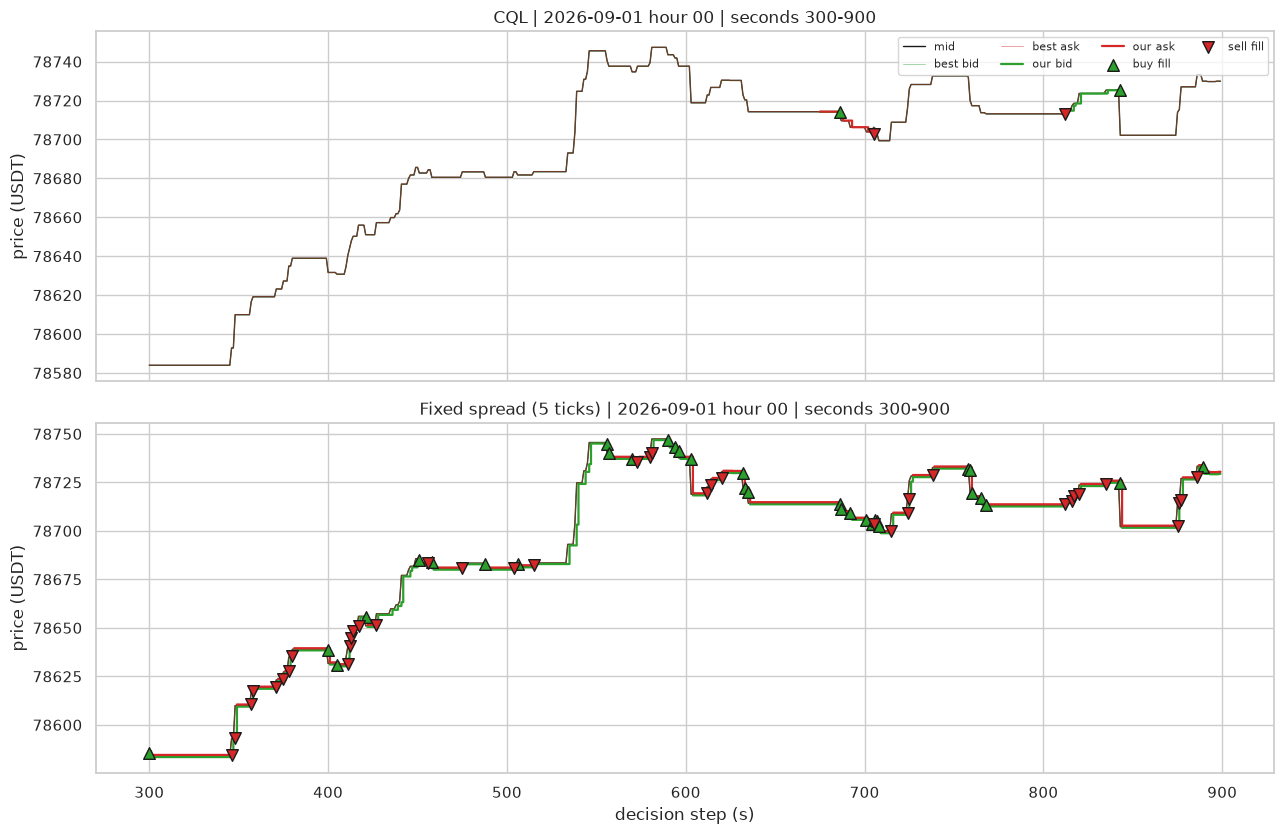

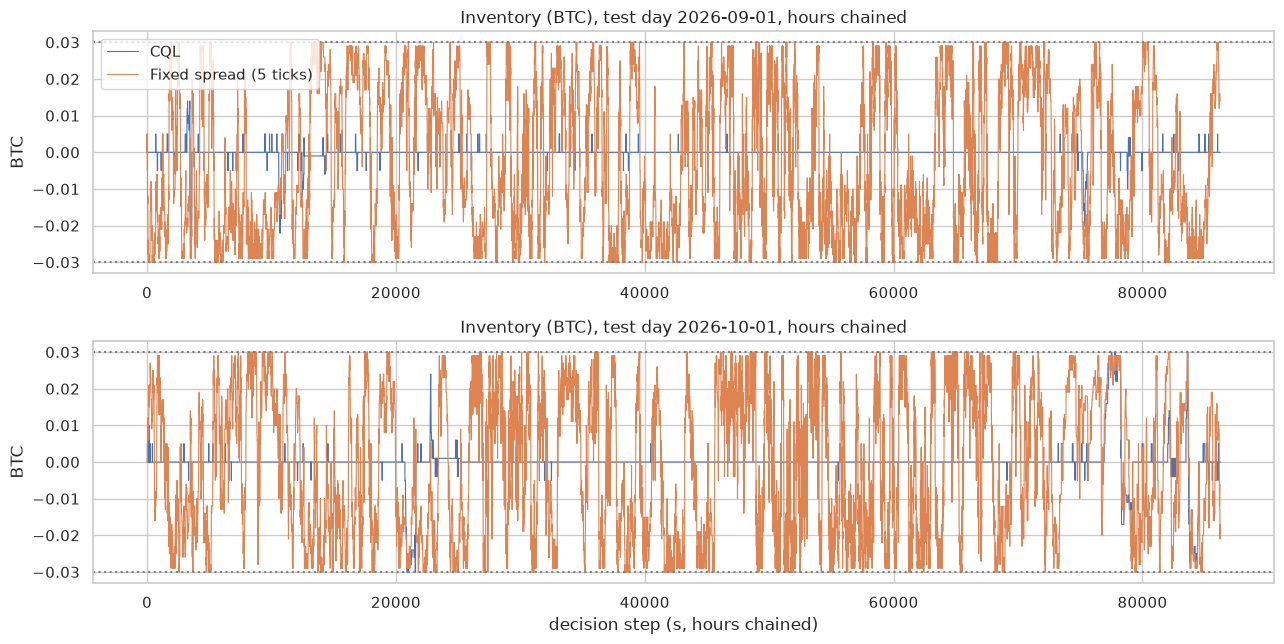

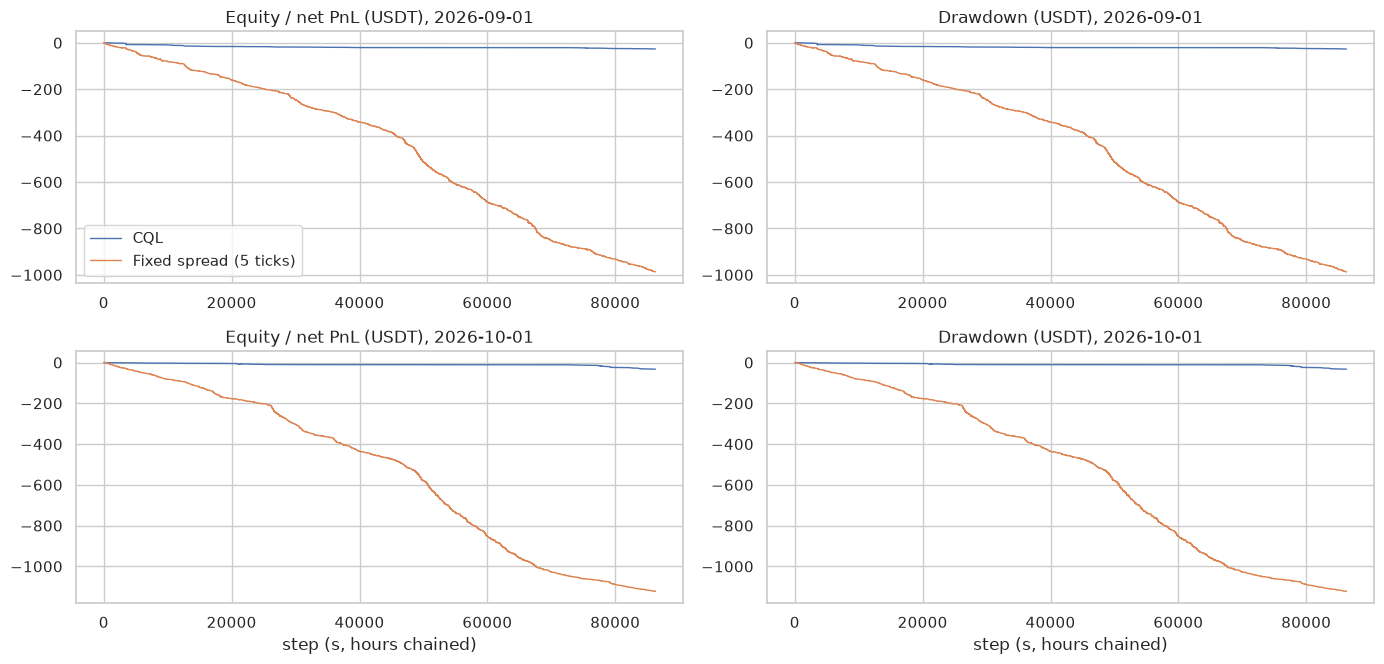

In [43]:
# ---- Plot 1: mid-price, best quotes, our quotes and fills (10-minute window of the first test episode) ----
lo, hi = 300, 900
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
for ax, (label, key) in zip(axes, STRATS.items()):
    e = TEST_EP[key][0]; x = np.arange(len(e['mid'])); sl = slice(lo, hi)
    ax.plot(x[sl], e['mid'][sl], 'k', lw=1.0, label='mid')
    ax.plot(x[sl], e['top'][sl, 0] * TICK, color='tab:green', lw=0.6, alpha=0.5, label='best bid')
    ax.plot(x[sl], e['top'][sl, 1] * TICK, color='tab:red', lw=0.6, alpha=0.5, label='best ask')
    ax.step(x[sl], e['bid'][sl], where='post', color='tab:green', lw=1.6, label='our bid')
    ax.step(x[sl], e['ask'][sl], where='post', color='tab:red', lw=1.6, label='our ask')
    fk, fs, fp = e['fill_k'], e['fill_side'], e['fill_px']; m = (fk >= lo) & (fk < hi)
    ax.scatter(fk[m & (fs > 0)], fp[m & (fs > 0)], marker='^', s=70, c='tab:green', edgecolor='k', zorder=5, label='buy fill')
    ax.scatter(fk[m & (fs < 0)], fp[m & (fs < 0)], marker='v', s=70, c='tab:red', edgecolor='k', zorder=5, label='sell fill')
    ax.set_title(f"{label} | {e['summary']['day']} hour {e['summary']['hour']:02d} | seconds {lo}-{hi}"); ax.set_ylabel('price (USDT)')
axes[0].legend(ncol=4, fontsize=8, loc='upper right'); axes[1].set_xlabel('decision step (s)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'plot1_mid_and_quotes.png', dpi=140); plt.show()

# ---- Plot 2: inventory ----
fig, axes = plt.subplots(len(DAYS_T), 1, figsize=(13, 3.3 * len(DAYS_T)), squeeze=False)
for ax, d in zip(axes[:, 0], DAYS_T):
    for label, key in STRATS.items():
        inv = np.concatenate([e['inv'][1:] for e in TEST_EP[key] if e['summary']['day'] == d])
        ax.plot(inv, lw=0.8, label=label)
    ax.axhline(MAX_INV, color='gray', ls=':'); ax.axhline(-MAX_INV, color='gray', ls=':')
    ax.set_title(f'Inventory (BTC), test day {d}, hours chained'); ax.set_ylabel('BTC')
axes[0, 0].legend(); axes[-1, 0].set_xlabel('decision step (s, hours chained)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'plot2_inventory.png', dpi=140); plt.show()

# ---- Plot 3: equity / PnL curve and drawdown ----
fig, axes = plt.subplots(len(DAYS_T), 2, figsize=(14, 3.4 * len(DAYS_T)), squeeze=False)
for i, d in enumerate(DAYS_T):
    for label, key in STRATS.items():
        curve = equity_curve([e for e in TEST_EP[key] if e['summary']['day'] == d])
        axes[i, 0].plot(curve, lw=1.0, label=label); axes[i, 1].plot(-(np.maximum.accumulate(curve) - curve), lw=1.0, label=label)
    axes[i, 0].set_title(f'Equity / net PnL (USDT), {d}'); axes[i, 1].set_title(f'Drawdown (USDT), {d}')
axes[0, 0].legend(); axes[-1, 0].set_xlabel('step (s, hours chained)'); axes[-1, 1].set_xlabel('step (s, hours chained)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'plot3_equity_drawdown.png', dpi=140); plt.show()

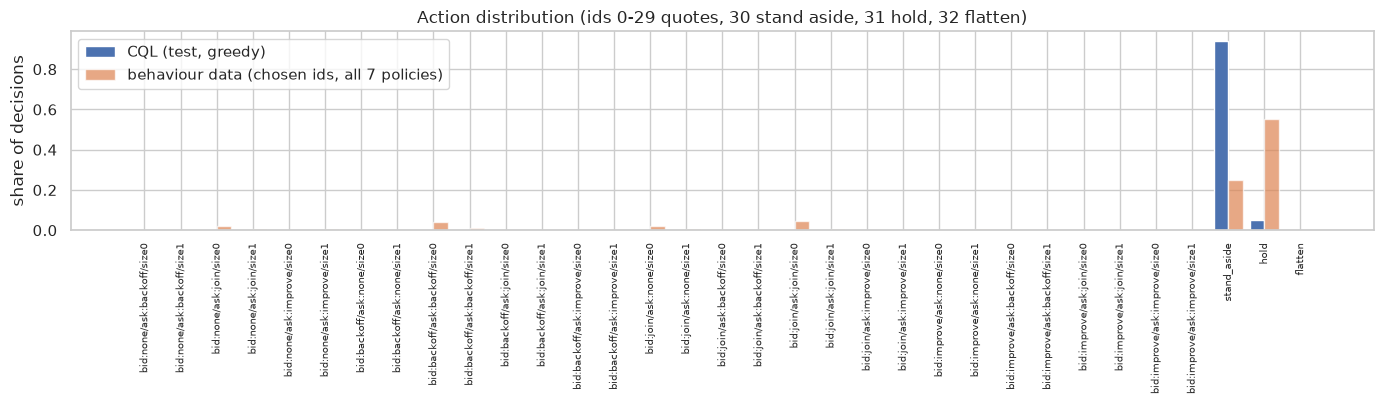

CQL: share of quote actions 0.006 | stand aside 0.941 | hold 0.053 | flatten 0.000
CQL: share of decisions whose effective action differs from the chosen one: 0.003


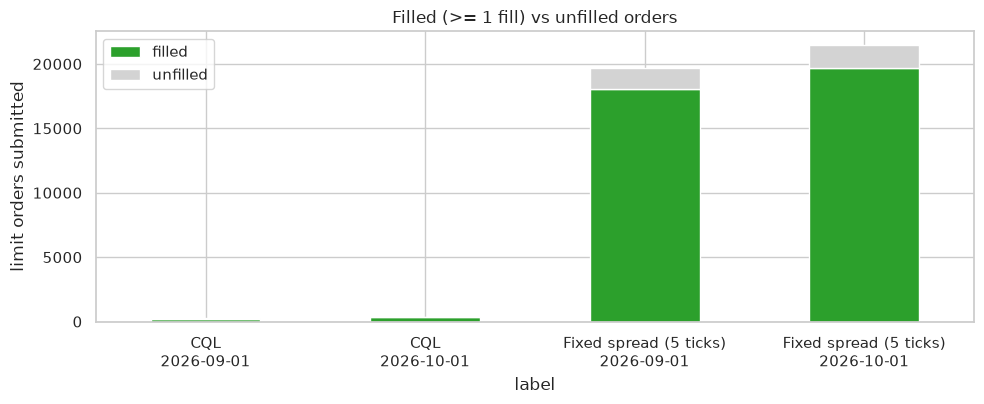

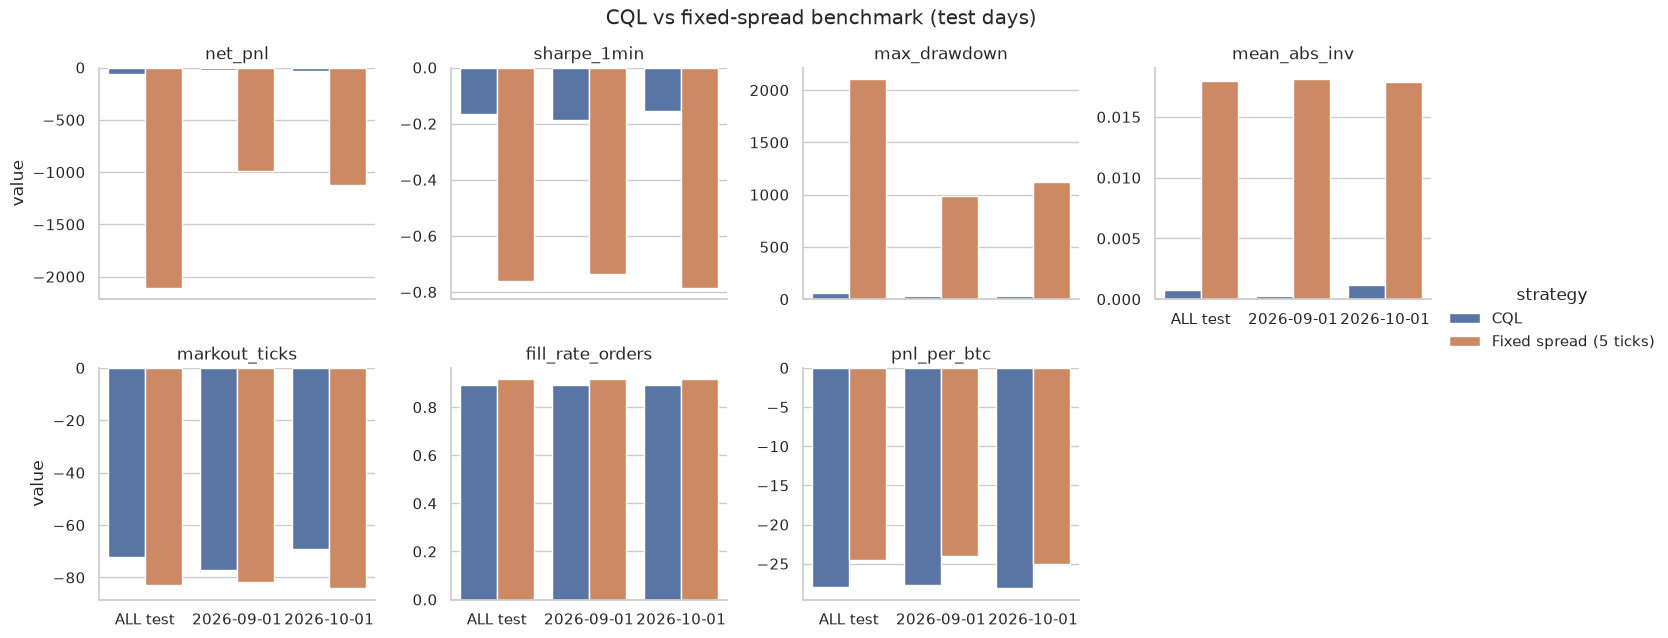

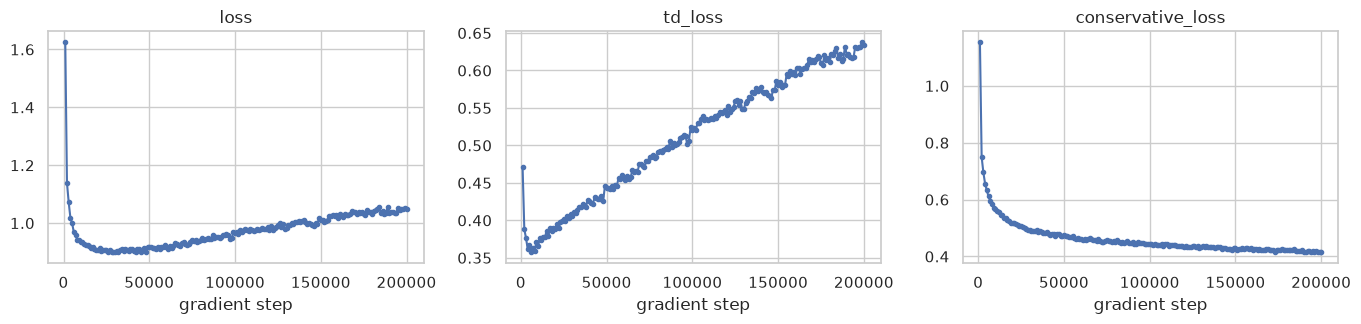

figures saved to /home/vidyadharasrikar/RL_Market_Making_Local/results/figures/full_early_checkpoint_diagnostic


In [44]:
# ---- Plot 4: CQL action distribution on the test days (chosen ids) vs behaviour-policy data ----
cql_acts = np.concatenate([e['acts'] for e in TEST_EP[KEY_CQL]]); cnt = np.bincount(cql_acts, minlength=N_ACTIONS) / len(cql_acts)
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.bar(np.arange(N_ACTIONS) - 0.2, cnt, width=0.4, label='CQL (test, greedy)')
if 'ACT_COUNTS' in globals():
    beh = sum(ACT_COUNTS[p.name] for p in POLICIES); ax.bar(np.arange(N_ACTIONS) + 0.2, beh / beh.sum(), width=0.4, label='behaviour data (chosen ids, all 7 policies)', alpha=0.7)
ax.set_xticks(range(N_ACTIONS)); ax.set_xticklabels([action_name(a) for a in range(N_ACTIONS)], rotation=90, fontsize=7); ax.set_ylabel('share of decisions'); ax.legend()
ax.set_title('Action distribution (ids 0-29 quotes, 30 stand aside, 31 hold, 32 flatten)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'plot4_action_distribution.png', dpi=140); plt.show()
print('CQL: share of quote actions %.3f | stand aside %.3f | hold %.3f | flatten %.3f' % (cnt[:N_QUOTE].sum(), cnt[A_STAND], cnt[A_HOLD], cnt[A_FLATTEN]))
eff_c = np.concatenate([e['effs'] for e in TEST_EP[KEY_CQL]]); print('CQL: share of decisions whose effective action differs from the chosen one: %.3f' % float((eff_c != cql_acts).mean()))

# ---- Plot 5: filled vs unfilled orders ----
fo = []
for label, key in STRATS.items():
    for d in DAYS_T:
        S = [e['summary'] for e in TEST_EP[key] if e['summary']['day'] == d]
        n = sum(s['n_orders'] for s in S); f_ = sum(s['n_orders_filled'] for s in S)
        fo.append(dict(strategy=label, day=d, filled=f_, unfilled=n - f_))
FO = pd.DataFrame(fo); FO['label'] = FO.strategy + '\n' + FO.day
ax = FO.set_index('label')[['filled', 'unfilled']].plot(kind='bar', stacked=True, figsize=(10, 4.2), color=['tab:green', 'lightgray'])
ax.set_ylabel('limit orders submitted'); ax.set_title('Filled (>= 1 fill) vs unfilled orders'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / 'plot5_filled_unfilled.png', dpi=140); plt.show()

# ---- Plot 6: CQL vs fixed-spread, per test day and aggregate ----
METRICS_PLOT = ['net_pnl', 'sharpe_1min', 'max_drawdown', 'mean_abs_inv', 'markout_ticks', 'fill_rate_orders', 'pnl_per_btc']
long = RES.melt(id_vars=['strategy', 'scope'], value_vars=METRICS_PLOT, var_name='metric', value_name='value')
g = sns.catplot(data=long, x='scope', y='value', hue='strategy', col='metric', kind='bar', col_wrap=4, sharey=False, height=3.2, aspect=1.15)
g.set_titles('{col_name}'); g.set_xlabels(''); g.fig.suptitle('CQL vs fixed-spread benchmark (test days)', y=1.03)
g.savefig(FIG_DIR / 'plot6_cql_vs_fixed.png', dpi=140); plt.show()

# ---- Plot 7: CQL training curves ----
_hp = MODEL_DIR / 'train_history.csv'
if _hp.exists():
    TH = pd.read_csv(_hp); cols = [c for c in ('loss', 'td_loss', 'conservative_loss') if c in TH.columns]
    fig, axes = plt.subplots(1, len(cols), figsize=(4.6 * len(cols), 3.4))
    for ax, c in zip(np.atleast_1d(axes), cols):
        ax.plot(TH.step, TH[c], marker='o', ms=3); ax.set_title(c); ax.set_xlabel('gradient step')
    fig.tight_layout(); fig.savefig(FIG_DIR / 'plot7_training_curves.png', dpi=140); plt.show()
print('figures saved to', FIG_DIR)

## 19. Literature discussion, limitations and conclusion
### 19.1 Published work (discussion only - not re-implemented, not measured here)
**No numerical result of any paper is reproduced in this notebook.** The author of this notebook could not verify reported figures against the original papers, so the third column lists what to extract from each source for a like-for-like comparison. Markets, datasets, costs and evaluation protocols differ from this notebook's (one venue, 12 single days, base-tier fees, hftbacktest risk-averse queue model), so **no claim of numerical superiority or inferiority relative to the literature is made.**

| Work | Setup and method (core idea; wording of the project brief where it is more specific) | What to take from the paper for a comparison |
|---|---|---|
| Avellaneda & Stoikov (2008) | Stochastic optimal control of a dealer's bid/ask quotes with inventory risk; closed-form *reservation price* (mid shifted against the inventory) and optimal spread under an exponential order-arrival-intensity model; no learning. | Model assumptions (price dynamics, arrival intensities), their simulated comparison with a symmetric quoting rule. Our two A-S behaviour policies are a tick-discretised, stationary-horizon implementation of the same formulas (Section 12). |
| Spooner, Fearnley, Savani & Koukorinis (2018) | Temporal-difference RL with function approximation for market making in a limit-order-book simulator built from real data; compares reward designs, including an inventory-aware (dampened) reward. | State / action / reward definitions, benchmarks, data, reported risk-adjusted outcomes. |
| Spooner & Savani (2020) | Robust market making via adversarial RL: the market maker is trained against an adversary that influences the market environment (zero-sum framing). | Adversary's action space, robustness criterion and results. Not implemented here. |
| Zhao & Linetsky (2021) | RL market making that uses the **Book Exhaustion Rate (BER)** as an adverse-selection risk signal. | Exact BER definition and results. Our `ber_*` features are only a coarse 1-second proxy (Section 7). |
| Chung et al. (2022) | Queue-aware / order-stacking deep RL for market making (as characterised in the brief). | Queue-state features and action design. Our queue feature is the displayed quantity at our price level (hftbacktest does not expose its internal queue position to Python). |
| Guo, Lin & Huang (2023) | Deep RL on limit-order-book features with a hybrid reward (as characterised in the brief). | Inputs, reward components, data and results. |
| Ragel & Challet | Consistency of historical-replay interactions: how far a replay of historical data can be trusted when the agent's own orders would have changed the market (as characterised in the brief). | Their consistency criteria versus our assumptions (negligible market impact, constant latency, risk-averse queue). |
| Kumar, Zhou, Tucker & Levine (2020) - CQL | Offline RL; a regulariser added to the Q-learning loss lowers Q-values of actions not supported by the dataset (and raises them for dataset actions), giving a conservative Q-function. The **discrete** form is what this notebook trains (`DiscreteCQL`, `alpha = 1.0`). | Their offline benchmarks are Atari and continuous-control tasks, not market making; no financial claim carries over. |

### 19.2 Limitations of this study (all also visible in the code)
* **Replay, not a live market.** hftbacktest replays recorded events; other participants do not react to our orders. Small orders (0.002 / 0.005 BTC) and negligible impact are *assumed*, not shown. Ragel & Challet-type consistency issues apply.
* **Latency and queue are assumptions:** constant 20 ms entry / 20 ms response; `risk_adverse_queue_model` (queue ahead only shrinks through trades) - conservative for passive fills.
* **Partial-fill bookkeeping:** hftbacktest 2.4.4 was observed to update its own `position` only on the final fill of an order and to record only the last level of a large market order; therefore all accounting uses the notebook's own ledger (`leaves_qty` deltas) and market orders are capped at the displayed top-level quantity. hftbacktest's own position/balance are reported only as a diagnostic.
* **Queue position proxy** = displayed quantity at our level; BER and OFI are computed from 1-second samples, not from every event.
* **Fees dominate the spread:** with maker fees of 2 bps per fill and quotes one tick from the mid on each side, a passive round trip captures about 2 ticks (~0.02 bps at a 100,000 USDT mid) but pays about 4 bps in maker fees, roughly 200x the quoted spread capture. Losses are therefore plausible under this fee assumption; verify the actual account fee tier before interpreting results.
* **Data:** 12 single days (the first of 12 consecutive months - the key-free Tardis samples), 8 train / 2 validation / 2 test, one venue (Binance USDT-M perpetual). Day-level variation (regime, weekday, funding times) is large relative to the sample; hourly episodes within a day are serially dependent.
* **Tardis incremental L2 has no sequence ids**; gaps are proxied by time gaps. Quantities outside the lot grid or prices outside the tick grid are only reported in the inspection step.
* **Action mapping:** the 33-action grid cannot express 3- vs 5-tick spreads (both back-off-2); behaviour diversity comes from quote persistence. The benchmark quotes exact tick distances and is therefore not restricted to the grid.
* **Offline RL risks:** distribution shift between the behaviour data and the greedy CQL policy, limited coverage of rare actions (Flatten), reward weights calibrated by a heuristic rule (`ρ = 0.5`), single training seed, no hyper-parameter search beyond three checkpoints.
* **Statistical power:** two test days; the bootstrap interval is indicative only.
* **What was executed by the author before delivery:** hftbacktest 2.4.4 mechanics (queue, partial fills, market orders, cancel/modify) and a `DiscreteCQL` fit/save/reload on random data were probed in a sandbox; the notebook itself, the Tardis download and every result were **not** executed by the author. Your first run is the first execution of the full pipeline.

In [45]:
# ---- 19.3 data-driven conclusion (every number comes from the cells above) ----
def _g(df, strat, col):
    return float(df[(df.strategy == strat) & (df.scope == 'ALL test')][col].iloc[0])
cq, bm = LABELS[0], LABELS[1]
lines = []
mode_txt = 'PILOT run (plumbing check on a tiny slice - NOT evidence about the method)' if RUN_MODE == 'pilot' else 'full run'
lines.append(f"[{mode_txt}] {len(TEST_COMMON)} hourly test episodes on {', '.join(DAYS_T)}; CQL = checkpoint {SEL['cql_step']}, benchmark = fixed spread {SEL['benchmark_hs']} ticks (both frozen on validation).")
lines.append(f"Net PnL after costs: CQL {_g(RES, cq, 'net_pnl'):+.2f} USDT vs {bm} {_g(RES, bm, 'net_pnl'):+.2f} USDT; mean per-hour difference {BOOT['mean_diff_per_hour']:+.3f} USDT, paired-bootstrap 95% interval "
             f"[{BOOT['ci95'][0]:+.3f}, {BOOT['ci95'][1]:+.3f}] ({'includes' if BOOT['ci95'][0] <= 0 <= BOOT['ci95'][1] else 'excludes'} zero; indicative only).")
lines.append(f"Risk: Sharpe (1-min, non-annualised) {_g(RES, cq, 'sharpe_1min'):.3f} vs {_g(RES, bm, 'sharpe_1min'):.3f}; max drawdown {_g(RES, cq, 'max_drawdown'):.2f} vs {_g(RES, bm, 'max_drawdown'):.2f} USDT; "
             f"mean |inventory| {_g(RES, cq, 'mean_abs_inv'):.4f} vs {_g(RES, bm, 'mean_abs_inv'):.4f} BTC.")
lines.append(f"Execution quality: 5 s mark-out per passive fill {_g(RES, cq, 'markout_ticks'):.2f} vs {_g(RES, bm, 'markout_ticks'):.2f} ticks; order fill rate {_g(RES, cq, 'fill_rate_orders'):.3f} vs {_g(RES, bm, 'fill_rate_orders'):.3f}; "
             f"PnL per BTC traded {_g(RES, cq, 'pnl_per_btc'):.2f} vs {_g(RES, bm, 'pnl_per_btc'):.2f} USDT; fees paid {_g(RES, cq, 'fees'):.2f} vs {_g(RES, bm, 'fees'):.2f} USDT.")
qf = _g(RES, cq, 'quoting_frac')
lines.append(f"Never-quote monitor: CQL quotes in {100 * qf:.1f}% of decisions" + (' - BELOW the monitoring floor: the policy is close to "never quote", so a PnL near zero reflects inactivity, not skill.' if qf < CFG['min_quoting_frac'] else '.'))
if _g(RES, cq, 'net_pnl') < 0 and _g(RES, bm, 'net_pnl') < 0:
    lines.append('Both strategies lose money after costs. With the base-tier maker fee (2 bps) far above the tick spread this is the expected outcome of the fee assumption (see 19.2), not necessarily an implementation defect; the relative comparison is still meaningful only in the sense of smaller losses at equal conditions.')
lines.append('Literature: published results are not comparable to these numbers (different markets, data, costs, protocols) and none are claimed here.')
CONCLUSION = '\n'.join(lines)
print(CONCLUSION)
open(MET_DIR / 'conclusion.txt', 'w').write(CONCLUSION)

RUN_REPORT = dict(run_mode=RUN_MODE, finished_at=dt.datetime.utcnow().isoformat() + 'Z', versions=VERS, device=DEVICE, days=dict(train=GEN_DAYS, val=VAL_DAYS[:RUN['eval_days_val']], test=sorted({d for d, _ in TEST_COMMON})),
                  behaviour_episodes=int(sum(POLICY_DF.episodes)), transitions=int(TOTAL_TRANSITIONS), cql_total_steps=TOTAL_STEPS, selection=dict(cql_step=SEL['cql_step'], benchmark_hs=SEL['benchmark_hs']),
                  test_episodes=len(TEST_COMMON), lam=LAM, reward_scale=REWARD_SCALE, protocol=PROTOCOL, bootstrap=BOOT)
json.dump(RUN_REPORT, open(MET_DIR / 'run_report.json', 'w'), indent=1, default=_json_default)
print('run report saved to', MET_DIR / 'run_report.json')

[full run] 48 hourly test episodes on 2026-09-01, 2026-10-01; CQL = checkpoint 200000, benchmark = fixed spread 5 ticks (both frozen on validation).
Net PnL after costs: CQL -59.40 USDT vs Fixed spread (5 ticks) -2110.16 USDT; mean per-hour difference +42.724 USDT, paired-bootstrap 95% interval [+35.628, +49.925] (excludes zero; indicative only).
Risk: Sharpe (1-min, non-annualised) -0.164 vs -0.761; max drawdown 59.40 vs 2110.16 USDT; mean |inventory| 0.0007 vs 0.0180 BTC.
Execution quality: 5 s mark-out per passive fill -72.34 vs -83.01 ticks; order fill rate 0.890 vs 0.917; PnL per BTC traded -27.99 vs -24.52 USDT; fees paid 36.66 vs 1413.40 USDT.
Never-quote monitor: CQL quotes in 5.7% of decisions.
Both strategies lose money after costs. With the base-tier maker fee (2 bps) far above the tick spread this is the expected outcome of the fee assumption (see 19.2), not necessarily an implementation defect; the relative comparison is still meaningful only in the sense of smaller losses

/tmp/ipykernel_849/1344260189.py:23: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  RUN_REPORT = dict(run_mode=RUN_MODE, finished_at=dt.datetime.utcnow().isoformat() + 'Z', versions=VERS, device=DEVICE, days=dict(train=GEN_DAYS, val=VAL_DAYS[:RUN['eval_days_val']], test=sorted({d for d, _ in TEST_COMMON})),
